# Tokenization and akshara-level predictability in Indian languages — final notebook (v9)

This one notebook reproduces every result of the project, from scratch:

| Part | What it does | Runtime (Kaggle T4) |
|---|---|---|
| Tokenizer audit | How 21 tokenizers cut words in 8 Indian languages (tokenizer files only) | ~15 min, CPU |
| Experiment | Surprisal from pretrained LMs on 1,000 XL-Sum texts per language, measured per word, token, character and akshara, with calibrated controls | ~1.5–2 h per language |
| Final findings | Cross-language tables, figures, findings with per-language verdicts, and a check against the reference run | ~5 min, CPU |
| MECO reading times | Hindi eye-tracking (MECO Wave 2): native ruler check, surprisal predictive power, split-word errors | ~20–30 min |

Models: **Hindi** gpt2-hindi, mGPT, BLOOM (+ XGLM-564M, Sarvam-1) · **Bengali** gpt2-bengali, mGPT, BLOOM (+ XGLM-564M, Sarvam-1) · **Marathi** mGPT, BLOOM (+ Sarvam-1). The original models' revisions are pinned; the extra models' revisions are recorded in each `run_meta.json`. Seeds are fixed.

**What changed in v9**
1. No credentials in the notebook: the Hugging Face token is read from a secret named `HF_TOKEN`.
2. Clean run by default (`RESTORE_FROM = ""`), so the reproducibility check compares a genuinely new run with the reference values.
3. Scale control for the per-akshara vs per-character comparison (`FINAL/table_scale_control.csv`): each unit gets its own best length exponent before comparing. This is now the primary version of that finding.
4. Verdicts are per language instead of counts of correlated tests. Low-power boundary tests are labelled inconclusive; the split penalty is labelled exploratory.
5. Extra scorers with learned-subword tokenizers (XGLM-564M, Sarvam-1), so tokenizer quality is no longer confounded with BLOOM. SentencePiece tokenizers are handled correctly in the word-boundary correction.
6. MECO: confidence intervals bootstrap over passages (12 clusters) instead of words; the extra models are included.

**How to run (recommended: Kaggle, so it runs in the background)**
1. Settings ▸ Accelerator: **GPU T4 x2** (the extra models go on the second GPU; with one GPU they run in float16). Settings ▸ Internet: on.
2. Add-ons ▸ Secrets ▸ add `HF_TOKEN` (a *new* token). Optional: on huggingface.co accept the licences of the gated repos you want (Llama/Gemma for the audit, Sarvam-1 if it asks). Anything you cannot access is skipped.
3. *Save Version* ▸ *Save & Run All (Commit)*. Total runtime ≈ 6–7 h, within Kaggle's 12 h limit. Come back and download `mtp_final_results.zip` from the version's Output tab.
   (On Colab: Runtime ▸ Run all with `USE_DRIVE = True`; finished parts are skipped after a disconnect.)

**Report only (no GPU):** set `RESTORE_FROM` to a results folder or zip, and run all; steps 2–3 skip and step 4 rebuilds the findings.

**Code layout:** the cells below write five modules and then run them.
`mtp_common.py` (scripts, akshara segmenter, language profiles) · `mtp_pipeline.py` (the experiment for one language) · `mtp_audit.py` (tokenizer audit) · `mtp_report.py` (final findings) · `mtp_meco.py` (MECO reading-time analysis).


In [1]:
!pip install -q "datasets==2.21.0" "transformers==5.16.1" accelerate sentencepiece protobuf scipy pandas matplotlib pyreadr uharfbuzz

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.


In [2]:
# ============================== SETTINGS ==============================
import os, sys, json, glob, shutil, subprocess, importlib, time

LANGS         = ["hindi", "bengali", "marathi"]   # languages of the experiment
NUM_SAMPLES   = 1000      # texts per language (the reported results use 1000)
RUN_AUDIT     = True      # tokenizer audit (CPU, ~15 min)
RUN_MISSING   = True      # compute every language / audit whose results are missing
RUN_MECO      = True      # MECO Hindi reading-time analysis (GPU, ~20 min; downloads ~40 MB from OSF)
EXTRA_SCORERS = True      # v9: also score with XGLM-564M (Hindi, Bengali) and Sarvam-1 (all three languages).
                          # Both use learned-subword tokenizers, so "good tokenizer" is no longer the same thing
                          # as "BLOOM". A model that cannot be loaded is skipped; the original three are unaffected.
USE_DRIVE     = False     # True: keep results in Google Drive so they survive a disconnect
RESTORE_FROM  = ""        # v9: empty = clean run from scratch. Only set this to rebuild the report from old results.
FORCE_RERUN   = []        # e.g. ["hindi", "audit", "meco"]: recompute these even if results exist

CODE_DIR = os.getcwd()
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/mtp_final"
else:
    BASE_DIR = os.path.join(CODE_DIR, "mtp_final")
os.makedirs(BASE_DIR, exist_ok=True)
if RESTORE_FROM and not os.path.exists(os.path.join(BASE_DIR, "run_hindi")):
    if os.path.isdir(RESTORE_FROM):                 # Kaggle unzips uploaded datasets automatically
        src_dir = RESTORE_FROM
        inner = [d for d in glob.glob(os.path.join(RESTORE_FROM, "**", "run_hindi"), recursive=True)]
        if inner: src_dir = os.path.dirname(inner[0])
        shutil.copytree(src_dir, BASE_DIR, dirs_exist_ok=True)
    else:
        shutil.unpack_archive(RESTORE_FROM, BASE_DIR)
    print("restored earlier results from", RESTORE_FROM, "(the reproducibility check is NOT independent in this mode)")

# v9: the Hugging Face token is never written in the notebook. Add a secret named HF_TOKEN
# (Kaggle: Add-ons > Secrets; Colab: key icon). It is only needed for gated repositories
# (Llama/Gemma tokenizers in the audit, and Sarvam-1 if its licence must be accepted).
def _hf_token():
    if os.environ.get("HF_TOKEN"): return os.environ["HF_TOKEN"]
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception: pass
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception: pass
    return None
_tok = _hf_token()
if _tok: os.environ["HF_TOKEN"] = _tok
os.environ["MTP_EXTRA"] = "1" if EXTRA_SCORERS else "0"
print("results folder:", BASE_DIR, "| HF token:", "found" if _tok else "not set (gated rows are skipped)",
      "| extra scorers:", EXTRA_SCORERS)


results folder: /kaggle/working/mtp_final | HF token: found | extra scorers: True


## Code
The five modules. Read them here; they are written to disk and imported or run below.

In [3]:
%%writefile mtp_common.py
"""mtp_common: scripts, akshara segmenter, hand-checked gold segmentations, language profiles.
Shared by the pipeline (mtp_pipeline.py), the tokenizer audit and the final report."""
import re, unicodedata

# ===================== SCRIPTS & AKSHARA SEGMENTER (v7: any Brahmic script) =====================
# The Unicode blocks of the Indian Brahmic scripts share one layout, so one rule-based
# segmenter covers all of them. Character classes are read from the Unicode database
# (category + name), with a few per-script extras. Akshara definition (unchanged from v6):
#   (C NUKTA? VIRAMA)* C NUKTA? VIRAMA? (VOWEL SIGN | MODIFIER | NUKTA)*  |  V MODIFIER*
# Tamil does not form conjuncts in writing, so there a virama ENDS the akshara (க்|ஷ).
SCRIPTS = {
    #             block start  conjuncts  extra consonants / independent letters (offsets in block)
    "devanagari": dict(base=0x0900, joins=True,  cons=range(0x78, 0x80), indep=range(0x72, 0x78)),
    "bengali":    dict(base=0x0980, joins=True,  cons=(0x70, 0x71),      indep=(0x4E,)),   # ৎ khanda ta = own unit
    "gurmukhi":   dict(base=0x0A00, joins=True,  cons=(),                indep=(0x72, 0x73)),
    "gujarati":   dict(base=0x0A80, joins=True,  cons=(0x79,),           indep=()),
    "tamil":      dict(base=0x0B80, joins=False, cons=(),                indep=(0x03,)),   # ஃ aytham
    "telugu":     dict(base=0x0C00, joins=True,  cons=(),                indep=()),
}
LANG_SCRIPT = {"hindi": "devanagari", "marathi": "devanagari", "nepali": "devanagari",
               "bengali": "bengali", "punjabi": "gurmukhi", "gujarati": "gujarati",
               "tamil": "tamil", "telugu": "telugu"}

class ScriptSpec:
    def __init__(self, name):
        sp = SCRIPTS[name]; self.name, self.base, self.joins = name, sp["base"], sp["joins"]
        self.cons, self.vowel, self.dep, self.mod = set(), set(), set(), set()
        self.virama = self.nukta = None
        word_chars, marks = [], []
        for cp in range(self.base, self.base + 0x80):
            ch = chr(cp); cat = unicodedata.category(ch); nm = unicodedata.name(ch, ""); off = cp - self.base
            if cat in ("Mn", "Mc"):
                marks.append(ch); word_chars.append(ch)
                if nm.endswith("SIGN VIRAMA"):                     self.virama = ch
                elif "SIGN NUKTA" in nm:                           self.nukta = ch
                elif "VOWEL SIGN" in nm or "LENGTH MARK" in nm:   self.dep.add(ch)
                else:                                              self.mod.add(ch)  # anusvara, candrabindu, visarga, addak, tippi …
            elif cat in ("Lo", "Lm"):
                word_chars.append(ch)
                if cat == "Lo" and (0x15 <= off <= 0x39 or 0x58 <= off <= 0x5F or off in sp["cons"]):
                    self.cons.add(ch)
                elif cat == "Lo" and (0x04 <= off <= 0x14 or off in (0x60, 0x61) or off in sp["indep"]):
                    self.vowel.add(ch)
        cls = "".join(re.escape(c) for c in word_chars)
        self.word_re = re.compile(f"[{cls}]+")                    # a word = a run of script letters/marks
        self.char_re = re.compile(f"[{cls}]")
        self.mark_re = re.compile("[" + "".join(re.escape(c) for c in marks) + "]")
        # 2nd UTF-8 byte of this block's code points (for byte-fragment tokens)
        self.byte2 = {0x80 | ((cp >> 6) & 0x3F) for cp in range(self.base, self.base + 0x80)}

    def spans(self, text):
        out, i, n = [], 0, len(text)
        C, V, DEP, MOD, VIR, NUK = self.cons, self.vowel, self.dep, self.mod, self.virama, self.nukta
        while i < n:
            c = text[i]
            if c in C:
                j = i + 1
                while True:
                    while j < n and text[j] == NUK: j += 1
                    if self.joins and j + 1 < n and text[j] == VIR and text[j + 1] in C:
                        j += 2; continue                          # conjunct: keep going
                    break
                if j < n and text[j] == VIR: j += 1              # explicit virama at the end
                while j < n and (text[j] in DEP or text[j] in MOD or text[j] == NUK): j += 1
                out.append((i, j)); i = j
            elif c in V:
                j = i + 1
                while j < n and text[j] in MOD: j += 1
                out.append((i, j)); i = j
            else:
                i += 1
        return out

GOLD_HINDI = {
    # original 15
    "देश": ["दे", "श"], "राजधानी": ["रा", "ज", "धा", "नी"], "दिल्ली": ["दि", "ल्ली"],
    "नमस्ते": ["न", "म", "स्ते"], "विश्वविद्यालय": ["वि", "श्व", "वि", "द्या", "ल", "य"],
    "भारत": ["भा", "र", "त"], "पैंथर": ["पैं", "थ", "र"],
    "अफ़ग़ानिस्तान": ["अ", "फ़", "ग़ा", "नि", "स्ता", "न"], "इंसाफ़": ["इं", "सा", "फ़"],
    "उदघाटन": ["उ", "द", "घा", "ट", "न"], "स्त्री": ["स्त्री"], "हँसना": ["हँ", "स", "ना"],
    "दुःख": ["दुः", "ख"], "क्या": ["क्या"], "ऑफ़िस": ["ऑ", "फ़ि", "स"],
    # plain consonant + matra
    "कमल": ["क", "म", "ल"], "घर": ["घ", "र"], "पानी": ["पा", "नी"], "किताब": ["कि", "ता", "ब"],
    "सरकार": ["स", "र", "का", "र"], "कुछ": ["कु", "छ"], "शहर": ["श", "ह", "र"],
    "चुनाव": ["चु", "ना", "व"], "पुलिस": ["पु", "लि", "स"], "रुपये": ["रु", "प", "ये"],
    "अमरीका": ["अ", "म", "री", "का"], "पाकिस्तान": ["पा", "कि", "स्ता", "न"],
    # independent vowels
    "आदमी": ["आ", "द", "मी"], "ईमानदार": ["ई", "मा", "न", "दा", "र"], "ऊपर": ["ऊ", "प", "र"],
    "ऐसा": ["ऐ", "सा"], "औरत": ["औ", "र", "त"], "ओर": ["ओ", "र"], "एक": ["ए", "क"],
    "ऋषि": ["ऋ", "षि"], "ऋतु": ["ऋ", "तु"], "आई": ["आ", "ई"], "गए": ["ग", "ए"],
    "हुआ": ["हु", "आ"], "कई": ["क", "ई"], "भाई": ["भा", "ई"], "नई": ["न", "ई"],
    "जाएगा": ["जा", "ए", "गा"], "रुपए": ["रु", "प", "ए"],
    # vocalic r matra
    "कृपया": ["कृ", "प", "या"], "हृदय": ["हृ", "द", "य"], "कृषि": ["कृ", "षि"],
    "तृतीय": ["तृ", "ती", "य"],
    # conjuncts
    "बच्चा": ["ब", "च्चा"], "अच्छा": ["अ", "च्छा"], "उत्तर": ["उ", "त्त", "र"],
    "प्रधानमंत्री": ["प्र", "धा", "न", "मं", "त्री"], "राष्ट्रपति": ["रा", "ष्ट्र", "प", "ति"],
    "महाराष्ट्र": ["म", "हा", "रा", "ष्ट्र"], "ज्ञान": ["ज्ञा", "न"], "क्षेत्र": ["क्षे", "त्र"],
    "श्रीमती": ["श्री", "म", "ती"], "त्योहार": ["त्यो", "हा", "र"], "मंत्रालय": ["मं", "त्रा", "ल", "य"],
    "विद्यार्थी": ["वि", "द्या", "र्थी"], "स्वास्थ्य": ["स्वा", "स्थ्य"], "स्थिति": ["स्थि", "ति"],
    "द्वारा": ["द्वा", "रा"], "पत्नी": ["प", "त्नी"], "सूर्य": ["सू", "र्य"], "धर्म": ["ध", "र्म"],
    "कर्मचारी": ["क", "र्म", "चा", "री"], "पर्यावरण": ["प", "र्या", "व", "र", "ण"],
    "प्रदेश": ["प्र", "दे", "श"], "ट्रेन": ["ट्रे", "न"], "स्कूल": ["स्कू", "ल"],
    "प्रतिशत": ["प्र", "ति", "श", "त"], "अर्थव्यवस्था": ["अ", "र्थ", "व्य", "व", "स्था"],
    "स्वतंत्रता": ["स्व", "तं", "त्र", "ता"], "जम्मू": ["ज", "म्मू"], "कश्मीर": ["क", "श्मी", "र"],
    "न्यायालय": ["न्या", "या", "ल", "य"], "ध्यान": ["ध्या", "न"], "द्विवेदी": ["द्वि", "वे", "दी"],
    "उन्होंने": ["उ", "न्हों", "ने"], "क्योंकि": ["क्यों", "कि"], "अर्ध": ["अ", "र्ध"],
    "डॉक्टर": ["डॉ", "क्ट", "र"], "हिन्दी": ["हि", "न्दी"],
    # anusvara / chandrabindu / visarga
    "संसद": ["सं", "स", "द"], "हिंदी": ["हिं", "दी"], "सिंह": ["सिं", "ह"], "बैंक": ["बैं", "क"],
    "मैं": ["मैं"], "हैं": ["हैं"], "गाँव": ["गाँ", "व"], "चाँद": ["चाँ", "द"],
    "आँख": ["आँ", "ख"], "हँसी": ["हँ", "सी"], "कहाँ": ["क", "हाँ"], "अतः": ["अ", "तः"],
    "प्रातः": ["प्रा", "तः"], "इंडिया": ["इं", "डि", "या"], "अंग्रेज़ी": ["अं", "ग्रे", "ज़ी"],
    # nukta
    "ज़िंदगी": ["ज़िं", "द", "गी"], "फ़िल्म": ["फ़ि", "ल्म"], "क़ानून": ["क़ा", "नू", "न"],
    "ग़रीब": ["ग़", "री", "ब"], "ख़बर": ["ख़", "ब", "र"], "ज़्यादा": ["ज़्या", "दा"],
    "बड़ा": ["ब", "ड़ा"], "पढ़ाई": ["प", "ढ़ा", "ई"], "लड़की": ["ल", "ड़", "की"],
    "सड़क": ["स", "ड़", "क"],
    # loanword vowel ऑ / ॉ
    "ऑफ़": ["ऑ", "फ़"], "कॉलेज": ["कॉ", "ले", "ज"],
    # word-final halant
    "वाक्": ["वा", "क्"], "जगत्": ["ज", "ग", "त्"],
}

GOLD_MARATHI = {   # Devanagari, Marathi-specific letters and spellings
    "आणि": ["आ", "णि"], "मुंबई": ["मुं", "ब", "ई"], "पुणे": ["पु", "णे"], "मिळाले": ["मि", "ळा", "ले"],
    "शाळा": ["शा", "ळा"], "ॲप": ["ॲ", "प"], "झाले": ["झा", "ले"], "त्यांनी": ["त्यां", "नी"],
    "करण्यात": ["क", "र", "ण्या", "त"], "निवडणूक": ["नि", "व", "ड", "णू", "क"], "मराठी": ["म", "रा", "ठी"],
    "दुसऱ्या": ["दु", "स", "ऱ्या"],
}
GOLD_BENGALI = {
    "বাংলা": ["বাং", "লা"], "ভারত": ["ভা", "র", "ত"], "দেশ": ["দে", "শ"], "সরকার": ["স", "র", "কা", "র"],
    "প্রধানমন্ত্রী": ["প্র", "ধা", "ন", "ম", "ন্ত্রী"], "বিশ্ববিদ্যালয়": ["বি", "শ্ব", "বি", "দ্যা", "ল", "য়"],
    "ক্ষমতা": ["ক্ষ", "ম", "তা"], "রাষ্ট্রপতি": ["রা", "ষ্ট্র", "প", "তি"], "উৎসব": ["উ", "ৎ", "স", "ব"],
    "ভবিষ্যৎ": ["ভ", "বি", "ষ্য", "ৎ"], "আমি": ["আ", "মি"], "তিনি": ["তি", "নি"], "কর্মী": ["ক", "র্মী"],
    "চাঁদ": ["চাঁ", "দ"], "দুঃখ": ["দুঃ", "খ"], "হয়েছে": ["হ", "য়ে", "ছে"], "বড়": ["ব", "ড়"],
    "পড়াশোনা": ["প", "ড়া", "শো", "না"], "ঐতিহ্য": ["ঐ", "তি", "হ্য"], "ঔষধ": ["ঔ", "ষ", "ধ"],
    "ঋণ": ["ঋ", "ণ"], "কৃষি": ["কৃ", "ষি"], "স্বাস্থ্য": ["স্বা", "স্থ্য"], "নির্বাচন": ["নি", "র্বা", "চ", "ন"],
    "আন্দোলন": ["আ", "ন্দো", "ল", "ন"], "পুলিশ": ["পু", "লি", "শ"], "ঢাকা": ["ঢা", "কা"],
    "সংসদ": ["সং", "স", "দ"], "যুক্তরাষ্ট্র": ["যু", "ক্ত", "রা", "ষ্ট্র"], "ইংরেজি": ["ইং", "রে", "জি"],
    "গ্রাম": ["গ্রা", "ম"], "সৌদি": ["সৌ", "দি"], "কোভিড": ["কো", "ভি", "ড"], "জ্ঞান": ["জ্ঞা", "ন"],
    "শিক্ষার্থী": ["শি", "ক্ষা", "র্থী"], "অর্থনীতি": ["অ", "র্থ", "নী", "তি"], "মৃত্যু": ["মৃ", "ত্যু"],
    "ব্যবসা": ["ব্য", "ব", "সা"],
}
GOLD_GURMUKHI = {
    "ਪੰਜਾਬ": ["ਪੰ", "ਜਾ", "ਬ"], "ਸਰਕਾਰ": ["ਸ", "ਰ", "ਕਾ", "ਰ"], "ਪ੍ਰਧਾਨ": ["ਪ੍ਰ", "ਧਾ", "ਨ"],
    "ਪੱਕਾ": ["ਪੱ", "ਕਾ"], "ਸਿੰਘ": ["ਸਿੰ", "ਘ"], "ਖ਼ਬਰ": ["ਖ਼", "ਬ", "ਰ"], "ਇੰਡੀਆ": ["ਇੰ", "ਡੀ", "ਆ"],
}
GOLD_GUJARATI = {
    "ગુજરાત": ["ગુ", "જ", "રા", "ત"], "પ્રધાનમંત્રી": ["પ્ર", "ધા", "ન", "મં", "ત્રી"],
    "સરકાર": ["સ", "ર", "કા", "ર"], "અમદાવાદ": ["અ", "મ", "દા", "વા", "દ"], "શિક્ષણ": ["શિ", "ક્ષ", "ણ"],
    "ચૂંટણી": ["ચૂં", "ટ", "ણી"],
}
GOLD_TAMIL = {
    "தமிழ்நாடு": ["த", "மி", "ழ்", "நா", "டு"], "இந்தியா": ["இ", "ந்", "தி", "யா"], "அரசு": ["அ", "ர", "சு"],
    "சென்னை": ["செ", "ன்", "னை"], "கொரோனா": ["கொ", "ரோ", "னா"], "ஃபேஸ்புக்": ["ஃ", "பே", "ஸ்", "பு", "க்"],
    "பள்ளி": ["ப", "ள்", "ளி"], "மக்கள்": ["ம", "க்", "க", "ள்"],
}
GOLD_TELUGU = {
    "తెలుగు": ["తె", "లు", "గు"], "ప్రభుత్వం": ["ప్ర", "భు", "త్వం"], "హైదరాబాద్": ["హై", "ద", "రా", "బా", "ద్"],
    "ఆంధ్రప్రదేశ్": ["ఆం", "ధ్ర", "ప్ర", "దే", "శ్"], "ఎన్నికలు": ["ఎ", "న్ని", "క", "లు"], "రాష్ట్రం": ["రా", "ష్ట్రం"],
}
GOLD_BY_SCRIPT = {"devanagari": {**GOLD_HINDI, **GOLD_MARATHI}, "bengali": GOLD_BENGALI,
                  "gurmukhi": GOLD_GURMUKHI, "gujarati": GOLD_GUJARATI, "tamil": GOLD_TAMIL, "telugu": GOLD_TELUGU}
SPECS = {name: ScriptSpec(name) for name in SCRIPTS}

def validate_script(name, verbose=True):
    sp, N = SPECS[name], (lambda s: unicodedata.normalize("NFC", s))
    gold = GOLD_BY_SCRIPT[name]
    bad = {}
    for w, g in gold.items():
        got = [N(w)[a:b] for a, b in sp.spans(N(w))]
        if got != [N(x) for x in g]: bad[w] = (g, got)
    if verbose:
        print(f"akshara segmenter [{name}]: {len(gold) - len(bad)}/{len(gold)} exact")
        for w, (g, got) in bad.items(): print(f"  MISMATCH {w}: gold={g} got={got}")
    return not bad


def validate_all(verbose=True):
    return all(validate_script(s, verbose) for s in SCRIPTS)

# ---------------------------------------------------------------------------
# Language profiles: scoring models (revisions pinned), probe words, function words
# RULE_SCORERS: tokenizers whose GPT-2-style pre-tokenizer cuts off every combining mark.
# Every other scorer has a learned-subword tokenizer (BLOOM, XGLM, Sarvam-1).
RULE_SCORERS = ("gpt2-hindi", "gpt2-bengali", "mGPT")
# ---------------------------------------------------------------------------
HINDI_FUNC = set("""के में है की को से ने और का कि पर हैं भी यह इस एक था थी थे लिए तो
नहीं हो कर गया गई गए साथ बाद वह उन उनके उसके इसके उनकी उसकी इसकी उनका उसका इसका रहा रही रहे
जो किया कहा ही वे अपने अपनी अपना तक हुए हुई हुआ होने करने करते करता करती या इन उस जा जाता जाती
जाते जाए जाएगा सकता सकती सकते रूप ये वो कुछ सभी अब जब तब यहाँ वहाँ लेकिन मगर किसी कोई होता
होती होते बहुत ना न दिया दी दे कई""".split())

LANG_PROFILES = {
    "hindi":   dict(models=("surajp/gpt2-hindi", "ai-forever/mGPT", "bigscience/bloom-560m"),
                    revisions={"surajp/gpt2-hindi": "6cd8d84edae1b247b8a2f446421de8f5b9208f18",
                               "ai-forever/mGPT": "40897bd7c8b47a76802c411108ca6220438b8b40",
                               "bigscience/bloom-560m": "ac2ae5fab2ce3f9f40dc79b5ca9f637430d24971"},
                    probe_start=" भारत में", probe_word=" किताब", danda=True,
                    probe_words=("विश्वविद्यालय", "प्रधानमंत्री", "अफ़ग़ानिस्तान"), func=HINDI_FUNC,
                    # v9: extra scorers with learned-subword tokenizers (used when EXTRA_SCORERS = True).
                    # Their revisions are not pinned here; the run records the commit it used in run_meta.json.
                    extra=("facebook/xglm-564M", "sarvamai/sarvam-1")),
    # Bengali: monolingual GPT-2 (mC4-bn) + the same two multilingual models as Hindi
    "bengali": dict(models=("flax-community/gpt2-bengali", "ai-forever/mGPT", "bigscience/bloom-560m"),
                    revisions={"flax-community/gpt2-bengali": "18336d76c4ab3c2972532fd9d4730708bbdd81eb",
                               "ai-forever/mGPT": "40897bd7c8b47a76802c411108ca6220438b8b40",
                               "bigscience/bloom-560m": "ac2ae5fab2ce3f9f40dc79b5ca9f637430d24971"},
                    probe_start=" ভারত এবং", probe_word=" বিশ্ববিদ্যালয়", danda=True,
                    probe_words=("বিশ্ববিদ্যালয়", "প্রধানমন্ত্রী", "বাংলাদেশ"), func=None,
                    extra=("facebook/xglm-564M", "sarvamai/sarvam-1")),
    # Marathi: no monolingual GPT-2 used; mGPT and BLOOM both cover Marathi
    "marathi": dict(models=("ai-forever/mGPT", "bigscience/bloom-560m"),
                    revisions={"ai-forever/mGPT": "40897bd7c8b47a76802c411108ca6220438b8b40",
                               "bigscience/bloom-560m": "ac2ae5fab2ce3f9f40dc79b5ca9f637430d24971"},
                    probe_start=" भारत आणि", probe_word=" महाराष्ट्र", danda=False,
                    probe_words=("महाराष्ट्र", "मुंबईतील", "निवडणुकीत"), func=None,
                    extra=("sarvamai/sarvam-1",)),        # XGLM was not trained on Marathi
    # Tamil / Telugu work too (mGPT + BLOOM), but read the Tamil note in the script cell first
    "tamil":   dict(models=("ai-forever/mGPT", "bigscience/bloom-560m"), revisions={},
                    probe_start=" இந்தியா மற்றும்", probe_word=" தமிழ்நாடு", danda=False,
                    probe_words=("தமிழ்நாடு", "இந்தியா", "சென்னை"), func=None),
    "telugu":  dict(models=("ai-forever/mGPT", "bigscience/bloom-560m"), revisions={},
                    probe_start=" భారత్ మరియు", probe_word=" ప్రభుత్వం", danda=False,
                    probe_words=("ప్రభుత్వం", "తెలుగు", "హైదరాబాద్"), func=None),
}


Writing mtp_common.py


In [4]:
%%writefile mtp_pipeline.py
"""mtp_pipeline: the full experiment for ONE language (one process per language).
Usage:  python mtp_pipeline.py <language> --n 1000 --base <folder>
Writes <base>/run_<language>/results/*.csv, plots/*.png and a log. The code below is the
mtp-7.1 notebook (identical to mtp-6 for Hindi), concatenated cell by cell."""
import argparse, os, sys, time
_ap = argparse.ArgumentParser()
_ap.add_argument("lang"); _ap.add_argument("--n", type=int, default=1000); _ap.add_argument("--base", default=".")
_ap.add_argument("--extra", type=int, default=int(os.environ.get("MTP_EXTRA", "0")))   # v9: extra scorers
ARGS = _ap.parse_args()
import matplotlib; matplotlib.use("Agg")          # figures are saved, not shown

# ===================== imports =====================
import os, json, math, shutil, hashlib, platform, datetime, warnings, re, unicodedata
from typing import List, Optional
import numpy as np
import pandas as pd
from scipy import stats
from tqdm.auto import tqdm

import torch
import transformers, datasets
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          AutoModelForSeq2SeqLM, AutoConfig)
from datasets import load_dataset

warnings.filterwarnings("once")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | "
      f"datasets {datasets.__version__} | device {DEVICE}")

def tqdm(it, **kw):                                  # plain-text progress (works in a subprocess)
    it = list(it); n = len(it); step = max(1, n // 20); t0 = time.time()
    for i, x in enumerate(it, 1):
        yield x
        if i % step == 0 or i == n:
            print(f"    progress {i}/{n} ({i / n:.0%}), {time.time() - t0:,.0f}s", flush=True)

# HF_TOKEN (if needed) is read from the environment by the Hugging Face libraries.
from mtp_common import *
assert validate_all(verbose=False), "akshara segmenter failed its gold tests"
LANG = ARGS.lang
PROFILE = LANG_PROFILES[LANG]

# ===================== config =====================
from dataclasses import dataclass, field

@dataclass
class Config:
    # data
    DATASET:      str = "csebuetnlp/xlsum"
    DATASET_CFG:  str = LANG
    SPLIT:        str = "test"
    NUM_SAMPLES:  int = 1000
    SEED:         int = 42

    RUN_GENERATION: bool = False

    RQ2_MIN_WORDS:  int = 5
    N_PERM_GRAIN:   int = 100          # v6: 100 (was 200) to make room for the shuffle null

    SCORING_MODELS: tuple = PROFILE["models"]
    # CHANGE 2 (reproducibility): after the first run, paste the commit hashes the
    # scorer prints ("revision=...") here so the exact weights are pinned.
    MODEL_REVISIONS: dict = field(default_factory=lambda: dict(PROFILE["revisions"]))

    USE_ARTICLE_SOURCE: bool = True
    ARTICLE_MIN_WORDS:  int = 25
    ARTICLE_MAX_WORDS:  int = 60

    # CHANGE 3 (optional sensitivity): also score gold summaries conditioned on
    # the article (minus its first sentence, which often paraphrases the summary).
    SCORE_GOLD_WITH_CONTEXT: bool = False
    CONTEXT_MAX_WORDS:       int = 300

    # CHANGE 4 (frequency confound): unigram counts for the word-level regression
    FREQ_SPLIT: str = "train"

    GENERATOR_MODEL: str = "csebuetnlp/mT5_multilingual_XLSum"
    NUM_BEAMS:       int = 4
    MAX_NEW_TOKENS:  int = 84
    MIN_NEW_TOKENS:  int = 12
    NO_REPEAT_NGRAM: int = 2

    N_BOOTSTRAP: int = 5000            # now used in the analysis cell

    # CHANGE 12 (v6): word-boundary (leading-whitespace) correction of word surprisal.
    # "main"/"with_first" use corrected surprisal; "raw" keeps the v5 estimate
    # (no grain permutations) so the effect of the correction can be reported.
    BOW_CORRECT:     bool = True
    KEEP_RAW_VARIANT: bool = True
    N_SHUFFLE_NULL:  int = 100         # CHANGE 15: within-word token-shuffle null
    CHECKPOINT_EVERY: int = 100        # texts; partial CSVs are written this often
    CODE_VERSION:    str = "mtp-9"
    REF_SCORER:      str = "bloom-560m"    # cross-scorer comparisons are made against this model
    FUNC_TOPK:       int = 100             # no curated list -> the 100 most frequent train-split words
    RUN_AUDIT:       bool = True           # Part A (tokenizer audit, CPU only); set False after once

cfg = Config()
cfg.NUM_SAMPLES = ARGS.n          # set from the final notebook
if ARGS.extra:                    # v9: extra scorers go AFTER the original three, so every random stream
    cfg.SCORING_MODELS = tuple(PROFILE["models"]) + tuple(PROFILE.get("extra", ()))   # of those stays the same
CORE_TAGS = [m.split("/")[-1] for m in PROFILE["models"]]
cfg.RUN_AUDIT = False             # the audit runs separately (mtp_audit.py)
# v7: every language gets its own working folder (results/ and plots/ live inside it)
BASE_DIR = os.path.abspath(ARGS.base)
RUN_DIR = os.path.join(BASE_DIR, f"run_{cfg.DATASET_CFG}")
os.makedirs(os.path.join(RUN_DIR, "results"), exist_ok=True)
os.makedirs(os.path.join(RUN_DIR, "plots"), exist_ok=True)
os.chdir(RUN_DIR); print("working folder:", RUN_DIR)
import random as _random
torch.manual_seed(cfg.SEED); np.random.seed(cfg.SEED); _random.seed(cfg.SEED)
print(f"Config ready | task=summarization({cfg.DATASET_CFG}) | n={cfg.NUM_SAMPLES} "
      f"| generation={'on' if cfg.RUN_GENERATION else 'off (gold only)'}")

# ===================== script binding =====================
# ---- bind the current language's script to the names the rest of the notebook uses ----
SCRIPT = LANG_SCRIPT[cfg.DATASET_CFG]; SPEC = SPECS[SCRIPT]
akshara_spans = SPEC.spans
def aksharas(word): return [word[a:b] for a, b in akshara_spans(word)]
DEV_WORD = SPEC.word_re          # name kept from v6: "word = run of script letters/marks"
_MARK = SPEC.mark_re             # any combining mark of this script
GOLD_AKSHARA = GOLD_BY_SCRIPT[SCRIPT]
print(f"\nlanguage={cfg.DATASET_CFG} script={SCRIPT} | consonants={len(SPEC.cons)} vowels={len(SPEC.vowel)} "
      f"signs={len(SPEC.dep)} modifiers={len(SPEC.mod)} virama={SPEC.virama!r} nukta={SPEC.nukta!r}")

# ===================== scorer =====================
# ---------------------------------------------------------------------------
# CHANGE 12 (v6): word-boundary correction (Oh & Schuler 2024; Pimentel & Meister 2024).
# A token like " भारत" carries the probability that the PREVIOUS word ended (the
# space), and the probability that THIS word ends is never paid. Correct word
# surprisal:  S(w) = -log2 p(tokens of w) - log2 P(BOW | ..., w) + log2 P(BOW | ...before w)
# where BOW = "next token starts a new word". With our word definition (DEV_WORD:
# runs of Devanagari letters) a token starts a new word if its first character is
# NOT a word character of the current script (space, danda, punctuation, digit, Latin,
# another script) or EOS. v7: the script comes from SPEC (script cell).
# ---------------------------------------------------------------------------
_DEV_CHAR = SPEC.char_re          # v7: current script's letters + marks

def _bytes_to_unicode():
    """GPT-2 byte <-> printable-unicode table used by byte-level BPE vocabularies."""
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b); cs.append(256 + n); n += 1
    return {chr(c): b for b, c in zip(bs, cs)}
_BYTE_DEC = _bytes_to_unicode()

def _starts_word_bytes(piece):
    """Fallback for byte-fragment tokens (decode gives U+FFFD): look at raw bytes."""
    if not piece or any(ch not in _BYTE_DEC for ch in piece): return False
    raw = bytes(_BYTE_DEC[ch] for ch in piece)
    b0 = raw[0]
    if b0 < 0x80:  return True                    # ASCII: space, punctuation, digit, Latin
    if b0 < 0xC0:  return False                   # continuation byte: inside a character
    try:                                          # full first character available?
        n = 2 if b0 < 0xE0 else 3 if b0 < 0xF0 else 4
        return not _DEV_CHAR.match(raw[:n].decode("utf-8"))
    except UnicodeDecodeError:                    # truncated lead sequence
        return not (b0 == 0xE0 and (len(raw) < 2 or raw[1] in SPEC.byte2))    # script lead byte -> inside word

_SP_SPACE = "\u2581"                               # SentencePiece word-start marker
_SP_BYTE = re.compile(r"^<0x([0-9A-Fa-f]{2})>$")    # SentencePiece byte-fallback token

def is_metaspace(tokenizer, sample=20000):
    """v9: True for SentencePiece-style vocabularies (XGLM, Sarvam-1, Llama), where a word-initial
    token carries a leading U+2581 that decoding a single token silently drops."""
    pieces = tokenizer.convert_ids_to_tokens(list(range(min(len(tokenizer), sample))))
    return np.mean([bool(p) and p.startswith(_SP_SPACE) for p in pieces]) > 0.05

def _sp_byte_starts_word(b0):
    if b0 < 0x80: return True                      # ASCII: space, punctuation, digit, Latin
    if b0 < 0xC0: return False                     # continuation byte: inside a character
    return b0 != 0xE0                              # 0xE0 leads every Indic block -> inside a word

def build_bow_flags(tokenizer, vocab_n, eos_ids=(), metaspace=False):
    """Boolean array over the model vocabulary: True = token begins a new word."""
    n = min(len(tokenizer), vocab_n)
    strs = tokenizer.batch_decode([[i] for i in range(n)], skip_special_tokens=False,
                                  clean_up_tokenization_spaces=False)
    pieces = tokenizer.convert_ids_to_tokens(list(range(n)))
    flags = np.zeros(vocab_n, bool)
    for i, (s, p) in enumerate(zip(strs, pieces)):
        if metaspace and p and _SP_BYTE.match(p):               # v9
            flags[i] = _sp_byte_starts_word(int(_SP_BYTE.match(p).group(1), 16))
        elif metaspace and p and p.startswith(_SP_SPACE):       # v9: decode() drops the marker
            flags[i] = True
        elif not s:               flags[i] = False
        elif s[0] == "\ufffd":    flags[i] = _starts_word_bytes(p)
        else:                     flags[i] = not _DEV_CHAR.match(s[0])
    for t in tokenizer.all_special_ids:          # <pad>, <unk>, <s> ... are not words
        if 0 <= t < vocab_n: flags[t] = False
    for t in eos_ids:                             # ... but end-of-text closes the last word
        if t is not None and 0 <= t < vocab_n: flags[t] = True
    return flags

def bow_adjust(sur, bow_lp, tok_is_bow):
    """Apply the word-boundary correction per token (sum over a word's tokens gives S(w)).
    bow_lp[t] = log2 P(text token t starts a word | prefix), len = n_tokens + 1.
    A word-initial token gives back -log2 P(previous word ended); a token followed by a
    word-initial token (or the end of the text) pays -log2 P(this word ends)."""
    s = np.asarray(sur, float).copy(); n = len(s)
    if n == 0: return s
    b = np.asarray(bow_lp, float); f = np.asarray(tok_is_bow, bool)
    s[f] += b[:n][f]
    nxt = np.r_[f[1:], True]
    s[nxt] -= b[1:n + 1][nxt]
    return s


class ReferenceScorer:
    def __init__(self, model_id: str, device: str = None, revision: str = None, dtype=None):
        self.model_id = model_id
        self.device = device or DEVICE
        print(f"  loading reference scorer: {model_id} …")
        self.tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision)
        assert self.tokenizer.is_fast, f"{model_id}: fast tokenizer required (offset mapping)"
        self.model = AutoModelForCausalLM.from_pretrained(
            model_id, dtype=dtype or torch.float32, revision=revision).to(self.device).eval()
        mpe = getattr(self.model.config, "max_position_embeddings", None)
        npos = getattr(self.model.config, "n_positions", None)
        self.max_len = int(min([x for x in (mpe, npos, 1024) if x]))
        self.vocab_n = self.model.get_input_embeddings().num_embeddings

        self.metaspace = is_metaspace(self.tokenizer)          # v9
        special = set(self.tokenizer.all_special_ids)
        cands = [self.tokenizer.bos_token_id, self.tokenizer.eos_token_id,
                 self.model.config.bos_token_id, self.model.config.eos_token_id]
        bos = next((c for c in cands if c is not None and c in special and 0 <= c < self.vocab_n), None)
        own = []
        if self.metaspace:   # v9: SentencePiece models get the prefix their own tokenizer adds (XGLM: </s>)
            w_, wo_ = (self.tokenizer("x", add_special_tokens=s_).input_ids for s_ in (True, False))
            own = w_[:len(w_) - len(wo_)] if w_[len(w_) - len(wo_):] == wo_ else []
        if own and max(own) < self.vocab_n:
            self.prefix_ids = list(own)
        elif bos is not None:
            self.prefix_ids = [bos]
        else:
            self.prefix_ids = self.tokenizer("\n", add_special_tokens=False).input_ids
        assert self.prefix_ids and max(self.prefix_ids) < self.vocab_n, f"{model_id}: bad prefix"
        self.revision = getattr(self.model.config, "_commit_hash", None)

        # CHANGE 12: word-start token set + sanity checks
        self.is_bow = build_bow_flags(self.tokenizer, self.vocab_n,
                                      eos_ids=(self.tokenizer.eos_token_id, self.model.config.eos_token_id),
                                      metaspace=self.metaspace)
        self.bow_ids = torch.tensor(np.flatnonzero(self.is_bow), device=self.device)
        # v9: SentencePiece tokenizers turn a leading space into an extra marker token, so probe without it
        ps, pw = ((PROFILE["probe_start"].strip(), PROFILE["probe_word"].strip()) if self.metaspace
                  else (PROFILE["probe_start"], PROFILE["probe_word"]))
        a = self.tokenizer(ps, add_special_tokens=False).input_ids
        b = self.tokenizer(pw, add_special_tokens=False).input_ids
        assert self.is_bow[a[0]], f"{model_id}: {ps!r} should start a word"
        assert not any(self.is_bow[i] for i in b[1:]), f"{model_id}: word-internal token flagged as word start"
        if PROFILE["danda"]:
            d = self.tokenizer("।", add_special_tokens=False).input_ids
            if not (len(d) == 1 and self.is_bow[d[0]]):
                print(f"  WARNING {model_id}: danda is not one word-start token; correction is approximate before '।'")
        print(f"  ready on {self.device} (max_len={self.max_len}, vocab={self.vocab_n}, revision={self.revision}, "
              f"sentencepiece={self.metaspace}, "
              f"prefix={self.tokenizer.convert_ids_to_tokens(self.prefix_ids)}, "
              f"word-start tokens={self.is_bow.mean():.1%})")

    def _ids(self, text):
        return self.tokenizer(text, add_special_tokens=False, return_tensors="pt").input_ids

    def show_tokens(self, text):
        enc = self.tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        toks = self.tokenizer.convert_ids_to_tokens(enc.input_ids)
        return [(t, (a, b), text[a:b]) for t, (a, b) in zip(toks, enc.offset_mapping)]

    def token_surprisals(self, text, condition=None, return_bow=False):
        """Raw token surprisals (bits) + offsets. With return_bow=True also returns
        bow_lp (log2 P(next token starts a word), len n+1) and the word-start flag of
        every actual token, for bow_adjust()."""
        if not text or not text.strip():
            return ([], [], [], []) if return_bow else ([], [])
        enc = self.tokenizer(text, add_special_tokens=False,
                             return_offsets_mapping=True, return_tensors="pt")
        txt_ids, offsets = enc["input_ids"], enc["offset_mapping"][0].tolist()
        assert int(txt_ids.max()) < self.vocab_n, \
            f"{self.model_id}: tokenizer produced an id outside the model vocab"
        prefix = torch.tensor([self.prefix_ids])
        if condition and condition.strip():
            cond = self._ids(condition)
            budget = self.max_len - txt_ids.shape[1] - prefix.shape[1]
            cond = cond[:, -budget:] if budget > 0 else cond[:, :0]
            prefix = torch.cat([prefix, cond], dim=1)
        ids = torch.cat([prefix, txt_ids], dim=1)[:, : self.max_len].to(self.device)
        start = prefix.shape[1]
        with torch.no_grad():
            logp = torch.log_softmax(self.model(ids).logits[0].float(), dim=-1)
        tgt = ids[0, start:]
        sur = (-logp[start - 1 : ids.shape[1] - 1].gather(1, tgt[:, None]).squeeze(1)
               / math.log(2)).tolist()
        if not return_bow:
            return sur, offsets[: len(sur)]
        bow_lp = (torch.logsumexp(logp[start - 1 :, self.bow_ids], dim=-1) / math.log(2)).tolist()
        tok_is_bow = self.is_bow[tgt.cpu().numpy()].tolist()
        return sur, offsets[: len(sur)], bow_lp, tok_is_bow

# ===================== per-text measurements =====================
import bisect
# v7: DEV_WORD (script word regex) and _MARK come from the script cell
# Devanagari letters only (no danda/digits)

# CHANGE 5 (frequency confound): transparent stoplist of high-frequency function
# words. Rate CVs are reported for ALL words and for CONTENT words only.
# v7: curated list for Hindi; other languages get the FUNC_TOPK most frequent
# train-split words, set in the data cell (placeholder here).
FUNC_WORDS = set(PROFILE["func"] or ())

# CHANGE 13: any combining mark (matra, virama, anusvara, candrabindu, visarga, nukta).
# In GPT-2-style pre-tokenizers these are \p{M} and are cut off before BPE runs.
# _MARK: defined in the script cell (all combining marks of the script)

def _cv(a):
    a = np.asarray(a, float)
    if len(a) < 2: return float("nan")
    m = a.mean()
    return float(a.std() / m) if m > 1e-9 else float("nan")

def _lr(x, y):
    return math.log(x / y) if (x == x and y == y and x > 0 and y > 0) else float("nan")

def measure_text(surr, offs, text, drop_first=True, n_perm_grain=200, min_words=5, tok_is_bow=None,
                 n_shuffle_null=None):
    """Per-text measurements. Returns (summary_dict, per_word_df) or (None, None).
    tok_is_bow (CHANGE 12, optional): word-start flag per token; used only to flag
    words whose boundaries line up with token boundaries (bow_ok)."""
    text = unicodedata.normalize("NFC", text)
    surr = np.asarray(surr, float)
    words = [(m.group(), m.start(), m.end()) for m in DEV_WORD.finditer(text)]
    if drop_first: words = words[1:]
    if len(words) < min_words or len(surr) < 2: return None, None
    cut = words[0][1]

    # 1) spread every token's surprisal uniformly over the characters it covers
    # CHANGE 11 (whitespace leak): GPT-2/mGPT/BLOOM offsets include the leading
    # space of word-initial tokens (" भारत" -> span starts on the space). Spreading
    # over that span put ~20-25% of every word's surprisal on the space, outside all
    # words (mass_on_words was only ~0.70). Trim whitespace from each span; a token
    # that is only whitespace passes its surprisal on to the next token.
    char_s = np.zeros(len(text)); covered = 0.0; carry = 0.0
    for s, (a, b) in zip(surr, offs):
        if b <= a: continue
        covered += s
        while a < b and text[a].isspace(): a += 1
        while b > a and text[b - 1].isspace(): b -= 1
        if b == a: carry += s; continue
        char_s[a:b] += (s + carry) / (b - a); carry = 0.0
    coverage = covered / surr.sum() if surr.sum() > 0 else float("nan")

    # CHANGE 15 (v6): same spreading rule as a reusable function, for the shuffle null.
    tspan = []
    for (a, b) in offs:
        if b <= a: tspan.append(None); continue
        while a < b and text[a].isspace(): a += 1
        while b > a and text[b - 1].isspace(): b -= 1
        tspan.append((a, b))
    def _spread(sv):
        cs, cr = np.zeros(len(text)), 0.0
        for s_, sp in zip(sv, tspan):
            if sp is None: continue
            x, y = sp
            if y == x: cr += s_; continue
            cs[x:y] += (s_ + cr) / (y - x); cr = 0.0
        return cs

    # from IPython.core.debugger import set_trace; set_trace()
    # CHANGE 6 (leak check): share of surprisal that actually lands on the
    # analysed words (the old 'coverage' only counted tokens with offsets).
    in_word = np.zeros(len(text), bool)
    for _, a, b in words: in_word[a:b] = True
    post = surr[[i for i, (a, b) in enumerate(offs) if b > cut]] if len(offs) else surr[:0]
    mass_on_words = float(char_s[in_word].sum() / post.sum()) if post.sum() > 0 else float("nan")

    # CHANGE 7 (like-for-like grain): token series restricted to tokens that
    # overlap an analysed Devanagari word, so it covers the same material as the
    # akshara series. The old all-token series is kept as cv_token_all.
    tok_all  = np.array([s for s, (a, b) in zip(surr, offs) if b > cut])
    tok_series = np.array([s for s, (a, b) in zip(surr, offs)
                           if b > cut and b > a and in_word[a:b].any()])

    # 2) word-level totals + three length normalisers
    rows, aks_series, word_chunks = [], [], []
    word_pos, shuf_groups = [], []      # CHANGE 15: per word char positions + its own tokens
    # FINAL-1: sorted token edges, so each word can be flagged as having a token
    # boundary strictly inside one of its aksharas (akshara-crossing split).
    tok_E = sorted({e for (x, y) in offs for e in (x, y)})
    def _cuts_inside(lo, hi):
        k = bisect.bisect_right(tok_E, lo)
        return k < len(tok_E) and tok_E[k] < hi
    for wi, (w, a, b) in enumerate(words):
        ak = akshara_spans(w)
        if not ak: continue
        tix = [i for i, (x, y) in enumerate(offs) if min(y, b) - max(x, a) > 0]
        n_tok = len(tix)
        bow_ok = float("nan")
        if tok_is_bow is not None and tix:
            j, k = tix[0], tix[-1]
            xj = offs[j][0]
            while xj < offs[j][1] and text[xj].isspace(): xj += 1
            start_ok = bool(tok_is_bow[j]) and xj == a
            end_ok = offs[k][1] == b and (k + 1 >= len(tok_is_bow) or bool(tok_is_bow[k + 1]))
            bow_ok = start_ok and end_ok
        rows.append(dict(widx=wi,                                  # stable id for cross-scorer pairing
                         word=w, S=char_s[a:b].sum(), n_char=b - a,
                         n_aks=len(ak), n_tok=max(n_tok, 1), is_func=w in FUNC_WORDS,
                         has_mark=bool(_MARK.search(w)),      # CHANGE 13
                         bow_ok=bow_ok,
                         crosses_aks=any(_cuts_inside(a + x, a + y) for x, y in ak)))
        aks_series.extend(char_s[a + x : a + y].sum() for x, y in ak)
        pos = np.concatenate([np.arange(a + x, a + y) for x, y in ak])
        # CHANGE 14: third element = LENGTH-ONLY NULL: the same word total spread
        # evenly over the word's characters (no information on WHERE inside the
        # word surprisal falls). Any akshara-vs-random-cut difference left in this
        # series is pure segment-length geometry.
        u = char_s[pos].sum() / len(pos)
        word_pos.append((pos, np.array([y - x for x, y in ak])))
        shuf_groups.append(np.array([i for i in range(len(offs)) if tspan[i] is not None
                                     and a <= tspan[i][0] < tspan[i][1] <= b], int))
        word_chunks.append((np.cumsum(np.r_[0.0, char_s[pos]]),
                            np.array([y - x for x, y in ak]),
                            np.cumsum(np.r_[0.0, np.full(len(pos), u)])))
    wdf = pd.DataFrame(rows)
    if len(wdf) == 0: return None, None
    wdf = wdf[wdf.S > 0]
    if len(wdf) < min_words: return None, None
    aks_series = np.array(aks_series)
    cv_aks_grain = _cv(aks_series)
    aks_null = np.concatenate([np.diff(cu[np.r_[0, np.cumsum(sz)]]) for _, sz, cu in word_chunks])
    cv_aks_null = _cv(aks_null)

    # 3) grain controls (same words, same number of units per word)
    #   (a) OLD: permute akshara sizes -> identical to aksharas for ~half of words
    #   (b) CHANGE 8 (stronger control): random cut points anywhere in the word,
    #       same unit count k. Only words with k>1 and n_char>k can differ.
    cv_perm = cv_rcut = cv_rcut_null = float("nan")
    cv_aks_sh = cv_perm_sh = cv_rcut_sh = float("nan")
    informative = np.mean([1 < len(sz) < sz.sum() for _, sz, _ in word_chunks])
    if n_perm_grain and n_perm_grain > 0:
        seed = int(hashlib.md5(text.encode()).hexdigest()[:8], 16)
        rng = np.random.default_rng(seed)          # old control: same stream as before
        rng2 = np.random.default_rng(seed + 1)     # new control: its own stream
        cv_p, cv_r, cv_n = [], [], []
        for _ in range(n_perm_grain):
            sp, sr, sn = [], [], []
            for csum, sizes, csum_u in word_chunks:
                n, k = int(sizes.sum()), len(sizes)
                e = np.r_[0, np.cumsum(rng.permutation(sizes))]
                sp.append(np.diff(csum[e]))
                if k > 1:
                    cuts = np.sort(rng2.choice(np.arange(1, n), k - 1, replace=False))
                    e = np.r_[0, cuts, n]
                else:
                    e = np.array([0, n])
                sr.append(np.diff(csum[e])); sn.append(np.diff(csum_u[e]))   # same cuts, null series
            cv_p.append(_cv(np.concatenate(sp))); cv_r.append(_cv(np.concatenate(sr)))
            cv_n.append(_cv(np.concatenate(sn)))
        cv_perm, cv_rcut = float(np.nanmean(cv_p)), float(np.nanmean(cv_r))
        cv_rcut_null = float(np.nanmean(cv_n))

        # CHANGE 15: WITHIN-WORD TOKEN-SHUFFLE NULL. Permute the surprisals of the tokens
        # inside each word (word totals and token spans unchanged), then rerun the same
        # akshara / permuted-size / random-cut comparison. This keeps everything the
        # tokenizer imposes and removes only WHERE inside the word the model put its
        # surprisal. Excess over this null is the boundary evidence we report.
        n_sh = n_perm_grain if n_shuffle_null is None else n_shuffle_null
        rng3 = np.random.default_rng(seed + 2)
        sv0 = np.asarray(surr, float)
        cv_sa, cv_sp, cv_sr = [], [], []
        for _ in range(n_sh):
            sv = sv0.copy()
            for gi in shuf_groups:
                if len(gi) > 1: sv[gi] = rng3.permutation(sv[gi])
            ch = _spread(sv); sa, sp_, sr_ = [], [], []
            for pos, sizes in word_pos:
                cs_ = np.cumsum(np.r_[0.0, ch[pos]]); n, k = int(sizes.sum()), len(sizes)
                sa.append(np.diff(cs_[np.r_[0, np.cumsum(sizes)]]))
                sp_.append(np.diff(cs_[np.r_[0, np.cumsum(rng3.permutation(sizes))]]))
                e = (np.r_[0, np.sort(rng3.choice(np.arange(1, n), k - 1, replace=False)), n]
                     if k > 1 else np.array([0, n]))
                sr_.append(np.diff(cs_[e]))
            cv_sa.append(_cv(np.concatenate(sa))); cv_sp.append(_cv(np.concatenate(sp_)))
            cv_sr.append(_cv(np.concatenate(sr_)))
        if n_sh:
            cv_aks_sh, cv_perm_sh, cv_rcut_sh = (float(np.nanmean(v)) for v in (cv_sa, cv_sp, cv_sr))

    # 4) tokenizer/akshara alignment
    tok_edges = {b for (_, b) in offs} | {a for (a, _) in offs}
    aks_bounds = [(a + x, a + y) for w, a, b in words for x, y in akshara_spans(w)]
    inside = sum(any(x < e < y for e in tok_edges) for (x, y) in aks_bounds)
    complex_b = [(x, y) for (x, y) in aks_bounds if y - x > 1]
    inside_c = sum(any(x < e < y for e in tok_edges) for (x, y) in complex_b)

    cw = wdf[~wdf.is_func]
    ok_c = len(cw) >= min_words
    out = dict(
        n_words=len(wdf), n_content_words=len(cw),
        n_tokens=len(tok_series), n_tokens_all=len(tok_all), n_aksharas=len(aks_series),
        surprisal_coverage=coverage, mass_on_words=mass_on_words,
        frac_aksharas_split_by_tokens=inside / max(1, len(aks_bounds)),
        frac_complex_aksharas_split=inside_c / max(1, len(complex_b)),
        tokens_per_akshara=len(tok_series) / max(1, len(aks_series)),
        frac_words_randcut_informative=float(informative),
        # grain (different units along the sequence)
        var_token=float(np.var(tok_series)), cv_token=_cv(tok_series), cv_token_all=_cv(tok_all),
        var_akshara=float(np.var(aks_series)), cv_akshara_grain=cv_aks_grain,
        cv_random_chunk_grain=cv_perm, cv_randcut_grain=cv_rcut,
        cv_randcut_null=cv_rcut_null, cv_akshara_null=cv_aks_null,
        cv_akshara_shufnull=cv_aks_sh, cv_random_chunk_shufnull=cv_perm_sh, cv_randcut_shufnull=cv_rcut_sh,
        frac_words_bow_ok=float(np.nanmean(wdf.bow_ok.astype(float))) if tok_is_bow is not None else float("nan"),
        # same (word) grain, different rate units: all words
        cv_word_total=_cv(wdf.S),
        cv_per_char=_cv(wdf.S / wdf.n_char),
        cv_per_token=_cv(wdf.S / wdf.n_tok),
        cv_per_akshara=_cv(wdf.S / wdf.n_aks),
        # ... content words only
        cv_per_char_content=_cv(cw.S / cw.n_char) if ok_c else float("nan"),
        cv_per_token_content=_cv(cw.S / cw.n_tok) if ok_c else float("nan"),
        cv_per_akshara_content=_cv(cw.S / cw.n_aks) if ok_c else float("nan"),
    )
    out["logratio_tok_vs_aks"]   = _lr(out["cv_per_token"], out["cv_per_akshara"])
    out["logratio_char_vs_aks"]  = _lr(out["cv_per_char"],  out["cv_per_akshara"])
    out["logratio_tok_vs_aks_content"]  = _lr(out["cv_per_token_content"], out["cv_per_akshara_content"])
    out["logratio_char_vs_aks_content"] = _lr(out["cv_per_char_content"],  out["cv_per_akshara_content"])
    out["logratio_grain_tok_vs_aks"]     = _lr(out["cv_token"], cv_aks_grain)
    out["logratio_grain_random_vs_aks"]  = _lr(cv_perm, cv_aks_grain)
    out["logratio_grain_randcut_vs_aks"] = _lr(cv_rcut, cv_aks_grain)
    # CHANGE 14: random-cut ratio expected from segment lengths alone, and the excess
    out["logratio_grain_randcut_null"]   = _lr(cv_rcut_null, cv_aks_null)
    out["logratio_grain_randcut_excess"] = out["logratio_grain_randcut_vs_aks"] - out["logratio_grain_randcut_null"]
    # CHANGE 15: strict test = excess over the within-word token-shuffle null
    out["logratio_grain_random_shufnull"]   = _lr(cv_perm_sh, cv_aks_sh)
    out["logratio_grain_random_excess"]     = out["logratio_grain_random_vs_aks"] - out["logratio_grain_random_shufnull"]
    out["logratio_grain_randcut_shufnull"]  = _lr(cv_rcut_sh, cv_aks_sh)
    out["logratio_grain_randcut_shufexcess"] = out["logratio_grain_randcut_vs_aks"] - out["logratio_grain_randcut_shufnull"]
    return out, wdf

# ===================== data =====================
_WS8 = re.compile(r"\s+")
# CHANGE 9: also split when the period is directly followed by Devanagari
# ("सके.फ़िल्मोत्सव"), which XL-Sum contains; decimals like 3.5 are untouched.
_blk = re.escape(chr(SPEC.base)) + "-" + re.escape(chr(SPEC.base + 0x7F))   # v7: current script block
_SENT = re.compile(r"(?<=[।!?])\s+|(?<=\.)\s+|(?<=\.)(?=[" + _blk + "])")

def split_sents(article):
    return [s.strip() for s in _SENT.split(_WS8.sub(" ", article).strip()) if s.strip()]

def article_passage(article, min_w=25, max_w=60):
    sents = split_sents(article)
    if len(sents) < 2: return None
    out = []
    for s in sents[1:]:
        out.append(s)
        if sum(len(x.split()) for x in out) >= min_w: break
    words = " ".join(out).split()
    if len(words) < min_w: return None
    return " ".join(words[:max_w])

def article_context(article, max_w=300):
    """Article minus its first sentence (which often paraphrases the summary)."""
    sents = split_sents(article)
    return " ".join(" ".join(sents[1:]).split()[:max_w]) if len(sents) > 1 else None

def load_xlsum(n):
    # CHANGE 2b: no force_redownload (keeps the cached, identical data between runs)
    ds = load_dataset(cfg.DATASET, cfg.DATASET_CFG, split=cfg.SPLIT, trust_remote_code=True)
    df = pd.DataFrame(ds)[["id", "text", "summary"]].rename(
            columns={"text": "article", "summary": "gold_summary"})
    df = df[df["article"].str.strip().ne("") & df["gold_summary"].str.strip().ne("")]
    df = df.reset_index(drop=True)
    print(f"XL-Sum: {cfg.DATASET_CFG} [{cfg.SPLIT}]: {len(df)} usable rows")

    df_eval = df.sample(n=min(n, len(df)), random_state=cfg.SEED).reset_index(drop=True)
    df_eval["article_passage"] = df_eval["article"].map(
        lambda a: article_passage(a, cfg.ARTICLE_MIN_WORDS, cfg.ARTICLE_MAX_WORDS))
    print(f"Eval sample: {len(df_eval)} rows | article passages: "
          f"{df_eval.article_passage.notna().sum()}")
    return df_eval

df = load_xlsum(cfg.NUM_SAMPLES)

# v7: word frequencies are needed before scoring (function-word list for non-Hindi)
from collections import Counter
_tr = load_dataset(cfg.DATASET, cfg.DATASET_CFG, split=cfg.FREQ_SPLIT, trust_remote_code=True)
FREQ = Counter()
for a in _tr["text"]:
    FREQ.update(DEV_WORD.findall(unicodedata.normalize("NFC", a)))
print(f"frequency table: {len(FREQ):,} types from {cfg.FREQ_SPLIT} ({len(_tr):,} articles)")
if not FUNC_WORDS:
    FUNC_WORDS = {w for w, _ in FREQ.most_common(cfg.FUNC_TOPK)}
    print(f"function words = top {cfg.FUNC_TOPK} train words, e.g.:", " ".join(list(FUNC_WORDS)[:25]))
print("\nExample passage:", df.article_passage.dropna().iloc[0][:200])

# ===================== text cleaning (generation off) =====================
import re as _re
_WS = _re.compile(r"\s+")
def _clean(t): return _WS.sub(" ", t).strip()

if cfg.RUN_GENERATION:
    print(f"Loading generator: {cfg.GENERATOR_MODEL} …")
    gen_tok = AutoTokenizer.from_pretrained(cfg.GENERATOR_MODEL)
    gen_model = AutoModelForSeq2SeqLM.from_pretrained(
        cfg.GENERATOR_MODEL,
        torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()
    print(f"Generator ready, revision={getattr(gen_model.config, '_commit_hash', None)}")

    def summarize(article: str) -> str:
        inp = gen_tok([_clean(article)], return_tensors="pt",
                      truncation=True, max_length=512).to(DEVICE)
        with torch.no_grad():
            out = gen_model.generate(**inp, num_beams=cfg.NUM_BEAMS,
                                     max_new_tokens=cfg.MAX_NEW_TOKENS,
                                     min_new_tokens=cfg.MIN_NEW_TOKENS,
                                     no_repeat_ngram_size=cfg.NO_REPEAT_NGRAM)
        return _clean(gen_tok.decode(out[0], skip_special_tokens=True))

    print("Sanity:", summarize(df.iloc[0]["article"])[:160])
else:
    print("Generation OFF: RQ2 runs on gold (human) summaries only.")
# ===================== load scorers =====================
scorers = {}
N_GPU = torch.cuda.device_count() if torch.cuda.is_available() else 0
for mid in cfg.SCORING_MODELS:
    # v9: all scorers stay loaded, so the extra models go to a second GPU when there is one (Kaggle
    # "GPU T4 x2"); on a single GPU they run in float16 so that everything fits. The original three
    # always run exactly as before (first GPU, float32).
    extra = mid not in PROFILE["models"]
    dev = "cuda:1" if (extra and N_GPU > 1) else DEVICE
    dt = torch.float16 if (extra and N_GPU == 1) else torch.float32
    try:
        scorers[mid] = ReferenceScorer(mid, device=dev, revision=cfg.MODEL_REVISIONS.get(mid), dtype=dt)
        if extra: print(f"  {mid}: device={dev}, dtype={dt}")
    except Exception as e:
        print(f"  scorer {mid} unavailable ({type(e).__name__}: {e}); skipping")
        if torch.cuda.is_available(): torch.cuda.empty_cache()
assert scorers, "Need at least one reference scorer."
assert any(m.split("/")[-1] == cfg.REF_SCORER for m in scorers), \
    f"reference scorer {cfg.REF_SCORER} failed to load; cross-scorer analyses need it"
print("\nRecord these in LANG_PROFILES[...]['revisions']:",
      {m: s.revision for m, s in scorers.items()})

for mid, sc in scorers.items():
    print(f"\n{mid}")
    for w in PROFILE["probe_words"]:
        print("  ", w, "->", sc.show_tokens(unicodedata.normalize("NFC", w)))
    try:   # what the pre-tokenizer does before BPE (v6 cell 17, now generic)
        pt = sc.tokenizer.backend_tokenizer.pre_tokenizer
        if pt is not None:
            print("   pre-tokens:", [p for p, _ in pt.pre_tokenize_str(PROFILE["probe_words"][0])])
    except Exception as e:
        print("   pre-tokens: n/a", e)

for mid, sc in scorers.items():
    tot = split = 0
    for w in GOLD_AKSHARA:
        w = unicodedata.normalize("NFC", w)
        enc = sc.tokenizer(w, add_special_tokens=False, return_offsets_mapping=True)
        edges = {e for a, b in enc.offset_mapping for e in (a, b)}
        for x, y in akshara_spans(w):
            if y - x > 1:
                tot += 1; split += any(x < e < y for e in edges)
    print(f"{mid:28s} complex aksharas split: {split}/{tot} = {split/tot:.0%}")

# ===================== calibration of grain controls =====================
# ===================== CALIBRATION OF THE GRAIN CONTROLS (v6, no LM needed) =====================
# Feed each REAL tokenizer random surprisals that carry no linguistic information and are
# exchangeable within words (gamma noise per token). A calibrated boundary test must give
# ~0 here. Report this table: it is why the *_excess over the shuffle null is the result.
CAL_TEXTS, CAL_PERM = 150, 60
cal_rng = np.random.default_rng(cfg.SEED + 7)
cal_txt = [unicodedata.normalize("NFC", _clean(str(x))) for x in df.gold_summary.iloc[:CAL_TEXTS]]
CAL_COLS = ["logratio_grain_random_vs_aks", "logratio_grain_randcut_vs_aks", "logratio_grain_randcut_excess",
            "logratio_grain_random_excess", "logratio_grain_randcut_shufexcess"]
rows = []
for mid, sc in scorers.items():
    res = []
    for x in cal_txt:
        enc = sc.tokenizer(x, add_special_tokens=False, return_offsets_mapping=True)
        offs = [list(o) for o in enc.offset_mapping]
        s_, _ = measure_text(cal_rng.gamma(2.0, 2.0, len(offs)), offs, x,
                             n_perm_grain=CAL_PERM, min_words=cfg.RQ2_MIN_WORDS)
        if s_: res.append(s_)
    d = pd.DataFrame(res)
    for c in CAL_COLS:
        v = d[c].dropna().to_numpy()
        rows.append(dict(scorer=mid.split("/")[-1], metric=c, n=len(v), mean=v.mean(),
                         se=v.std(ddof=1) / np.sqrt(len(v)), p_wilcoxon=stats.wilcoxon(v).pvalue))
tab_cal = pd.DataFrame(rows); tab_cal.to_csv("results/rq2_grain_calibration.csv", index=False)
print("Grain controls under random, exchangeable surprisal (calibrated test -> mean ~0, p large):")
print(tab_cal.round(4).to_string(index=False))

# ===================== scoring loop =====================
# CHANGE 12 (v6): score once per (model, text); derive corrected and raw surprisal.
#   main       : corrected surprisal, first word dropped, grain permutations
#   with_first : corrected surprisal, first word kept, no permutations
#   raw        : v5 (uncorrected) surprisal, first word dropped, no permutations
def _save(summ_rows, word_rows, suffix=""):
    pd.DataFrame(summ_rows).to_csv(f"results/rq2_per_text{suffix}.csv", encoding="utf-8-sig", index=False)
    pd.concat(word_rows, ignore_index=True).to_csv(f"results/rq2_per_word{suffix}.csv",
                                                   encoding="utf-8-sig", index=False)

summ_rows, word_rows = [], []
for idx in tqdm(range(len(df))):
    r = df.iloc[idx]
    # each entry: source -> (text, conditioning context or None)
    texts = {"gold": (_clean(str(r["gold_summary"])), None)}
    if cfg.USE_ARTICLE_SOURCE and isinstance(r["article_passage"], str):
        texts["article"] = (r["article_passage"], None)
    if cfg.SCORE_GOLD_WITH_CONTEXT:
        ctx = article_context(r["article"], cfg.CONTEXT_MAX_WORDS)
        if ctx: texts["gold_ctx"] = (texts["gold"][0], ctx)
    if cfg.RUN_GENERATION:
        texts["gen"] = (summarize(r["article"]), None)
    for mid, sc in scorers.items():
        tag = mid.split("/")[-1]
        for src, (t, ctx) in texts.items():
            t = unicodedata.normalize("NFC", t)
            surr, offs, bow_lp, isbow = sc.token_surprisals(t, condition=ctx, return_bow=True)
            surr_c = bow_adjust(surr, bow_lp, isbow) if cfg.BOW_CORRECT else np.asarray(surr, float)
            variants = [("main", surr_c, True, cfg.N_PERM_GRAIN), ("with_first", surr_c, False, 0)]
            if cfg.BOW_CORRECT and cfg.KEEP_RAW_VARIANT:
                variants.append(("raw", np.asarray(surr, float), True, 0))
            for variant, s_use, drop, nperm in variants:
                s, w = measure_text(s_use, offs, t, drop_first=drop, n_perm_grain=nperm,
                                    min_words=cfg.RQ2_MIN_WORDS, tok_is_bow=isbow,
                                    n_shuffle_null=cfg.N_SHUFFLE_NULL if nperm else 0)
                if s is None: continue
                s["bow_total_shift"] = float(np.sum(s_use) - np.sum(surr))   # bits moved by the correction
                key = dict(text_id=r["id"], scorer=tag, source=src, variant=variant)
                summ_rows.append({**key, **s, "text": t})
                word_rows.append(w.assign(**key))
    if cfg.CHECKPOINT_EVERY and (idx + 1) % cfg.CHECKPOINT_EVERY == 0:
        _save(summ_rows, word_rows, "_partial")          # survives a Colab disconnect

summ = pd.DataFrame(summ_rows)
words_all = pd.concat(word_rows, ignore_index=True)
_save(summ_rows, word_rows)
print("saved:", summ.shape, words_all.shape)
print(summ.groupby(["scorer", "source", "variant"]).size())
m = summ[summ.variant == "main"]
print("\nmass of surprisal on analysed words (should be close to 1):")
print(m.groupby("scorer").mass_on_words.describe()[["mean", "min"]].round(3))
print("\nshare of words where random cuts can differ from aksharas:",
      round(m.frac_words_randcut_informative.mean(), 3))
# CHANGE 12 diagnostics: word boundaries must coincide with token boundaries for the
# correction to be exact. Expect >0.98; words with bow_ok == False can be excluded.
print("\nshare of words with clean token boundaries (bow_ok):")
print(m.groupby("scorer").frac_words_bow_ok.mean().round(4))
wm_ = words_all[words_all.variant.isin(["main", "raw"])]
pv_ = wm_.pivot_table(index=["scorer", "source", "text_id", "widx"], columns="variant", values="S")
print("\nmean per-word change from the correction, corrected - raw (bits):")
print((pv_["main"] - pv_["raw"]).groupby(level="scorer").agg(["mean", "std"]).round(3)
      if "raw" in pv_ else "raw variant not kept")

# ===================== analysis =====================
# ===================== RQ2 ANALYSIS (CHANGE 10: was missing) =====================
# Works on the in-memory results or on the saved CSVs.
import matplotlib.pyplot as plt
if "summ" not in globals():
    summ = pd.read_csv("results/rq2_per_text.csv", encoding="utf-8-sig")
    words_all = pd.read_csv("results/rq2_per_word.csv", encoding="utf-8-sig")

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); n = len(p); adj = np.empty(n); run = 0.0
    for i, j in enumerate(o):
        run = max(run, (n - i) * p[j]); adj[j] = min(1.0, run)
    return adj

METRICS = {   # column -> what a positive value means
    "logratio_tok_vs_aks":            "per-akshara rate more uniform than per-token",
    "logratio_char_vs_aks":           "per-akshara rate more uniform than per-char",
    "logratio_tok_vs_aks_content":    "same, content words only",
    "logratio_char_vs_aks_content":   "same, content words only",
    "logratio_grain_tok_vs_aks":      "akshara series smoother than token series",
    # CHANGE 14 (v6): the permuted-size control keeps the exact akshara sizes, so its
    # length-only null is 0 -> PRIMARY boundary test. The random-cut ratio is driven by
    # segment-length geometry; only its excess over the length-only null is interpretable.
    # CHANGE 15: and both controls are also compared with a within-word token-shuffle
    # null (keeps everything the tokenizer imposes). The *_excess over that null are
    # the boundary results to report.
    # Calibration (see the calibration cell): with exchangeable random surprisals the RAW
    # ratios of both controls are non-zero, only the shuffle-null excesses are ~0.
    "logratio_grain_random_vs_aks":      "akshara vs permuted-size chunks (raw; not calibrated)",
    "logratio_grain_randcut_vs_aks":     "akshara vs random cuts (raw; length artifact)",
    "logratio_grain_randcut_null":       "diagnostic: random-cut ratio from segment lengths alone",
    "logratio_grain_randcut_excess":     "diagnostic: random cuts beyond the length-only null",
    "logratio_grain_random_excess":      "PRIMARY: permuted sizes, excess over within-word shuffle null",
    "logratio_grain_randcut_shufexcess": "random cuts, excess over within-word shuffle null",
}
METRICS = {k: v for k, v in METRICS.items() if k in summ.columns}

def stat_table(d, n_boot=cfg.N_BOOTSTRAP, seed=cfg.SEED):
    rng = np.random.default_rng(seed); rows = []
    for (sc, src), g in d.groupby(["scorer", "source"]):
        for c in METRICS:
            x = g[c].dropna().to_numpy()
            if len(x) < 10: continue
            bs = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
            rows.append(dict(scorer=sc, source=src, metric=c, n=len(x),
                             mean=x.mean(), ci_lo=np.percentile(bs, 2.5),
                             ci_hi=np.percentile(bs, 97.5),
                             d_z=x.mean() / x.std(ddof=1), frac_pos=(x > 0).mean(),
                             p_wilcoxon=stats.wilcoxon(x).pvalue))
    t = pd.DataFrame(rows); t["p_holm"] = holm(t.p_wilcoxon); return t

main = summ[summ.variant == "main"]
tab_main = stat_table(main)
tab_wf   = stat_table(summ[summ.variant == "with_first"])
tab_main.to_csv("results/rq2_stats_main.csv", index=False)
tab_wf.to_csv("results/rq2_stats_with_first.csv", index=False)
if (summ.variant == "raw").any():                       # CHANGE 12: uncorrected estimates
    tab_raw = stat_table(summ[summ.variant == "raw"])
    tab_raw.to_csv("results/rq2_stats_raw.csv", index=False)
with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(tab_main.round(4).to_string(index=False))

# --- how much of the grain effect survives each control --------------------------
# CHANGE 14: boundary share uses the permuted-size control (length-matched) and the
# null-corrected random-cut excess; the raw random-cut ratio is no longer used here.
print("\nShare of token->akshara grain effect attributable to akshara BOUNDARIES:")
for (sc, src), g in main.groupby(["scorer", "source"]):
    base = g.logratio_grain_tok_vs_aks.mean()
    if base <= 0.01:   # FINAL-2: e.g. BLOOM, where tokens are coarser than aksharas
        print(f"  {sc:11s} {src:8s} n/a (token grain not rougher than akshara: base={base:+.3f})"); continue
    msg = f"  {sc:11s} {src:8s} permuted-size raw {g.logratio_grain_random_vs_aks.mean()/base:6.1%}"
    if "logratio_grain_random_excess" in g:
        msg += f" | permuted-size excess over shuffle null {g.logratio_grain_random_excess.mean()/base:+7.1%}"
    print(msg)

# --- gold vs article (paired) ----------------------------------------------------
print("\nGold minus article (paired Wilcoxon):")
_ga = []   # FINAL-3: collect, then Holm-correct this family
for sc, g in main[main.source.isin(["gold", "article"])].groupby("scorer"):
    for c in ["cv_per_akshara", "logratio_tok_vs_aks", "logratio_char_vs_aks"]:
        pv = g.pivot(index="text_id", columns="source", values=c).dropna()
        dlt = pv["gold"] - pv["article"]
        _ga.append(dict(scorer=sc, metric=c, n=len(dlt), delta=dlt.mean(),
                        p_wilcoxon=stats.wilcoxon(dlt).pvalue))
tab_ga = pd.DataFrame(_ga); tab_ga["p_holm"] = holm(tab_ga.p_wilcoxon)
tab_ga.to_csv("results/rq2_gold_vs_article.csv", index=False)
print(tab_ga.round(4).to_string(index=False))

# --- cross-scorer agreement ------------------------------------------------------
print("\nCross-scorer Spearman of per-text cv_per_akshara:")
print(main.pivot_table(index=["text_id", "source"], columns="scorer",
                       values="cv_per_akshara").corr("spearman").round(2))

# --- word level: which length unit predicts surprisal, beyond frequency? ----------
# CHANGE 4: unigram frequency from a DIFFERENT split (train) to avoid leakage.
try:
    if "FREQ" not in globals():
        _tr = load_dataset(cfg.DATASET, cfg.DATASET_CFG, split=cfg.FREQ_SPLIT,
                           trust_remote_code=True)
        from collections import Counter
        FREQ = Counter()
        for a in _tr["text"]:
            FREQ.update(DEV_WORD.findall(unicodedata.normalize("NFC", a)))
        print(f"\nfrequency table: {len(FREQ):,} types from {cfg.FREQ_SPLIT}")
except Exception as e:
    FREQ = None; print("frequency table unavailable:", e)

def r2(X, y):
    X = np.c_[np.ones(len(y)), X]; b, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum(), b

wm = words_all[words_all.variant == "main"].copy()
rows = []
for sc, g in wm.groupby("scorer"):
    y = np.log(g.S.to_numpy())
    feats = {"char": np.log(g.n_char), "aks": np.log(g.n_aks), "tok": np.log(g.n_tok)}
    base = {}
    if FREQ is not None:
        base["logfreq"] = np.log1p(g.word.map(lambda w: FREQ.get(w, 0)).to_numpy())
    B = np.c_[tuple(base.values())] if base else np.empty((len(y), 0))
    r2_base = r2(B, y)[0] if base else 0.0
    row = dict(scorer=sc, r2_base=r2_base)
    for k, f in feats.items():
        row[f"dR2_{k}"] = r2(np.c_[B, f], y)[0] - r2_base
    row["dR2_aks_over_char"] = r2(np.c_[B, feats["char"], feats["aks"]], y)[0] - r2(np.c_[B, feats["char"]], y)[0]
    row["dR2_char_over_aks"] = r2(np.c_[B, feats["char"], feats["aks"]], y)[0] - r2(np.c_[B, feats["aks"]], y)[0]
    row["slope_logS_logaks"] = stats.linregress(feats["aks"], y).slope
    rows.append(row)
tab_len = pd.DataFrame(rows)
tab_len.to_csv("results/rq2_length_units.csv", index=False)
print("\nIncremental R^2 of log word surprisal "
      f"({'over log-frequency' if FREQ is not None else 'no frequency control'}):")
print(tab_len.round(4).to_string(index=False))

# --- FINAL-4: split vs unsplit words (Nguyen & Arehalli 2026, Exp. 3 logic) -------
# Fit log2 S on UNSPLIT words only (and on ALL words), then look at the mean
# residual of each split category. Under a tokenizer-robust estimate, split
# words should not be systematically over/under-estimated.
def _split_cat(d):
    if "crosses_aks" not in d:            # older CSVs: no alignment column
        return np.where(d.n_tok > 1, "split", "unsplit")
    return np.select([d.n_tok == 1, ~d.crosses_aks.astype(bool)],
                     ["unsplit", "split_aligned"], "split_crossing")

def _boot_mean_by_text(r, tid, n_boot=1000, seed=cfg.SEED):
    g = pd.DataFrame({"r": r, "t": tid}).groupby("t").r.agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(g), (n_boot, len(g)))
    bs = s[idx].sum(1) / c[idx].sum(1)
    return np.percentile(bs, 2.5), np.percentile(bs, 97.5)

wm["cat"] = _split_cat(wm)
if "has_mark" not in wm:                                     # older CSVs
    wm["has_mark"] = wm.word.map(lambda w: bool(_MARK.search(w)))
rows = []
for sc, g in wm.groupby("scorer"):
    y = np.log2(g.S.to_numpy())
    cols = [np.log(g.n_aks), np.log(g.n_char), g.is_func.astype(float)]
    if FREQ is not None:
        cols.insert(0, np.log1p(g.word.map(lambda w: FREQ.get(w, 0)).to_numpy()))
    X = np.c_[np.ones(len(y)), np.column_stack(cols)]
    uns = (g.cat == "unsplit").to_numpy()
    for fit, mask in [("UNSPLIT", uns), ("FULL", np.ones(len(y), bool))]:
        if mask.sum() < 50: continue
        b, *_ = np.linalg.lstsq(X[mask], y[mask], rcond=None); res = y - X @ b
        for cat in sorted(g.cat.unique()):
            m = (g.cat == cat).to_numpy()
            lo, hi = _boot_mean_by_text(res[m], g.text_id.to_numpy()[m])
            rows.append(dict(scorer=sc, fit=fit, category=cat, n=int(m.sum()),
                             share=m.mean(), mean_resid_bits=res[m].mean(), ci_lo=lo, ci_hi=hi,
                             # CHANGE 13: who is in each category (for gpt2/mGPT the split
                             # status is fixed by combining marks, not by BPE)
                             share_has_mark=g.has_mark[m].mean(), share_func=g.is_func[m].mean()))
tab_split = pd.DataFrame(rows)
tab_split.to_csv("results/rq2_split_residuals.csv", index=False)
print("\nMean residual of log2 word surprisal by split category "
      f"({'with' if FREQ is not None else 'WITHOUT'} log-frequency control):")
print(tab_split.round(3).to_string(index=False))

# --- FINAL-5: same word, different tokenizer (cross-scorer delta surprisal) -------
key = ["text_id", "source", "widx"] if "widx" in wm else None
if key is not None and cfg.REF_SCORER in set(wm.scorer):
    p = wm.pivot_table(index=key, columns="scorer", values=["S", "n_tok"]).dropna()
    rows = []
    for o in [s for s in wm.scorer.unique() if s != cfg.REF_SCORER]:
        so, sb = p[("n_tok", o)] > 1, p[("n_tok", cfg.REF_SCORER)] > 1
        cat = np.select([~so & ~sb, so & ~sb, so & sb], ["both_unsplit", f"split_only_{o}", "both_split"], f"split_only_{cfg.REF_SCORER}")
        d = (p[("S", o)] - p[("S", cfg.REF_SCORER)]).to_numpy()
        tids = p.index.get_level_values("text_id").to_numpy()
        for c in np.unique(cat):
            m = cat == c
            lo, hi = _boot_mean_by_text(d[m], tids[m])
            rows.append(dict(model=o, vs=cfg.REF_SCORER, category=c, n=int(m.sum()),
                             mean_dS_bits=d[m].mean(), median=np.median(d[m]), ci_lo=lo, ci_hi=hi))
    tab_x = pd.DataFrame(rows); tab_x.to_csv("results/rq2_cross_scorer_dS.csv", index=False)
    print("\nSame word, model minus BLOOM surprisal (bits), by split status:")
    print(tab_x.round(3).to_string(index=False))
else:
    print("\n(cross-scorer delta skipped: rerun scoring so per-word rows carry 'widx')")

# --- FINAL-6: run metadata for the thesis appendix ---------------------------------
import dataclasses
meta = dict(timestamp=datetime.datetime.now().isoformat(), python=platform.python_version(),
            torch=torch.__version__, transformers=transformers.__version__,
            datasets=datasets.__version__, config=dataclasses.asdict(cfg),
            n_rows_per_text=len(summ), n_rows_per_word=len(words_all),
            scorer_revisions={m: s.revision for m, s in scorers.items()},     # v9: incl. unpinned extras
            freq_control=FREQ is not None)
json.dump(meta, open("results/run_meta.json", "w"), indent=2, default=str, ensure_ascii=False)
print("\nsaved results/run_meta.json")

# --- figure: forest plot of the main log-ratios ----------------------------------
fig, ax = plt.subplots(figsize=(8, 0.32 * len(tab_main) + 1))
lab = tab_main.metric.str.replace("logratio_", "") + " | " + tab_main.scorer + " | " + tab_main.source
yy = np.arange(len(tab_main))[::-1]
ax.errorbar(tab_main["mean"], yy, xerr=[tab_main["mean"] - tab_main.ci_lo,
            tab_main.ci_hi - tab_main["mean"]], fmt="o", ms=3, capsize=2)
ax.axvline(0, color="grey", lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(lab, fontsize=7)
ax.set_xlabel("mean log CV ratio (>0 favours akshara), 95% bootstrap CI")
plt.tight_layout(); plt.savefig("plots/rq2_forest.png", dpi=200); plt.show()

# ===================== v6/v7.1 additions =====================
# ===================== RQ2 v6 ADDITIONS (run after the analysis cell) =====================
# A. effect of the word-boundary correction   B. baseline-centred cross-scorer ΔΔS
# C. cross-scorer agreement per normaliser   D. length-unit ΔR² with CIs
# E. four report figures                     F. compact summary + results zip
import shutil
rng_v6 = np.random.default_rng(cfg.SEED)
B_V6 = 1000                                    # cluster-bootstrap replicates (over texts)

def _text_weights(tids, n_boot=B_V6, seed=cfg.SEED):
    ut, inv = np.unique(tids, return_inverse=True)
    W = np.random.default_rng(seed).integers(0, len(ut), (n_boot, len(ut)))
    C = np.stack([np.bincount(w, minlength=len(ut)) for w in W])      # (n_boot, n_texts) counts
    return inv, C

def _wmean(x, mask, inv, C):
    n = np.bincount(inv, mask.astype(float), C.shape[1]); s = np.bincount(inv, np.where(mask, x, 0.0), C.shape[1])
    return (C @ s) / np.maximum(C @ n, 1e-12)

# ---------- A. what the word-boundary correction changed ----------------------------
if (summ.variant == "raw").any():
    KEY = ["logratio_tok_vs_aks", "logratio_char_vs_aks", "logratio_tok_vs_aks_content",
           "logratio_char_vs_aks_content", "cv_per_akshara", "cv_word_total"]
    rows = []
    for (sc, src), g in summ[summ.variant.isin(["main", "raw"])].groupby(["scorer", "source"]):
        for c in KEY:
            pv = g.pivot(index="text_id", columns="variant", values=c).dropna()
            d = pv["main"] - pv["raw"]
            rows.append(dict(scorer=sc, source=src, metric=c, raw=pv["raw"].mean(),
                             corrected=pv["main"].mean(), delta=d.mean(),
                             p_wilcoxon=stats.wilcoxon(d).pvalue if (d != 0).any() else 1.0))
    tab_bow = pd.DataFrame(rows); tab_bow["p_holm"] = holm(tab_bow.p_wilcoxon)
    tab_bow.to_csv("results/rq2_bow_effect.csv", index=False)
    print("A. Corrected minus raw (per-text metrics):")
    print(tab_bow.round(4).to_string(index=False))
    wr = words_all[words_all.variant.isin(["main", "raw"])]
    pw = wr.pivot_table(index=["scorer", "source", "text_id", "widx"], columns="variant",
                        values="S").dropna().reset_index()
    meta_w = wr[wr.variant == "main"][["scorer", "source", "text_id", "widx", "n_tok", "has_mark"]]
    pw = pw.merge(meta_w, on=["scorer", "source", "text_id", "widx"])
    pw["dS"] = pw["main"] - pw["raw"]; pw["split"] = np.where(pw.n_tok > 1, "split", "unsplit")
    print("\nPer-word change in S from the correction (bits), by split status:")
    print(pw.groupby(["scorer", "split"]).dS.agg(["mean", "std", "count"]).round(3))
else:
    print("A. skipped: no 'raw' variant in this run")

# ---------- B. baseline-centred cross-scorer ΔΔS --------------------------------------
def ddS_table(wv, ref=cfg.REF_SCORER):
    p = wv.pivot_table(index=["text_id", "source", "widx"], columns="scorer",
                       values=["S", "n_tok", "n_aks"]).dropna()
    extra = [c for c in ["is_func", "bow_ok", "word"] if c in wv]
    q = wv.pivot_table(index=["text_id", "source", "widx"], columns="scorer", values=extra,
                       aggfunc="first").reindex(p.index)                       # v7.1: covariates
    tids = p.index.get_level_values("text_id").to_numpy(); inv, C = _text_weights(tids)
    rows = []
    for o in [s for s in wv.scorer.unique() if s != ref]:
        so, sr_ = (p[("n_tok", o)] > 1).to_numpy(), (p[("n_tok", ref)] > 1).to_numpy()
        d = (p[("S", o)] - p[("S", ref)]).to_numpy(); na = p[("n_aks", o)].to_numpy()
        A, Bm = so & ~sr_, ~so & ~sr_                          # split only in o | split in neither
        for stratum, keep in [("all", np.ones(len(d), bool)), ("n_aks=1", na == 1),
                              ("n_aks=2", na == 2), ("n_aks=3", na == 3), ("n_aks>=4", na >= 4)]:
            a_, b_ = A & keep, Bm & keep
            if a_.sum() < 30 or b_.sum() < 30:
                rows.append(dict(model=o, ref=ref, stratum=stratum, n_split_only=int(a_.sum()),
                                 n_both_unsplit=int(b_.sum()), ddS_bits=np.nan, ci_lo=np.nan, ci_hi=np.nan)); continue
            bs = _wmean(d, a_, inv, C) - _wmean(d, b_, inv, C)
            rows.append(dict(model=o, ref=ref, stratum=stratum, n_split_only=int(a_.sum()),
                             n_both_unsplit=int(b_.sum()), raw_dS_split_only=d[a_].mean(),
                             raw_dS_both_unsplit=d[b_].mean(), ddS_bits=d[a_].mean() - d[b_].mean(),
                             ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
        # v7.1 robustness rows
        # (i) clean boundaries only: words whose edges coincide with token edges in both models
        if "bow_ok" in q:
            ok = (q[("bow_ok", o)] == 1).to_numpy() & (q[("bow_ok", ref)] == 1).to_numpy()
            a_, b_ = A & ok, Bm & ok
            if a_.sum() >= 30 and b_.sum() >= 30:
                bs = _wmean(d, a_, inv, C) - _wmean(d, b_, inv, C)
                rows.append(dict(model=o, ref=ref, stratum="clean boundaries", n_split_only=int(a_.sum()),
                                 n_both_unsplit=int(b_.sum()), ddS_bits=d[a_].mean() - d[b_].mean(),
                                 ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
        # (ii) regression-adjusted: the split-only effect controlling for word length (aksharas),
        # function-word status and train-split frequency, because the "split in neither" group
        # is small and mostly function words (CI: 500 resamples of texts)
        m_ = A | Bm
        X = [np.ones(len(d)), A.astype(float), np.log(na), q[("is_func", o)].astype(float).to_numpy()]
        if FREQ is not None:
            X.append(np.log1p(np.array([FREQ.get(x, 0) for x in q[("word", o)]], float)))
        X = np.column_stack(X); ix0 = np.flatnonzero(m_)
        coef = lambda ix: np.linalg.lstsq(X[ix], d[ix], rcond=None)[0][1]
        grp = [ix0[inv[ix0] == k] for k in range(len(np.unique(tids)))]
        bs = [coef(np.concatenate([grp[k] for k in rng_v6.integers(0, len(grp), len(grp))])) for _ in range(500)]
        rows.append(dict(model=o, ref=ref, stratum="adjusted (length, function word"
                         + (", frequency)" if FREQ is not None else ")"),
                         n_split_only=int(A.sum()), n_both_unsplit=int(Bm.sum()), ddS_bits=coef(ix0),
                         ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
    return pd.DataFrame(rows)

def ddS_all(wv):
    """v9: the original scorers are analysed together exactly as before (same rows, same numbers);
    each extra scorer is paired with the reference scorer only, so it cannot change the others."""
    parts = [ddS_table(wv[wv.scorer.isin(CORE_TAGS)])]
    for o in [s for s in wv.scorer.unique() if s not in CORE_TAGS]:
        parts.append(ddS_table(wv[wv.scorer.isin([o, cfg.REF_SCORER])]))
    return pd.concat(parts, ignore_index=True)

tab_dd = []
for var in [v for v in ["main", "raw"] if (words_all.variant == v).any()]:
    t_ = ddS_all(words_all[words_all.variant == var]); t_.insert(0, "variant", var); tab_dd.append(t_)
tab_dd = pd.concat(tab_dd, ignore_index=True)
tab_dd.to_csv("results/rq2_cross_scorer_ddS.csv", index=False)
print("\nB. ΔΔS = (model − ref | split only in model) − (model − ref | split in neither), bits:")
print(tab_dd.round(3).to_string(index=False))

# ---------- C. cross-scorer agreement per normaliser ---------------------------------
rows = []
for c in ["cv_word_total", "cv_per_char", "cv_per_akshara", "cv_per_token"]:
    pv = main.pivot_table(index=["text_id", "source"], columns="scorer", values=c)
    cr = pv.corr("spearman"); sc_ = list(cr.columns)
    for i in range(len(sc_)):
        for j in range(i + 1, len(sc_)):
            ok = pv[[sc_[i], sc_[j]]].dropna(); tid = ok.index.get_level_values("text_id").to_numpy()
            ut, invt = np.unique(tid, return_inverse=True)
            groups = [np.flatnonzero(invt == k) for k in range(len(ut))]
            vals = ok.to_numpy(); bs = []
            for _ in range(300):
                ix = np.concatenate([groups[k] for k in rng_v6.integers(0, len(ut), len(ut))])
                bs.append(stats.spearmanr(vals[ix, 0], vals[ix, 1]).statistic)
            rows.append(dict(normaliser=c, pair=f"{sc_[i]} ~ {sc_[j]}", spearman=cr.iloc[i, j],
                             ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
tab_agree = pd.DataFrame(rows); tab_agree.to_csv("results/rq2_cross_scorer_agreement.csv", index=False)
print("\nC. Cross-scorer Spearman agreement of per-text CVs:")
print(tab_agree.round(3).to_string(index=False))

# ---------- D. length-unit ΔR² with cluster-bootstrap CIs --------------------------
def _r2_from(X, y):
    X = np.c_[np.ones(len(y)), X]; b, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()
rows = []
for sc, g in wm.groupby("scorer"):
    y = np.log(g.S.to_numpy()); F = [np.log(g.n_char), np.log(g.n_aks)]
    base = [np.log1p(g.word.map(lambda w: FREQ.get(w, 0)).to_numpy())] if FREQ is not None else []
    X_char, X_aks, X_both = (np.column_stack(base + [F[0]]), np.column_stack(base + [F[1]]),
                             np.column_stack(base + F))
    def stat(ix):   # (unique ΔR² of aksharas over chars, unique ΔR² of chars over aksharas)
        r_full = _r2_from(X_both[ix], y[ix])
        return r_full - _r2_from(X_char[ix], y[ix]), r_full - _r2_from(X_aks[ix], y[ix])
    est = stat(np.arange(len(y)))
    tid = g.text_id.to_numpy(); ut, invt = np.unique(tid, return_inverse=True)
    groups = [np.flatnonzero(invt == k) for k in range(len(ut))]
    bs = np.array([stat(np.concatenate([groups[k] for k in rng_v6.integers(0, len(ut), len(ut))]))
                   for _ in range(200)])
    rows.append(dict(scorer=sc, dR2_aks_over_char=est[0], lo_aks=np.percentile(bs[:, 0], 2.5),
                     hi_aks=np.percentile(bs[:, 0], 97.5), dR2_char_over_aks=est[1],
                     lo_char=np.percentile(bs[:, 1], 2.5), hi_char=np.percentile(bs[:, 1], 97.5),
                     frac_boot_aks_gt_char=(bs[:, 0] > bs[:, 1]).mean()))
tab_len_ci = pd.DataFrame(rows); tab_len_ci.to_csv("results/rq2_length_units_ci.csv", index=False)
print("\nD. Unique ΔR² of log S: aksharas over chars vs chars over aksharas (95% CI over texts):")
print(tab_len_ci.round(5).to_string(index=False))

# ---------- E. figures for the report ----------------------------------------------
plt.rcParams.update({"font.size": 9})
SC_ORDER = [m.split("/")[-1] for m in cfg.SCORING_MODELS if m.split("/")[-1] in set(main.scorer)]

# E1. compact forest: the four metrics that carry the argument (gold summaries)
KEYM = [("logratio_char_vs_aks", "rate: per-char vs per-akshara"),
        ("logratio_tok_vs_aks", "rate: per-token vs per-akshara"),
        ("logratio_grain_random_excess", "boundary (permuted sizes)\nexcess over shuffle null"),
        ("logratio_grain_randcut_shufexcess", "boundary (random cuts)\nexcess over shuffle null")]
KEYM = [(k, l) for k, l in KEYM if k in set(tab_main.metric)]
fig, axes = plt.subplots(2, 2, figsize=(7.6, 4.8), sharey=True)
for ax in np.ravel(axes)[len(KEYM):]: ax.axis("off")
for ax, (k, lab) in zip(np.ravel(axes), KEYM):
    t_ = tab_main[(tab_main.metric == k)]
    for yi, sc in enumerate(SC_ORDER):
        for off, src, mk in [(-0.12, "gold", "o"), (0.12, "article", "s")]:
            r_ = t_[(t_.scorer == sc) & (t_.source == src)]
            if len(r_):
                r_ = r_.iloc[0]
                ax.errorbar(r_["mean"], yi + off, xerr=[[r_["mean"] - r_.ci_lo], [r_.ci_hi - r_["mean"]]],
                            fmt=mk, ms=4, capsize=2, color="C0" if src == "gold" else "C1",
                            label=src if yi == 0 else None)
    ax.axvline(0, color="grey", lw=0.8); ax.set_title(lab, fontsize=8.5)
    ax.set_yticks(range(len(SC_ORDER))); ax.set_yticklabels(SC_ORDER)
h_, l_ = np.ravel(axes)[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper right", fontsize=7.5, ncol=2, frameon=False)
fig.supxlabel("mean log CV ratio (> 0 favours akshara), 95% CI over texts", fontsize=8.5)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.savefig("plots/fig_key_metrics.png", dpi=200); plt.show()

# E2. what each grain control shows before and after its null
NC = [("logratio_grain_randcut_vs_aks", "random cuts: observed"),
      ("logratio_grain_randcut_null", "random cuts: length-only null"),
      ("logratio_grain_randcut_shufnull", "random cuts: shuffle null"),
      ("logratio_grain_random_vs_aks", "permuted sizes: observed"),
      ("logratio_grain_random_shufnull", "permuted sizes: shuffle null")]
NC = [(c, l) for c, l in NC if c in main]
if NC:
    agg = main.groupby("scorer")[[c for c, _ in NC]].mean().reindex(SC_ORDER)
    fig, ax = plt.subplots(figsize=(6.4, 2.8)); x = np.arange(len(agg)); w_ = 0.8 / len(NC)
    for i, (c, l) in enumerate(NC):
        ax.bar(x + (i - (len(NC) - 1) / 2) * w_, agg[c], w_, label=l)
    ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(agg.index)
    ax.set_ylabel("log CV ratio vs akshara"); ax.legend(fontsize=6.5, ncol=2)
    plt.tight_layout(); plt.savefig("plots/fig_grain_nulls.png", dpi=200); plt.show()

# E3. ΔΔS with CIs (main = corrected; raw shown if present)
t_ = tab_dd[tab_dd.stratum == "all"]
fig, ax = plt.subplots(figsize=(4.2, 2.4))
for i, (var, gg) in enumerate(t_.groupby("variant", sort=False)):
    yy = np.arange(len(gg)) + 0.15 * (i - 0.5)
    ax.errorbar(gg.ddS_bits, yy, xerr=[gg.ddS_bits - gg.ci_lo, gg.ci_hi - gg.ddS_bits],
                fmt="o", capsize=3, label="corrected" if var == "main" else "raw (v5)")
ax.set_yticks(range(len(gg))); ax.set_yticklabels(gg.model + " vs BLOOM")
ax.axvline(0, color="grey", lw=0.8); ax.set_xlabel("ΔΔS (bits): split-only − both-unsplit")
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig("plots/fig_ddS.png", dpi=200); plt.show()

# E4. what decides splitting: words with vs without combining marks
comp = (wm.assign(status=np.select([wm.n_tok == 1, ~wm.crosses_aks.astype(bool)],
                                   ["unsplit", "split, akshara-aligned"], "split, crosses akshara"))
          .groupby(["scorer", "has_mark"]).status.value_counts(normalize=True).unstack(fill_value=0))
comp = comp.reindex(columns=["unsplit", "split, akshara-aligned", "split, crosses akshara"], fill_value=0)
fig, ax = plt.subplots(figsize=(5.6, 2.6))
labels = [f"{sc}\n{'with' if hm else 'no'} mark" for sc, hm in comp.index]
left = np.zeros(len(comp))
for col in comp.columns:
    ax.barh(labels, comp[col], left=left, label=col); left += comp[col].to_numpy()
ax.set_xlabel("share of words"); ax.legend(fontsize=7, loc="lower right"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("plots/fig_split_by_mark.png", dpi=200); plt.show()

# ---------- F. compact summary to paste back + zip -----------------------------------
summary = {
    "bow_ok_share": main.groupby("scorer").frac_words_bow_ok.mean().round(4).to_dict()
                    if "frac_words_bow_ok" in main else None,
    "key_metrics_gold": tab_main[(tab_main.source == "gold") & tab_main.metric.isin([k for k, _ in KEYM])]
                        [["scorer", "metric", "mean", "ci_lo", "ci_hi", "d_z", "p_holm"]].round(4).to_dict("records"),
    "ddS_all": tab_dd[tab_dd.stratum == "all"][["variant", "model", "ddS_bits", "ci_lo", "ci_hi"]].round(3).to_dict("records"),
}
json.dump(summary, open("results/rq2_v6_summary.json", "w"), indent=1, ensure_ascii=False, default=str)
shutil.make_archive(f"mtp7_{cfg.DATASET_CFG}_results", "zip", ".", "results")
shutil.make_archive(f"mtp7_{cfg.DATASET_CFG}_plots", "zip", ".", "plots")
print(f"\nWrote results/rq2_v6_summary.json and mtp7_{cfg.DATASET_CFG}_results.zip / _plots.zip in {RUN_DIR} -> download and share these.")

print("PIPELINE_DONE", LANG)


Writing mtp_pipeline.py


In [5]:
%%writefile mtp_audit.py
"""mtp_audit: how 21 tokenizers cut words in 8 Indian languages (CPU only, tokenizer files only).
run_audit(base_dir) writes <base_dir>/audit/tokenizer_audit.csv, tokenizer_info.csv, fig_tokenizer_audit.png"""
import os, re, time, unicodedata
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer
from mtp_common import SPECS, LANG_SCRIPT
DATASET, SPLIT = "csebuetnlp/xlsum", "test"

def tqdm(it, **kw):
    it = list(it); n = len(it); t0 = time.time()
    for i, x in enumerate(it, 1):
        yield x
        print(f"    tokenizer {i}/{n} done, {time.time() - t0:,.0f}s", flush=True)

# ===================== PART A: TOKENIZER AUDIT (v7; CPU only, no model weights) =====================
# How do common tokenizers cut words in 8 Indian languages? Only tokenizer files are
# downloaded. Runs on the first AUDIT_N gold summaries of each language's test split.
# Key columns
#   frac_marks_token_initial : share of vowel-sign/mark runs that START a new token.
#   frac_letter_bounds_cut   : share of letter-letter boundaries inside words that are cut.
#                              Control: ~1.0 means the tokenizer is (nearly) character-level
#                              for this script, so marks are cut for a different reason.
#   frac_subchar_tokens      : tokens that are a fragment of one character (byte fallback).
#   rule_cuts_marks          : read from the pre-tokenizer rule itself: GPT-2 ByteLevel regex,
#                              or a Split regex using \p{L} without \p{M}.
# v7.1: diagnosis column separates "rule cuts marks" from "script not in vocabulary".
AUDIT_LANGS = ["hindi", "marathi", "nepali", "bengali", "gujarati", "punjabi", "tamil", "telugu"]
AUDIT_N = 300
AUDIT_TOKENIZERS = [                         # (label, repo); failures are recorded, not fatal
    ("gpt2 (English)", "openai-community/gpt2"),
    ("gpt2-hindi", "surajp/gpt2-hindi"),
    ("gpt2-bengali", "flax-community/gpt2-bengali"),
    ("mGPT", "ai-forever/mGPT"),
    ("BLOOM", "bigscience/bloom-560m"),
    ("XGLM", "facebook/xglm-564M"),
    ("mT5", "google/mt5-small"),
    ("XLM-R", "FacebookAI/xlm-roberta-base"),
    ("MuRIL", "google/muril-base-cased"),
    ("IndicBERT-v2", "ai4bharat/IndicBERTv2-MLM-only"),
    ("Pythia (GPT-NeoX)", "EleutherAI/pythia-160m"),
    ("Phi-3", "microsoft/Phi-3-mini-4k-instruct"),
    ("Qwen2.5", "Qwen/Qwen2.5-0.5B"),
    ("Qwen3", "Qwen/Qwen3-0.6B"),
    ("gpt-oss (o200k)", "openai/gpt-oss-20b"),
    ("Sarvam-1", "sarvamai/sarvam-1"),
    ("OpenHathi", "sarvamai/OpenHathi-7B-Hi-v0.1-Base"),
    # gated: need an HF token AND accepting the licence on the model page
    ("Llama-3.2", "meta-llama/Llama-3.2-1B|unsloth/Llama-3.2-1B"),   # "a|b": b is an ungated copy
    ("Gemma-2", "google/gemma-2-2b|unsloth/gemma-2-2b"),
    ("Gemma-3", "google/gemma-3-1b-pt|unsloth/gemma-3-1b-pt"),
    ("Mistral-7B", "mistralai/Mistral-7B-v0.1"),
]
NOT_CAUSAL = {"mT5", "XLM-R", "MuRIL", "IndicBERT-v2"}   # cannot give left-to-right surprisal

def _rule_cuts_marks(pre_tok_repr):
    s = str(pre_tok_repr)
    if "use_regex=True" in s: return True                  # GPT-2 byte-level regex
    for pat in re.findall(r'Regex\("(.*?)"\)', s):
        if r"\p{L}" in pat and r"\p{M}" not in pat: return True
    return False

def _load_tok(repo):
    errs = []
    for r in repo.split("|"):
        try:
            return AutoTokenizer.from_pretrained(r), r
        except Exception as e:
            errs.append(f"{r}: {type(e).__name__}: {str(e)[:80]}")
    raise RuntimeError(" ; ".join(errs))

def _audit_texts(lang, n):
    ds = load_dataset(DATASET, lang, split=SPLIT, trust_remote_code=True)
    return [unicodedata.normalize("NFC", _WSA.sub(" ", t).strip()) for t in ds["summary"][:n]]
_WSA = re.compile(r"\s+")

def _audit_one(tok, texts, sp):
    unk = tok.unk_token_id
    c = dict(words=0, tokens=0, split=0, mark_words=0, mark_split=0, nomark_words=0, nomark_split=0,
             aks=0, aks_complex=0, aks_cut=0, marks=0, marks_initial=0, words_cut=0, unk=0, chars=0, bound_ok=0,
             ll=0, ll_cut=0, subchar=0)
    base = sp.cons | sp.vowel
    for text in texts:
        enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
        spans = []
        for (a, b), tid in zip(enc["offset_mapping"], enc["input_ids"]):
            while a < b and text[a].isspace(): a += 1
            while b > a and text[b - 1].isspace(): b -= 1
            if b > a: spans.append((a, b, tid))
        starts = {a for a, _, _ in spans}
        prev = None
        for a, b, _ in spans:                              # byte fragments share one character's span
            if prev == (a, b) or b - a == 0: c["subchar"] += 1
            prev = (a, b)
        for m in sp.word_re.finditer(text):
            w0, w1 = m.start(), m.end()
            ts = [(a, b, t) for a, b, t in spans if min(b, w1) - max(a, w0) > 0]
            if not ts: continue
            edges = {e for a, b, _ in ts for e in (a, b) if w0 < e < w1}
            nt = len(ts); has_mark = bool(sp.mark_re.search(m.group()))
            c["words"] += 1; c["tokens"] += nt; c["split"] += nt > 1; c["chars"] += w1 - w0
            c["unk"] += sum(t == unk for _, _, t in ts) if unk is not None else 0
            c["bound_ok"] += ts[0][0] == w0 and ts[-1][1] == w1
            c["mark_words" if has_mark else "nomark_words"] += 1
            c["mark_split" if has_mark else "nomark_split"] += nt > 1
            cut_any = False
            for x, y in sp.spans(m.group()):
                c["aks"] += 1
                if y - x > 1:
                    c["aks_complex"] += 1
                    cut = any(w0 + x < e < w0 + y for e in edges); c["aks_cut"] += cut; cut_any |= cut
            c["words_cut"] += cut_any
            for k in range(1, w1 - w0):                   # start of each run of marks (ै, ैं, ्, ़ा …)
                if sp.mark_re.match(text[w0 + k]) and not sp.mark_re.match(text[w0 + k - 1]):
                    c["marks"] += 1; c["marks_initial"] += (w0 + k) in starts
                if text[w0 + k] in base and text[w0 + k - 1] in base:      # letter|letter boundary
                    c["ll"] += 1; c["ll_cut"] += (w0 + k) in starts
    r = lambda a, b: c[a] / c[b] if c[b] else float("nan")
    return dict(n_words=c["words"], tokens_per_word=r("tokens", "words"), chars_per_token=r("chars", "tokens"),
                frac_words_split=r("split", "words"), frac_split_with_mark=r("mark_split", "mark_words"),
                frac_split_no_mark=r("nomark_split", "nomark_words"),
                tokens_per_akshara=c["tokens"] / c["aks"] if c["aks"] else float("nan"),
                frac_complex_aksharas_cut=r("aks_cut", "aks_complex"), frac_words_cut_inside_akshara=r("words_cut", "words"),
                frac_marks_token_initial=r("marks_initial", "marks"), unk_rate=r("unk", "tokens"),
                frac_letter_bounds_cut=r("ll_cut", "ll"), frac_subchar_tokens=r("subchar", "tokens"),
                frac_word_edges_clean=r("bound_ok", "words"))


def run_audit(base_dir, langs=None, n=None):
    langs = langs or AUDIT_LANGS; n = n or AUDIT_N
    AUDIT_DIR = os.path.join(base_dir, "audit"); os.makedirs(AUDIT_DIR, exist_ok=True)
    texts_by_lang = {}
    for lang in langs:
        try:
            texts_by_lang[lang] = _audit_texts(lang, n); print(f"texts: {lang:9s} {len(texts_by_lang[lang])}")
        except Exception as e:
            print(f"texts: {lang} unavailable ({type(e).__name__}: {e})")
    rows, info = [], []
    for label, repo in tqdm(AUDIT_TOKENIZERS):
        try:
            tok, used = _load_tok(repo)
            if not tok.is_fast: raise RuntimeError("no fast tokenizer (offsets unavailable)")
        except Exception as e:
            info.append(dict(label=label, repo=repo, status=f"skipped: {str(e)[:160]}")); continue
        bt = tok.backend_tokenizer
        info.append(dict(label=label, repo=used, status="ok", vocab=len(tok), model=type(bt.model).__name__,
                         rule_cuts_marks=_rule_cuts_marks(bt.pre_tokenizer), causal_lm=label not in NOT_CAUSAL,
                         pre_tokenizer=str(bt.pre_tokenizer)[:300], normalizer=str(bt.normalizer)[:200]))
        repo = used
        for lang, texts in texts_by_lang.items():
            rows.append(dict(tokenizer=label, repo=repo, language=lang, script=LANG_SCRIPT[lang],
                             **_audit_one(tok, texts, SPECS[LANG_SCRIPT[lang]])))
    audit = pd.DataFrame(rows); audit_info = pd.DataFrame(info)
    ok = audit_info[audit_info.status == "ok"].set_index("label")
    audit["rule_cuts_marks"] = audit.tokenizer.map(ok.rule_cuts_marks)
    audit["causal_lm"] = audit.tokenizer.map(ok.causal_lm)
    # diagnosis per tokenizer x language (thresholds are descriptive, not tuned)
    audit["diagnosis"] = np.select(
        [audit.frac_letter_bounds_cut > 0.9,
         audit.rule_cuts_marks & (audit.frac_marks_token_initial > 0.95),
         audit.frac_marks_token_initial > 0.5],
        ["script ~unknown: character/byte level",
         "rule cuts every vowel sign",
         "learned subwords, many signs cut"],
        "learned subwords")
    audit.to_csv(os.path.join(AUDIT_DIR, "tokenizer_audit.csv"), index=False)
    audit_info.to_csv(os.path.join(AUDIT_DIR, "tokenizer_info.csv"), index=False)
    print(audit_info.reindex(columns=["label", "status", "vocab", "model", "rule_cuts_marks", "causal_lm"]).to_string(index=False))
    print("\ndiagnosis:"); print(audit.pivot(index="tokenizer", columns="language", values="diagnosis")
                                .reindex(columns=AUDIT_LANGS).to_string())
    for col in ["frac_marks_token_initial", "frac_letter_bounds_cut", "frac_subchar_tokens",
                "tokens_per_word", "frac_complex_aksharas_cut", "frac_words_split"]:
        print(f"\n{col}:"); print(audit.pivot(index="tokenizer", columns="language", values=col)
                                  .reindex(columns=AUDIT_LANGS).round(3).to_string())
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(19, 0.38 * audit.tokenizer.nunique() + 2))
    for ax, (col, ttl, cm) in zip(axes, [("frac_marks_token_initial", "vowel-sign runs that start a new token", "Reds"),
                                         ("frac_letter_bounds_cut", "control: letter|letter boundaries cut", "Greys"),
                                         ("tokens_per_word", "tokens per word (fertility)", "Blues")]):
        pv = audit.pivot(index="tokenizer", columns="language", values=col).reindex(columns=AUDIT_LANGS)
        pv = pv.loc[audit.groupby("tokenizer").frac_marks_token_initial.mean().sort_values().index]
        im = ax.imshow(pv.values, cmap=cm, aspect="auto",
                       vmin=0, vmax=1 if col.startswith("frac") else np.nanmax(pv.values))
        ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, rotation=40, ha="right")
        ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index); ax.set_title(ttl, fontsize=9)
        for i_ in range(pv.shape[0]):
            for j_ in range(pv.shape[1]):
                v = pv.values[i_, j_]
                if np.isfinite(v): ax.text(j_, i_, f"{v:.2f}" if col.startswith("frac") else f"{v:.1f}",
                                           ha="center", va="center", fontsize=6.5)
        plt.colorbar(im, ax=ax, fraction=0.04)
    plt.tight_layout(); plt.savefig(os.path.join(AUDIT_DIR, "fig_tokenizer_audit.png"), dpi=200); plt.close(fig)
    print("\nWrote", AUDIT_DIR)
    return audit, audit_info


Writing mtp_audit.py


In [6]:
%%writefile mtp_report.py
"""mtp_report: final cross-language findings, built only from saved result folders (no GPU).
build_report(base_dir) reads run_<lang>/results and audit/, writes <base_dir>/FINAL/ and returns a summary."""
import os, glob, json, datetime
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from mtp_common import SPECS, LANG_SCRIPT, RULE_SCORERS

LANGS = ("hindi", "bengali", "marathi")
KEY_METRICS = ["logratio_tok_vs_aks", "logratio_char_vs_aks", "logratio_grain_random_excess",
               "logratio_grain_randcut_shufexcess"]
TOL = {"stat": 0.002, "ddS": 0.01, "split": 0.002, "audit": 0.01}   # |new - reference| allowed
pct = lambda v: (np.exp(v) - 1) * 100                   # log CV ratio -> "% more even"

REFERENCE = [   # (kind, language, scorer/tokenizer, source, item, value) from the submitted runs
    ('stat', 'hindi', 'bloom-560m', 'article', 'logratio_tok_vs_aks', -0.00527),
    ('stat', 'hindi', 'bloom-560m', 'article', 'logratio_char_vs_aks', 0.01351),
    ('stat', 'hindi', 'bloom-560m', 'article', 'logratio_grain_random_excess', 0.00545),
    ('stat', 'hindi', 'bloom-560m', 'article', 'logratio_grain_randcut_shufexcess', 0.00557),
    ('stat', 'hindi', 'bloom-560m', 'gold', 'logratio_tok_vs_aks', 0.00185),
    ('stat', 'hindi', 'bloom-560m', 'gold', 'logratio_char_vs_aks', 0.01753),
    ('stat', 'hindi', 'bloom-560m', 'gold', 'logratio_grain_random_excess', 0.00323),
    ('stat', 'hindi', 'bloom-560m', 'gold', 'logratio_grain_randcut_shufexcess', 0.0038),
    ('stat', 'hindi', 'gpt2-hindi', 'article', 'logratio_tok_vs_aks', 0.20659),
    ('stat', 'hindi', 'gpt2-hindi', 'article', 'logratio_char_vs_aks', 0.03039),
    ('stat', 'hindi', 'gpt2-hindi', 'article', 'logratio_grain_random_excess', 0.02399),
    ('stat', 'hindi', 'gpt2-hindi', 'article', 'logratio_grain_randcut_shufexcess', 0.00951),
    ('stat', 'hindi', 'gpt2-hindi', 'gold', 'logratio_tok_vs_aks', 0.19697),
    ('stat', 'hindi', 'gpt2-hindi', 'gold', 'logratio_char_vs_aks', 0.0407),
    ('stat', 'hindi', 'gpt2-hindi', 'gold', 'logratio_grain_random_excess', 0.01994),
    ('stat', 'hindi', 'gpt2-hindi', 'gold', 'logratio_grain_randcut_shufexcess', 0.00396),
    ('stat', 'hindi', 'mGPT', 'article', 'logratio_tok_vs_aks', 0.12279),
    ('stat', 'hindi', 'mGPT', 'article', 'logratio_char_vs_aks', 0.01966),
    ('stat', 'hindi', 'mGPT', 'article', 'logratio_grain_random_excess', 0.01609),
    ('stat', 'hindi', 'mGPT', 'article', 'logratio_grain_randcut_shufexcess', 7e-05),
    ('stat', 'hindi', 'mGPT', 'gold', 'logratio_tok_vs_aks', 0.12599),
    ('stat', 'hindi', 'mGPT', 'gold', 'logratio_char_vs_aks', 0.03466),
    ('stat', 'hindi', 'mGPT', 'gold', 'logratio_grain_random_excess', 0.01245),
    ('stat', 'hindi', 'mGPT', 'gold', 'logratio_grain_randcut_shufexcess', -0.00561),
    ('ddS', 'hindi', 'gpt2-hindi', '', 'all', 0.1838),
    ('ddS', 'hindi', 'mGPT', '', 'all', 0.1275),
    ('split', 'hindi', 'bloom-560m', '', 'frac_words_split', 0.14664),
    ('split', 'hindi', 'gpt2-hindi', '', 'frac_words_split', 0.89861),
    ('split', 'hindi', 'mGPT', '', 'frac_words_split', 0.91866),
    ('stat', 'bengali', 'bloom-560m', 'article', 'logratio_tok_vs_aks', -0.13661),
    ('stat', 'bengali', 'bloom-560m', 'article', 'logratio_char_vs_aks', 0.06767),
    ('stat', 'bengali', 'bloom-560m', 'article', 'logratio_grain_random_excess', -0.00325),
    ('stat', 'bengali', 'bloom-560m', 'article', 'logratio_grain_randcut_shufexcess', 0.001),
    ('stat', 'bengali', 'bloom-560m', 'gold', 'logratio_tok_vs_aks', -0.1226),
    ('stat', 'bengali', 'bloom-560m', 'gold', 'logratio_char_vs_aks', 0.05318),
    ('stat', 'bengali', 'bloom-560m', 'gold', 'logratio_grain_random_excess', -0.00149),
    ('stat', 'bengali', 'bloom-560m', 'gold', 'logratio_grain_randcut_shufexcess', 0.00077),
    ('stat', 'bengali', 'gpt2-bengali', 'article', 'logratio_tok_vs_aks', 0.25196),
    ('stat', 'bengali', 'gpt2-bengali', 'article', 'logratio_char_vs_aks', 0.07979),
    ('stat', 'bengali', 'gpt2-bengali', 'article', 'logratio_grain_random_excess', 0.04583),
    ('stat', 'bengali', 'gpt2-bengali', 'article', 'logratio_grain_randcut_shufexcess', 0.03129),
    ('stat', 'bengali', 'gpt2-bengali', 'gold', 'logratio_tok_vs_aks', 0.2077),
    ('stat', 'bengali', 'gpt2-bengali', 'gold', 'logratio_char_vs_aks', 0.06294),
    ('stat', 'bengali', 'gpt2-bengali', 'gold', 'logratio_grain_random_excess', 0.04419),
    ('stat', 'bengali', 'gpt2-bengali', 'gold', 'logratio_grain_randcut_shufexcess', 0.02775),
    ('stat', 'bengali', 'mGPT', 'article', 'logratio_tok_vs_aks', 0.15401),
    ('stat', 'bengali', 'mGPT', 'article', 'logratio_char_vs_aks', 0.07323),
    ('stat', 'bengali', 'mGPT', 'article', 'logratio_grain_random_excess', 0.04354),
    ('stat', 'bengali', 'mGPT', 'article', 'logratio_grain_randcut_shufexcess', 0.02755),
    ('stat', 'bengali', 'mGPT', 'gold', 'logratio_tok_vs_aks', 0.13143),
    ('stat', 'bengali', 'mGPT', 'gold', 'logratio_char_vs_aks', 0.0563),
    ('stat', 'bengali', 'mGPT', 'gold', 'logratio_grain_random_excess', 0.04181),
    ('stat', 'bengali', 'mGPT', 'gold', 'logratio_grain_randcut_shufexcess', 0.02437),
    ('ddS', 'bengali', 'gpt2-bengali', '', 'all', -0.2407),
    ('ddS', 'bengali', 'gpt2-bengali', '', 'adjusted', -0.0047),
    ('ddS', 'bengali', 'mGPT', '', 'all', 0.0404),
    ('ddS', 'bengali', 'mGPT', '', 'adjusted', 0.1559),
    ('split', 'bengali', 'bloom-560m', '', 'frac_words_split', 0.27102),
    ('split', 'bengali', 'gpt2-bengali', '', 'frac_words_split', 0.92312),
    ('split', 'bengali', 'mGPT', '', 'frac_words_split', 0.95002),
    ('stat', 'marathi', 'bloom-560m', 'article', 'logratio_tok_vs_aks', -0.12409),
    ('stat', 'marathi', 'bloom-560m', 'article', 'logratio_char_vs_aks', 0.0248),
    ('stat', 'marathi', 'bloom-560m', 'article', 'logratio_grain_random_excess', 0.01016),
    ('stat', 'marathi', 'bloom-560m', 'article', 'logratio_grain_randcut_shufexcess', 0.01349),
    ('stat', 'marathi', 'bloom-560m', 'gold', 'logratio_tok_vs_aks', -0.10258),
    ('stat', 'marathi', 'bloom-560m', 'gold', 'logratio_char_vs_aks', 0.03156),
    ('stat', 'marathi', 'bloom-560m', 'gold', 'logratio_grain_random_excess', 0.01397),
    ('stat', 'marathi', 'bloom-560m', 'gold', 'logratio_grain_randcut_shufexcess', 0.0194),
    ('stat', 'marathi', 'mGPT', 'article', 'logratio_tok_vs_aks', 0.06417),
    ('stat', 'marathi', 'mGPT', 'article', 'logratio_char_vs_aks', 0.0354),
    ('stat', 'marathi', 'mGPT', 'article', 'logratio_grain_random_excess', 0.04894),
    ('stat', 'marathi', 'mGPT', 'article', 'logratio_grain_randcut_shufexcess', 0.03457),
    ('stat', 'marathi', 'mGPT', 'gold', 'logratio_tok_vs_aks', 0.08197),
    ('stat', 'marathi', 'mGPT', 'gold', 'logratio_char_vs_aks', 0.04757),
    ('stat', 'marathi', 'mGPT', 'gold', 'logratio_grain_random_excess', 0.04354),
    ('stat', 'marathi', 'mGPT', 'gold', 'logratio_grain_randcut_shufexcess', 0.0271),
    ('ddS', 'marathi', 'mGPT', '', 'all', -0.4608),
    ('ddS', 'marathi', 'mGPT', '', 'adjusted', -0.2981),
    ('split', 'marathi', 'bloom-560m', '', 'frac_words_split', 0.37635),
    ('split', 'marathi', 'mGPT', '', 'frac_words_split', 0.98565),
    ('audit', 'hindi', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'gpt2 (English)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'gpt2-hindi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'gpt2-bengali', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'mGPT', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'BLOOM', '', 'frac_marks_token_initial', 0.0804),
    ('audit', 'marathi', 'BLOOM', '', 'frac_marks_token_initial', 0.1349),
    ('audit', 'nepali', 'BLOOM', '', 'frac_marks_token_initial', 0.1132),
    ('audit', 'bengali', 'BLOOM', '', 'frac_marks_token_initial', 0.1204),
    ('audit', 'gujarati', 'BLOOM', '', 'frac_marks_token_initial', 0.1475),
    ('audit', 'punjabi', 'BLOOM', '', 'frac_marks_token_initial', 0.0991),
    ('audit', 'tamil', 'BLOOM', '', 'frac_marks_token_initial', 0.1558),
    ('audit', 'telugu', 'BLOOM', '', 'frac_marks_token_initial', 0.2294),
    ('audit', 'hindi', 'XGLM', '', 'frac_marks_token_initial', 0.0806),
    ('audit', 'marathi', 'XGLM', '', 'frac_marks_token_initial', 0.1171),
    ('audit', 'nepali', 'XGLM', '', 'frac_marks_token_initial', 0.0754),
    ('audit', 'bengali', 'XGLM', '', 'frac_marks_token_initial', 0.1192),
    ('audit', 'gujarati', 'XGLM', '', 'frac_marks_token_initial', 0.1356),
    ('audit', 'punjabi', 'XGLM', '', 'frac_marks_token_initial', 0.1515),
    ('audit', 'tamil', 'XGLM', '', 'frac_marks_token_initial', 0.0938),
    ('audit', 'telugu', 'XGLM', '', 'frac_marks_token_initial', 0.1263),
    ('audit', 'hindi', 'mT5', '', 'frac_marks_token_initial', 0.1031),
    ('audit', 'marathi', 'mT5', '', 'frac_marks_token_initial', 0.1537),
    ('audit', 'nepali', 'mT5', '', 'frac_marks_token_initial', 0.1284),
    ('audit', 'bengali', 'mT5', '', 'frac_marks_token_initial', 0.1692),
    ('audit', 'gujarati', 'mT5', '', 'frac_marks_token_initial', 0.1743),
    ('audit', 'punjabi', 'mT5', '', 'frac_marks_token_initial', 0.2265),
    ('audit', 'tamil', 'mT5', '', 'frac_marks_token_initial', 0.0908),
    ('audit', 'telugu', 'mT5', '', 'frac_marks_token_initial', 0.1586),
    ('audit', 'hindi', 'XLM-R', '', 'frac_marks_token_initial', 0.055),
    ('audit', 'marathi', 'XLM-R', '', 'frac_marks_token_initial', 0.0879),
    ('audit', 'nepali', 'XLM-R', '', 'frac_marks_token_initial', 0.0496),
    ('audit', 'bengali', 'XLM-R', '', 'frac_marks_token_initial', 0.0969),
    ('audit', 'gujarati', 'XLM-R', '', 'frac_marks_token_initial', 0.0967),
    ('audit', 'punjabi', 'XLM-R', '', 'frac_marks_token_initial', 0.0985),
    ('audit', 'tamil', 'XLM-R', '', 'frac_marks_token_initial', 0.0502),
    ('audit', 'telugu', 'XLM-R', '', 'frac_marks_token_initial', 0.0793),
    ('audit', 'hindi', 'MuRIL', '', 'frac_marks_token_initial', 0.0303),
    ('audit', 'marathi', 'MuRIL', '', 'frac_marks_token_initial', 0.054),
    ('audit', 'nepali', 'MuRIL', '', 'frac_marks_token_initial', 0.0359),
    ('audit', 'bengali', 'MuRIL', '', 'frac_marks_token_initial', 0.0281),
    ('audit', 'gujarati', 'MuRIL', '', 'frac_marks_token_initial', 0.0803),
    ('audit', 'punjabi', 'MuRIL', '', 'frac_marks_token_initial', 0.0664),
    ('audit', 'tamil', 'MuRIL', '', 'frac_marks_token_initial', 0.0236),
    ('audit', 'telugu', 'MuRIL', '', 'frac_marks_token_initial', 0.0667),
    ('audit', 'hindi', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0232),
    ('audit', 'marathi', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0302),
    ('audit', 'nepali', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0322),
    ('audit', 'bengali', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0328),
    ('audit', 'gujarati', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0352),
    ('audit', 'punjabi', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0253),
    ('audit', 'tamil', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0259),
    ('audit', 'telugu', 'IndicBERT-v2', '', 'frac_marks_token_initial', 0.0257),
    ('audit', 'hindi', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Pythia (GPT-NeoX)', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Phi-3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Qwen2.5', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Qwen3', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.1894),
    ('audit', 'marathi', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.3337),
    ('audit', 'nepali', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.2578),
    ('audit', 'bengali', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.3289),
    ('audit', 'gujarati', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.3),
    ('audit', 'punjabi', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.5172),
    ('audit', 'tamil', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.3423),
    ('audit', 'telugu', 'gpt-oss (o200k)', '', 'frac_marks_token_initial', 0.4231),
    ('audit', 'hindi', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0435),
    ('audit', 'marathi', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0689),
    ('audit', 'nepali', 'Sarvam-1', '', 'frac_marks_token_initial', 0.122),
    ('audit', 'bengali', 'Sarvam-1', '', 'frac_marks_token_initial', 0.1518),
    ('audit', 'gujarati', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0696),
    ('audit', 'punjabi', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0933),
    ('audit', 'tamil', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0849),
    ('audit', 'telugu', 'Sarvam-1', '', 'frac_marks_token_initial', 0.0988),
    ('audit', 'hindi', 'OpenHathi', '', 'frac_marks_token_initial', 0.0726),
    ('audit', 'marathi', 'OpenHathi', '', 'frac_marks_token_initial', 0.1885),
    ('audit', 'nepali', 'OpenHathi', '', 'frac_marks_token_initial', 0.1226),
    ('audit', 'bengali', 'OpenHathi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'OpenHathi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'OpenHathi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'OpenHathi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'OpenHathi', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Llama-3.2', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'hindi', 'Gemma-2', '', 'frac_marks_token_initial', 0.2017),
    ('audit', 'marathi', 'Gemma-2', '', 'frac_marks_token_initial', 0.3093),
    ('audit', 'nepali', 'Gemma-2', '', 'frac_marks_token_initial', 0.2447),
    ('audit', 'bengali', 'Gemma-2', '', 'frac_marks_token_initial', 0.5948),
    ('audit', 'gujarati', 'Gemma-2', '', 'frac_marks_token_initial', 0.5168),
    ('audit', 'punjabi', 'Gemma-2', '', 'frac_marks_token_initial', 0.6791),
    ('audit', 'tamil', 'Gemma-2', '', 'frac_marks_token_initial', 0.3033),
    ('audit', 'telugu', 'Gemma-2', '', 'frac_marks_token_initial', 0.447),
    ('audit', 'hindi', 'Gemma-3', '', 'frac_marks_token_initial', 0.0311),
    ('audit', 'marathi', 'Gemma-3', '', 'frac_marks_token_initial', 0.0563),
    ('audit', 'nepali', 'Gemma-3', '', 'frac_marks_token_initial', 0.0838),
    ('audit', 'bengali', 'Gemma-3', '', 'frac_marks_token_initial', 0.0796),
    ('audit', 'gujarati', 'Gemma-3', '', 'frac_marks_token_initial', 0.1472),
    ('audit', 'punjabi', 'Gemma-3', '', 'frac_marks_token_initial', 0.4294),
    ('audit', 'tamil', 'Gemma-3', '', 'frac_marks_token_initial', 0.0868),
    ('audit', 'telugu', 'Gemma-3', '', 'frac_marks_token_initial', 0.1358),
    ('audit', 'hindi', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'marathi', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'nepali', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'bengali', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'gujarati', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'punjabi', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'tamil', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
    ('audit', 'telugu', 'Mistral-7B', '', 'frac_marks_token_initial', 1.0),
]


def _read(path, **kw):
    return pd.read_csv(path, **kw) if os.path.exists(path) else None

def load_results(base_dir, langs=LANGS):
    R = {}
    for lang in langs:
        d = os.path.join(base_dir, f"run_{lang}", "results")
        if not os.path.exists(os.path.join(d, "rq2_stats_main.csv")):
            continue
        r = {k: _read(os.path.join(d, f"rq2_{k}.csv")) for k in
             ["stats_main", "cross_scorer_ddS", "cross_scorer_agreement", "length_units_ci",
              "grain_calibration", "split_residuals"]}
        w = _read(os.path.join(d, "rq2_per_word.csv"), encoding="utf-8-sig",
                  usecols=["scorer", "variant", "n_tok", "word", "text_id", "source", "S", "n_char", "n_aks"])
        w = w[w.variant == "main"].copy()
        r["words"] = w                                   # v9: per-word values for the scale control
        mk = SPECS[LANG_SCRIPT[lang]].mark_re
        w["has_mark"] = w.word.map(lambda x: bool(mk.search(x)))
        r["splitting"] = pd.DataFrame([dict(scorer=sc, tokens_per_word=g.n_tok.mean(),
                                            frac_words_split=(g.n_tok > 1).mean(),
                                            frac_split_with_mark=(g[g.has_mark].n_tok > 1).mean())
                                       for sc, g in w.groupby("scorer")])
        pt = _read(os.path.join(d, "rq2_per_text.csv"), encoding="utf-8-sig",
                   usecols=lambda c: c in {"scorer", "source", "variant", "text_id", "cv_word_total",
                                           "cv_per_akshara", "cv_per_char", "cv_per_token"})
        r["per_text"] = pt[pt.variant == "main"] if pt is not None else None
        meta = os.path.join(d, "run_meta.json")
        r["meta"] = json.load(open(meta)) if os.path.exists(meta) else {}
        R[lang] = r
    audit = _read(os.path.join(base_dir, "audit", "tokenizer_audit.csv"))
    return R, audit

def _md_table(df, floatfmt="{:.3f}"):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        cells = [floatfmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else
                 ("" if isinstance(v, (float, np.floating)) else str(v)) for v in r.values]
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)

def _holm(p):
    p = np.asarray(p, float); o = np.argsort(p); n = len(p); adj = np.empty(n); run = 0.0
    for i, j in enumerate(o):
        run = max(run, (n - i) * p[j]); adj[j] = min(1.0, run)
    return adj

def unit_comparison(R, n_boot=2000, seed=0):
    """v8.2: all four units side by side. For every language x model x text type: mean CV of
    surprisal per word (whole word), per character, per akshara and per token, and the
    log CV ratio of each unit against the akshara (> 0 = akshara more even), with a bootstrap
    CI over texts and a Wilcoxon test (Holm-corrected over all comparisons)."""
    from scipy import stats
    rng = np.random.default_rng(seed); rows = []
    units = {"word": "cv_word_total", "character": "cv_per_char", "token": "cv_per_token"}
    for l, r in R.items():
        pt = r.get("per_text")
        if pt is None: continue
        for (sc, src), g in pt.groupby(["scorer", "source"]):
            for u, col in units.items():
                v = np.log(g[col] / g["cv_per_akshara"]).replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
                bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
                rows.append(dict(language=l, scorer=sc, source=src, unit=u, n_texts=len(v),
                                 mean_cv_unit=g[col].mean(), mean_cv_akshara=g["cv_per_akshara"].mean(),
                                 pct=pct(v.mean()), ci_lo=pct(np.percentile(bs, 2.5)), ci_hi=pct(np.percentile(bs, 97.5)),
                                 p=stats.wilcoxon(v).pvalue if (v != 0).any() else 1.0))
    t = pd.DataFrame(rows)
    if len(t): t["p_holm"] = _holm(t.p)
    return t

def scale_control(R, n_boot=2000, seed=0):
    """v9: control for scale compression in the per-akshara vs per-character comparison.
    Word surprisal grows less than proportionally with length, so dividing by ANY length unit over-corrects,
    and the unit with the narrower spread (aksharas) over-corrects less and looks 'more even' for reasons
    unrelated to akshara structure. Two controls, per language x model x text type:
      gamma : characters raised to the power that gives them the same log-length spread as aksharas
      best  : each unit with its own best exponent b (S / n**b, b in 0..1.2), then compared   <- PRIMARY
    Values are % by which per-character CV exceeds per-akshara CV (> 0 = akshara more even), CI over texts."""
    rng = np.random.default_rng(seed); rows = []; B = np.round(np.arange(0, 1.2001, 0.05), 2)
    for l, r in R.items():
        w = r.get("words")
        if w is None or not len(w): continue
        w = w[w.S > 0]
        gam = float(np.log(w.n_aks).std() / np.log(w.n_char).std())
        for (sc, src), g in w.groupby(["scorer", "source"]):
            tid = pd.factorize(g.text_id)[0]; nt = tid.max() + 1
            cnt = np.bincount(tid, minlength=nt).astype(float); S = g.S.to_numpy(float)
            def cvs(n, b):
                x = S / n ** b; m = np.bincount(tid, x, nt) / cnt
                v = np.bincount(tid, x * x, nt) / cnt - m * m
                return np.sqrt(np.maximum(v, 0)) / m
            na, nc = g.n_aks.to_numpy(float), g.n_char.to_numpy(float)
            ok = cnt >= 5
            ma = [np.nanmean(cvs(na, b)[ok]) for b in B]; mc = [np.nanmean(cvs(nc, b)[ok]) for b in B]
            ba, bc = B[int(np.nanargmin(ma))], B[int(np.nanargmin(mc))]
            def _pct(c_char, c_aks):
                v = np.log(c_char / c_aks)[ok]; v = v[np.isfinite(v)]
                bs = v[rng.integers(0, len(v), (n_boot, len(v)))].mean(1)
                f = lambda z: (np.exp(z) - 1) * 100
                return f(v.mean()), f(np.percentile(bs, 2.5)), f(np.percentile(bs, 97.5))
            p1 = _pct(cvs(nc, 1.0), cvs(na, 1.0)); pg = _pct(cvs(nc, gam), cvs(na, 1.0))
            pb = _pct(cvs(nc, bc), cvs(na, ba))
            rows.append(dict(language=l, scorer=sc, source=src, n_texts=int(ok.sum()), gamma=gam,
                             best_exp_akshara=ba, best_exp_char=bc,
                             pct_exp1=p1[0], ci_lo_exp1=p1[1], ci_hi_exp1=p1[2],
                             pct_gamma=pg[0], ci_lo_gamma=pg[1], ci_hi_gamma=pg[2],
                             pct_best=pb[0], ci_lo_best=pb[1], ci_hi_best=pb[2]))
    return pd.DataFrame(rows)

def _lang_verdict(t, col="pass", low_power=None):
    """v9: verdict per LANGUAGE instead of a count of correlated tests. A language 'holds' if every test in it
    passes, 'not supported' if none does, 'mixed' otherwise. low_power: languages where a failure only means
    the test could not see an effect."""
    if t is None or not len(t): return "not computed"
    g = t.groupby("language", sort=False)[col].agg(["sum", "count"])
    out = {"holds": [], "mixed": [], "not supported": [], "inconclusive (low power)": []}
    for l, (s, c) in g.iterrows():
        k = "holds" if s == c else "not supported" if s == 0 else "mixed"
        if k != "holds" and low_power is not None and low_power.get(l): k = "inconclusive (low power)"
        out[k].append(l)
    return "; ".join(f"{k}: {', '.join(v)}" for k, v in out.items() if v)

def _verdict(n_pass, n):
    if n_pass is None: return "descriptive"
    if n == 0: return "not computed"
    f = n_pass / n
    return "robust" if f == 1 else "mostly holds" if f >= 0.75 else "partial" if f >= 0.4 else "not supported"

def reproducibility(R, audit):
    rows = []
    for kind, lang, sc, src, item, ref in REFERENCE:
        new = np.nan
        if kind == "audit":
            if audit is not None:
                m = audit[(audit.language == lang) & (audit.tokenizer == sc)]
                if len(m): new = float(m[item].iloc[0])
        elif lang in R:
            r = R[lang]
            if kind == "stat":
                m = r["stats_main"]; m = m[(m.scorer == sc) & (m.source == src) & (m.metric == item)]
                if len(m): new = float(m["mean"].iloc[0])
            elif kind == "ddS" and r["cross_scorer_ddS"] is not None:
                m = r["cross_scorer_ddS"]; m = m[(m.variant == "main") & (m.model == sc)]
                m = m[m.stratum.str.startswith("adjusted")] if item == "adjusted" else m[m.stratum == "all"]
                if len(m): new = float(m.ddS_bits.iloc[0])
            elif kind == "split":
                m = r["splitting"]; m = m[m.scorer == sc]
                if len(m): new = float(m[item].iloc[0])
        status = "not computed" if not np.isfinite(new) else \
                 ("match" if abs(new - ref) <= TOL[kind] else "DIFFERS")
        rows.append(dict(kind=kind, language=lang, scorer=sc, source=src, item=item,
                         reference=ref, this_run=new, abs_diff=abs(new - ref) if np.isfinite(new) else np.nan,
                         status=status))
    return pd.DataFrame(rows)

def findings(R, audit):
    try:
        return _findings(R, audit)
    except Exception as e:                       # never lose the report because one table is missing
        import traceback; traceback.print_exc()
        return [(f"findings could not be computed: {type(e).__name__}: {e}", 0, 0, "not computed", "")], {}

def _findings(R, audit):
    """Each finding: (name, tests passed, tests, verdict, evidence). v9: verdicts are per language."""
    F, T = [], {}
    rule = lambda s: s.isin(RULE_SCORERS)
    # 1. pre-tokenizer rule (descriptive: true by construction) -----------------------------
    sp = pd.concat([r["splitting"].assign(language=l) for l, r in R.items()])
    t = sp[rule(sp.scorer)]; lp = sp[~rule(sp.scorer)]
    F.append(("Tokenizers with a GPT-2-style pre-tokenizer split every word that contains a combining mark",
              int((t.frac_split_with_mark >= 0.999).sum()), len(t), "descriptive (true by construction of the rule)",
              f"words with a mark split: {t.frac_split_with_mark.min():.1%}–{t.frac_split_with_mark.max():.1%} "
              f"(learned-subword tokenizers: {lp.frac_split_with_mark.min():.0%}–{lp.frac_split_with_mark.max():.0%})"))
    T["splitting"] = sp[["language", "scorer", "tokens_per_word", "frac_words_split", "frac_split_with_mark"]]
    # 2-3. per-akshara vs per-character evenness: without and with the scale control ------------
    st = pd.concat([r["stats_main"].assign(language=l) for l, r in R.items()])
    t = st[st.metric == "logratio_char_vs_aks"].assign(**{"pass": lambda d: (d["mean"] > 0) & (d.p_holm < 0.05)})
    F.append(("Per-akshara surprisal is more even than per-character surprisal (exponent 1, NO scale control)",
              int(t["pass"].sum()), len(t), _lang_verdict(t) + " — overstated, see next row",
              f"{pct(t['mean'].min()):+.1f}% to {pct(t['mean'].max()):+.1f}%"))
    T["char_vs_akshara"] = t.assign(pct=pct(t["mean"]))[["language", "scorer", "source", "pct", "p_holm"]]
    SC = scale_control(R)
    if len(SC):
        SC["pass"] = SC.ci_lo_best > 0
        by = SC.groupby("language", sort=False)
        F.append(("Per-akshara surprisal is more even than per-character surprisal AFTER scale control "
                  "(best exponent per unit) — PRIMARY", int(SC["pass"].sum()), len(SC), _lang_verdict(SC),
                  "; ".join(f"{l} {g.pct_best.min():+.1f}% to {g.pct_best.max():+.1f}% "
                            f"(best exponent: akshara {g.best_exp_akshara.min():.2f}–{g.best_exp_akshara.max():.2f})"
                            for l, g in by)))
        T["scale_control"] = SC.drop(columns="pass")
    U = unit_comparison(R)
    if len(U):
        w = U[U.unit == "word"].assign(**{"pass": lambda d: (d.pct > 0) & (d.p_holm < 0.05)})
        by = w.groupby("language", sort=False).pct.agg(["min", "max"])
        F.append(("Per-akshara surprisal is more even than whole-word surprisal",
                  int(w["pass"].sum()), len(w), _lang_verdict(w),
                  "; ".join(f"{l} {a:+.1f}% to {b:+.1f}%" for l, (a, b) in by.iterrows())
                  + " (best exponents < 1: per-unit rates over-correct for length)"))
        T["unit_comparison"] = U[["language", "scorer", "source", "unit", "mean_cv_unit", "mean_cv_akshara",
                                  "pct", "ci_lo", "ci_hi", "p_holm"]]
        best = U.assign(_v=U.mean_cv_unit).pivot_table(index=["language", "scorer", "source"], columns="unit",
                                                        values="_v", aggfunc="first")
        best["akshara"] = U.groupby(["language", "scorer", "source"]).mean_cv_akshara.first()
        T["most_even_unit"] = best.assign(most_even=best.idxmin(axis=1)).reset_index()
    # 4. regression: akshara vs character count (log-log, so immune to scale compression) -------
    t = pd.concat([r["length_units_ci"].assign(language=l) for l, r in R.items() if r["length_units_ci"] is not None])
    t["pass"] = t.frac_boot_aks_gt_char >= 0.975
    F.append(("Akshara count predicts word surprisal better than character count (unique ΔR², log-log)",
              int(t["pass"].sum()), len(t), _lang_verdict(t),
              f"unique ΔR² of aksharas {t.dR2_aks_over_char.min():.4f}–{t.dR2_aks_over_char.max():.4f} "
              f"(i.e. ≤ {100 * t.dR2_aks_over_char.max():.1f}% of variance: small); share of bootstrap samples "
              "favouring aksharas: " + ", ".join(f"{l}/{s} {v:.0%}" for l, s, v in
                                                  zip(t.language, t.scorer, t.frac_boot_aks_gt_char))))
    T["length_units"] = t.drop(columns="pass")
    # 5-6. cross-model agreement --------------------------------------------------------------
    ag = pd.concat([r["cross_scorer_agreement"].assign(language=l) for l, r in R.items()])
    m = ag.groupby(["language", "normaliser"]).spearman.mean().unstack()
    tok_low = (m["cv_per_token"] < m.drop(columns="cv_per_token").min(axis=1))
    F.append(("Per-token surprisal is the least consistent measure across models",
              int(tok_low.sum()), len(m), "descriptive (expected: token counts differ by tokenizer)",
              "mean cross-model agreement, per-token vs others: " +
              ", ".join(f"{l} {m.loc[l, 'cv_per_token']:.2f} vs {m.loc[l].drop('cv_per_token').min():.2f}–"
                        f"{m.loc[l].drop('cv_per_token').max():.2f}" for l in m.index)))
    t = pd.DataFrame({"language": m.index, "pass": (m["cv_per_akshara"] > m["cv_per_char"] + 0.02).to_numpy()})
    F.append(("Per-akshara measures agree across models better than per-character measures",
              int(t["pass"].sum()), len(t), _lang_verdict(t), "akshara vs character agreement: " +
              ", ".join(f"{l} {m.loc[l, 'cv_per_akshara']:.2f} vs {m.loc[l, 'cv_per_char']:.2f}" for l in m.index)))
    T["agreement"] = m.reset_index()
    # 7-9. akshara boundaries inside words + calibration ---------------------------------------
    cal = pd.concat([r["grain_calibration"].assign(language=l) for l, r in R.items()])
    calx = cal[cal.metric == "logratio_grain_random_excess"].set_index(["language", "scorer"])
    t = st[st.metric == "logratio_grain_random_excess"].copy()
    t["cal_bias"] = [calx.loc[(l, s), "mean"] + 2 * calx.loc[(l, s), "se"] if (l, s) in calx.index else np.nan
                     for l, s in zip(t.language, t.scorer)]
    t["pass"] = (t["mean"] > 0) & (t.p_holm < 0.05) & (t["mean"] > t.cal_bias)
    t = t.merge(sp[["language", "scorer", "frac_words_split"]], on=["language", "scorer"], how="left")
    rl = rule(t.scorer)
    F.append(("Akshara boundaries matter inside words (rule tokenizers, calibrated test)",
              int(t[rl]["pass"].sum()), int(rl.sum()), _lang_verdict(t[rl]),
              f"{pct(t[rl]['mean'].min()):+.1f}% to {pct(t[rl]['mean'].max()):+.1f}% beyond the shuffle null. Caveat: "
              "these tokenizers cut between consonant and vowel sign, so this may reflect the tokenizer's cuts."))
    ls = t[~rl]
    lowp = ls.groupby("language").frac_words_split.max().lt(0.5).to_dict()
    F.append(("Akshara boundaries matter inside words (learned-subword tokenizers, calibrated test)",
              int(ls["pass"].sum()), len(ls), _lang_verdict(ls, low_power=lowp),
              f"{pct(ls['mean'].min()):+.1f}% to {pct(ls['mean'].max()):+.1f}%; counted only if larger than the "
              f"model's own calibration bias (+2 s.e.). Only {ls.frac_words_split.min():.0%}–"
              f"{ls.frac_words_split.max():.0%} of words have more than one token, so most words carry no "
              "within-word information for this test."))
    T["boundary"] = t.assign(pct=pct(t["mean"]), cal_bias_pct=pct(t.cal_bias))[
        ["language", "scorer", "source", "pct", "p_holm", "cal_bias_pct", "frac_words_split", "pass"]]
    c = cal[cal.metric.isin(["logratio_grain_random_excess", "logratio_grain_randcut_shufexcess"])].copy()
    c["pass"] = c.p_wilcoxon > 0.05
    F.append(("Calibration: with random surprisals the shuffle-null tests give no effect (p > 0.05)",
              int(c["pass"].sum()), len(c), _lang_verdict(c) + f" (≈{0.05 * len(c):.1f} failures expected by chance)",
              f"smallest p = {c.p_wilcoxon.min():.3f}"))
    # 10. split penalty: exploratory -----------------------------------------------------------
    rows = []
    for l, r in R.items():
        d = r["cross_scorer_ddS"]
        if d is None: continue
        d = d[d.variant == "main"]
        for mdl, g in d.groupby("model"):
            if mdl not in RULE_SCORERS: continue
            est = {}
            for k, sel in [("all", g.stratum == "all"), ("clean", g.stratum == "clean boundaries"),
                           ("adjusted", g.stratum.str.startswith("adjusted"))]:
                if sel.any(): est[k] = g[sel].iloc[0]
            row = dict(language=l, model=mdl)
            for k, e in est.items():
                row.update({f"ddS_{k}": e.ddS_bits, f"lo_{k}": e.ci_lo, f"hi_{k}": e.ci_hi})
            sig = [np.sign(e.ddS_bits) for e in est.values() if e.ci_lo > 0 or e.ci_hi < 0]
            row["signs_agree"] = len(set(sig)) <= 1
            rows.append(row)
    t = pd.DataFrame(rows)
    if len(t):
        F.append(("Split words receive extra surprisal (split penalty vs BLOOM, rule tokenizers)",
                  int((t.lo_adjusted > 0).sum()) if "lo_adjusted" in t else 0, len(t),
                  "exploratory (not identified: for rule tokenizers 'split' = 'has a mark')",
                  "; ".join(f"{a}/{b} all {c:+.2f}, adjusted {d:+.2f} [{e:+.2f}, {f:+.2f}]{'' if g else ' (sign depends on estimator)'}"
                            for a, b, c, d, e, f, g in zip(t.language, t.model, t.ddS_all, t.ddS_adjusted,
                                                           t.lo_adjusted, t.hi_adjusted, t.signs_agree))))
        T["split_penalty"] = t
    # 11. learned-subword tokenizers: split inside vs between aksharas -------------------------
    rows = []
    for l, r in R.items():
        s0 = r["split_residuals"]
        for sc, s in s0[(s0.fit == "UNSPLIT") & ~rule(s0.scorer)].groupby("scorer"):
            s = s.set_index("category")
            if {"split_aligned", "split_crossing"} <= set(s.index):
                rows.append(dict(language=l, scorer=sc, aligned=s.loc["split_aligned", "mean_resid_bits"],
                                 crossing=s.loc["split_crossing", "mean_resid_bits"],
                                 **{"pass": s.loc["split_crossing", "ci_lo"] > s.loc["split_aligned", "ci_hi"]}))
    t = pd.DataFrame(rows, columns=["language", "scorer", "aligned", "crossing", "pass"])
    F.append(("Learned-subword tokenizers: words split inside an akshara are harder to predict than words split "
              "between aksharas", int(t["pass"].sum()), len(t), _lang_verdict(t),
              ", ".join(f"{a}/{s} {b:.2f} vs {c:.2f} bits" for a, s, b, c in
                        zip(t.language, t.scorer, t.crossing, t.aligned)) or "not computed"))
    T["split_inside_vs_between"] = t
    # 12. tokenizer audit (descriptive) ---------------------------------------------------------
    if audit is not None:
        g = audit.groupby("tokenizer").diagnosis.agg(lambda x: sorted(set(x)))
        fine = [k for k, v in g.items() if v == ["learned subwords"]]
        rl_ = [k for k, v in g.items() if "rule cuts every vowel sign" in v]
        char = [k for k, v in g.items() if k not in rl_ and "script ~unknown: character/byte level" in v]
        F.append((f"Tokenizer audit ({audit.tokenizer.nunique()} tokenizers, {audit.language.nunique()} languages): "
                  f"{len(fine)} fine everywhere, {len(rl_)} with the vowel-sign rule", None, audit.tokenizer.nunique(),
                  "descriptive", f"fine everywhere: {', '.join(fine)}; rule cuts every vowel sign: {', '.join(rl_)}; "
                  f"character/byte level in some languages: {', '.join(char)}"))
        T["audit_diagnosis"] = audit.pivot(index="tokenizer", columns="language", values="diagnosis").reset_index()
    return F, T

def _family(s):
    return ("BLOOM" if s.startswith("bloom") else "mGPT" if s == "mGPT" else "XGLM" if s.lower().startswith("xglm")
            else "Sarvam-1" if s.lower().startswith("sarvam") else "monolingual GPT-2")

def figure(R, path, SC=None):
    st = pd.concat([r["stats_main"].assign(language=l) for l, r in R.items()])
    sp = pd.concat([r["splitting"].assign(language=l) for l, r in R.items()])
    st["model"] = st.scorer.map(_family); sp["model"] = sp.scorer.map(_family)
    L = [l for l in LANGS if l in R]
    MOD = [m for m in ["monolingual GPT-2", "mGPT", "BLOOM", "XGLM", "Sarvam-1"] if m in set(st.model)]
    col = dict(zip(["monolingual GPT-2", "mGPT", "BLOOM", "XGLM", "Sarvam-1"], ["C0", "C1", "C2", "C3", "C4"]))
    w = 0.8 / len(MOD); off = lambda j: (j - (len(MOD) - 1) / 2) * w
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
    for j, m in enumerate(MOD):
        v = [sp[(sp.language == l) & (sp.model == m)].frac_words_split.mean() * 100 for l in L]
        axes[0].bar(np.arange(len(L)) + off(j), v, w, color=col[m], label=m)
    axes[0].set_xticks(range(len(L))); axes[0].set_xticklabels(L); axes[0].set_ylabel("% of words split")
    axes[0].set_title("Words split by the tokenizer", fontsize=10); axes[0].legend(fontsize=7)
    # panel 2 (v9): per-akshara vs per-character AFTER the scale control
    if SC is not None and len(SC):
        S2 = SC.assign(model=SC.scorer.map(_family))
        for j, m in enumerate(MOD):
            for k, src in enumerate(["gold", "article"]):
                sub = S2[(S2.model == m) & (S2.source == src)]
                for i, l in enumerate(L):
                    r = sub[sub.language == l]
                    if len(r):
                        r = r.iloc[0]
                        axes[1].errorbar(i + off(j) + (k - 0.5) * w / 3, r.pct_best,
                                         yerr=[[r.pct_best - r.ci_lo_best], [r.ci_hi_best - r.pct_best]],
                                         fmt="o" if src == "gold" else "s", color=col[m], ms=4, capsize=2,
                                         mfc=col[m] if src == "gold" else "white",
                                         label=f"{m} ({src})" if i == 0 else None)
        axes[1].set_title("Per-akshara vs per-character after scale control\n(% more even, > 0 favours akshara)", fontsize=10)
        axes[1].legend(fontsize=6, ncol=2)
    ax = axes[2]
    for j, m in enumerate(MOD):
        for k, src in enumerate(["gold", "article"]):
            sub = st[(st.metric == "logratio_grain_random_excess") & (st.model == m) & (st.source == src)]
            for i, l in enumerate(L):
                r = sub[sub.language == l]
                if len(r):
                    r = r.iloc[0]; y = pct(r["mean"])
                    ax.errorbar(i + off(j) + (k - 0.5) * w / 3, y, yerr=[[y - pct(r.ci_lo)], [pct(r.ci_hi) - y]],
                                fmt="o" if src == "gold" else "s", color=col[m], ms=4, capsize=2,
                                mfc=col[m] if src == "gold" else "white")
    ax.set_title("Akshara boundaries inside words\n(% beyond calibrated null)", fontsize=10)
    for a in axes[1:]:
        a.axhline(0, color="grey", lw=0.8); a.set_xticks(range(len(L))); a.set_xticklabels(L)
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.close(fig)

def build_report(base_dir, langs=LANGS):
    out = os.path.join(base_dir, "FINAL"); os.makedirs(out, exist_ok=True)
    R, audit = load_results(base_dir, langs)
    if not R:
        raise FileNotFoundError("no run_<language>/results folders found; run the experiments first")
    repro = reproducibility(R, audit); repro.to_csv(os.path.join(out, "reproducibility_check.csv"), index=False)
    F, T = findings(R, audit)
    for k, df in T.items(): df.to_csv(os.path.join(out, f"table_{k}.csv"), index=False)
    figure(R, os.path.join(out, "fig_cross_language.png"), T.get("scale_control"))
    if audit is not None and os.path.exists(os.path.join(base_dir, "audit", "fig_tokenizer_audit.png")):
        import shutil; shutil.copy(os.path.join(base_dir, "audit", "fig_tokenizer_audit.png"), out)
    # ---------------- FINAL_FINDINGS.md ----------------
    vers = {l: {k: r["meta"].get(k) for k in ["timestamp", "python", "torch", "transformers", "datasets"]}
            for l, r in R.items()}
    n_texts = {l: r["meta"].get("config", {}).get("NUM_SAMPLES") for l, r in R.items()}
    rs = repro[repro.status != "not computed"]
    md = [f"# Final findings ({datetime.date.today()})", "",
          f"Languages: {', '.join(R)} | texts per language: {n_texts} | tokenizer audit: "
          f"{'yes' if audit is not None else 'no'}", "",
          f"**Reproducibility:** {int((rs.status == 'match').sum())} of {len(rs)} reference values match "
          f"the submitted runs within tolerance ({int((repro.status == 'not computed').sum())} not computed). "
          "Details: `reproducibility_check.csv`.", "",
          "## Findings", "",
          "Verdicts are given per language (v9): the tests within a language share texts and correlated models, "
          "so a count of passed tests overstates the evidence. 'Passed' is kept for reference.", "",
          "| # | Finding | Passed | Verdict | Evidence |", "|---|---|---|---|---|"]
    for i, (name, k, n, verdict, ev) in enumerate(F, 1):
        md.append(f"| {i} | {name} | {'—' if k is None else f'{k}/{n}'} | **{verdict}** | {ev} |")
    md += ["", "## Tables", ""]
    for k, df in T.items():
        if k == "audit_diagnosis": continue
        md += [f"### {k.replace('_', ' ')}", "", _md_table(df), ""]
    if "audit_diagnosis" in T:
        md += ["### tokenizer audit diagnosis", "", _md_table(T["audit_diagnosis"]), ""]
    md += ["## Run environment", "", "```", json.dumps(vers, indent=1), "```"]
    open(os.path.join(out, "FINAL_FINDINGS.md"), "w", encoding="utf-8").write("\n".join(md))
    return dict(results=R, audit=audit, repro=repro, findings=F, tables=T, out=out)


Writing mtp_report.py


In [7]:
%%writefile mtp_meco.py
"""mtp_meco: does my approach predict how native Hindi readers read? (MECO Wave 2, Hindi eye-tracking)

Usage
  python mtp_meco.py --meco <folder with MECO files> --base <results folder> --inspect   # look at the data only
  python mtp_meco.py --meco <folder with MECO files> --base <results folder>             # full analysis

Data: MECO L1 Wave 2 (Siegelman et al., 2025, Scientific Data), OSF https://osf.io/3527a/ (CC BY 4.0).
Hindi samples: hi_iitk (n = 54) and hi_iiith (n = 57), 12 passages each.

Questions
  A. Native ruler check   : does word length in AKSHARAS predict reading time better than length in
                            characters or tokens? Is reading time per akshara more even than per character?
  B. Predictive power     : does each model's surprisal predict reading times beyond length and frequency,
                            and does the word-boundary correction help?
  C. Split words          : are words that a tokenizer splits mispredicted (Nguyen & Arehalli 2026, Exp. 3)?
  D. Model comparison     : which model predicts readers best, and does it follow the tokenizer audit?
Outputs: <base>/meco/  (tables, figures, MECO_FINDINGS.md)
"""
import argparse, glob, json, math, os, re, sys, time, unicodedata
_ap = argparse.ArgumentParser()
_ap.add_argument("--meco", required=True); _ap.add_argument("--base", default=".")
_ap.add_argument("--inspect", action="store_true")
_ap.add_argument("--min_readers", type=int, default=5)
ARGS = _ap.parse_args()
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd

from mtp_common import *
LANG = "hindi"; PROFILE = LANG_PROFILES[LANG]; SPEC = SPECS["devanagari"]
DEV_WORD = SPEC.word_re
OUT = os.path.join(os.path.abspath(ARGS.base), "meco"); os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(42)

# ============================================================================
# 1. Load MECO word-level data (column names are matched against known variants)
# ============================================================================
COLS = dict(
    subject=["uniform_id", "subid", "subject", "participant", "id"],
    sample=["lang", "language", "site", "sample", "lang_site"],
    text=["trialid", "itemid", "text_id", "trial", "item"],
    word_idx=["ianum", "ia_id", "wordnum", "word_id", "ia.num"],
    word=["ia", "word", "ia_label", "ia.label"],
    first_fix=["firstfix.dur", "firstfix_dur", "ffd"],
    gaze=["firstrun.dur", "firstrun_dur", "gaze.dur", "gaze_dur", "gd"],
    total=["dur", "total.dur", "total_dur", "trt", "dwell"],
    skip=["skip", "firstrun.skip"],
    sentence=["sentnum", "sentence", "sent", "sent_id"],
)

def _read_any(path):
    if path.endswith((".rda", ".rdata", ".RData", ".rds")):
        import pyreadr
        return list(pyreadr.read_r(path).items())
    if path.endswith(".csv"):
        return [(os.path.basename(path), pd.read_csv(path, low_memory=False))]
    return []

def _pick(df, key):
    for c in COLS[key]:
        if c in df.columns: return c
    low = {c.lower(): c for c in df.columns}
    for c in COLS[key]:
        if c.lower() in low: return low[c.lower()]
    return None

def _is_hindi(v):
    s = str(v).strip().lower()
    return s in ("hi", "hindi") or s.startswith("hi_") or s.startswith("hindi")

def load_meco(folder, verbose=True):
    files = sorted(f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                   if f.lower().endswith((".rda", ".rdata", ".rds", ".csv")))
    if not files: raise FileNotFoundError(f"no .rda/.csv files under {folder}")
    found = []
    for f in files:
        try:
            for name, df in _read_any(f):
                if not isinstance(df, pd.DataFrame) or df.empty: continue
                m = {k: _pick(df, k) for k in COLS}
                if verbose:
                    print(f"\n{f} :: object {name!r}  rows={len(df):,}  cols={len(df.columns)}")
                    print("   columns:", list(df.columns)[:40])
                    print("   matched:", {k: v for k, v in m.items()})
                if m["text"] and m["word_idx"] and m["word"] and (m["gaze"] or m["total"]):
                    found.append((f, name, df, m))
        except Exception as e:
            print(f"   could not read {f}: {type(e).__name__}: {e}")
    if not found:
        raise RuntimeError("no word-level eye-tracking table found (need text, word index, word and a duration column)")
    rows = []
    for f, name, df, m in found:
        hi = None
        for c in [m["sample"], m["subject"]] + [c for c in df.columns if df[c].dtype == object]:
            if c is None: continue
            mask = df[c].map(_is_hindi) if c != m["subject"] else df[c].astype(str).str.lower().str.startswith("hi_")
            if mask.any(): hi = mask; hcol = c; break
        if hi is None: continue
        d = df[hi].copy(); d["__source"] = f"{os.path.basename(f)}::{name}"; d["__hcol"] = hcol
        d = d.rename(columns={v: k for k, v in m.items() if v})
        rows.append(d)
        if verbose: print(f"   -> {hi.sum():,} Hindi rows (detected in column {hcol!r})")
    if not rows: raise RuntimeError("found eye-tracking tables but no Hindi rows; check the 'matched' lines above")
    d = pd.concat(rows, ignore_index=True)
    if "sample" not in d: d["sample"] = d["__hcol"]
    if "subject" not in d: raise RuntimeError("no participant column found")
    d["subject"] = d["subject"].astype(str) + "@" + d["sample"].astype(str)
    d["word"] = d["word"].astype(str).map(lambda s: unicodedata.normalize("NFC", s.strip()))
    for k in ["first_fix", "gaze", "total", "skip", "word_idx", "sentence"]:
        if k in d: d[k] = pd.to_numeric(d[k], errors="coerce")
    d["text"] = d["text"].astype(str)
    return d

def build_passages(d):
    """One passage per text: words in interest-area order (mode over readers), joined by spaces."""
    P = {}
    for t, g in d.groupby("text"):
        ia = (g.groupby("word_idx").word.agg(lambda x: x.value_counts().index[0]).sort_index())
        words = [w for w in ia.values if w and w != "nan"]
        idx = [i for i, w in zip(ia.index, ia.values) if w and w != "nan"]
        text, spans = "", []
        for w in words:
            if text: text += " "
            spans.append((len(text), len(text) + len(w))); text += w
        P[t] = dict(text=text, word_idx=idx, words=words, spans=spans)
    return P

d = load_meco(ARGS.meco, verbose=True)
P = build_passages(d)
print(f"\nHindi MECO: {d.subject.nunique()} readers, {len(P)} passages, "
      f"{sum(len(p['words']) for p in P.values())} words; samples: {sorted(d['sample'].astype(str).unique())[:6]}")
for t in list(P)[:2]:
    print(f"   passage {t}: {P[t]['text'][:160]}…")
if ARGS.inspect:
    print("\nINSPECT_DONE"); sys.exit(0)

# ============================================================================
# 2. Human reading measures per word (mean over readers; durations over fixated readers)
# ============================================================================
def _agg(g):
    out = dict(n_readers=g.subject.nunique())
    if "skip" in g: out["skip_rate"] = g.skip.mean()
    for k in ["first_fix", "gaze", "total"]:
        if k in g:
            v = g[k][(g[k] > 0) & g[k].notna()]
            out[f"{k}_ms"] = v.mean() if len(v) else np.nan; out[f"n_{k}"] = len(v)
    return pd.Series(out)
H = d.groupby(["text", "word_idx"]).apply(_agg).reset_index()
# v8.4: the same measures within each Hindi sample, for an independent replication
SAMPLES = sorted(d["sample"].astype(str).unique())
for smp in SAMPLES:
    hs = d[d["sample"].astype(str) == smp].groupby(["text", "word_idx"]).apply(_agg).reset_index()
    keepc = [c for c in hs.columns if c.endswith("_ms") or c.startswith("n_")]
    H = H.merge(hs[["text", "word_idx"] + keepc].rename(columns={c: f"{c}@{smp}" for c in keepc}),
                on=["text", "word_idx"], how="left")
MEASURES = [m for m in ["gaze_ms", "total_ms", "first_fix_ms"] if m in H]
print("human measures:", MEASURES)

# split-half reliability between the two Hindi samples (validity check of the human data)
rel = {}
samples = sorted(d["sample"].astype(str).unique())
if len(samples) >= 2:
    for m in [x[:-3] for x in MEASURES]:
        a = d[d["sample"].astype(str) == samples[0]].query(f"{m} > 0").groupby(["text", "word_idx"])[m].mean()
        b = d[d["sample"].astype(str) == samples[1]].query(f"{m} > 0").groupby(["text", "word_idx"])[m].mean()
        j = pd.concat([a, b], axis=1, join="inner").dropna()
        rel[m] = dict(r=float(j.corr().iloc[0, 1]), n=len(j), samples=samples[:2])
print("between-sample reliability:", {k: round(v["r"], 3) for k, v in rel.items()})

# ============================================================================
# 3. Model surprisal per word (identical scorer to the main experiment)
# ============================================================================
import torch, transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_src = open(os.path.join(os.path.dirname(os.path.abspath(__file__)), "mtp_pipeline.py"), encoding="utf-8").read()
exec(_src[_src.index("# ===================== scorer"):_src.index("# ===================== per-text measurements")])
# ^ the scorer section of mtp_pipeline.py, executed here so MECO uses exactly the same code

def char_surprisal(surr, offs, text):
    """Same spreading rule as measure_text: trimmed token spans, whitespace tokens carry forward."""
    cs, carry = np.zeros(len(text)), 0.0
    for s, (a, b) in zip(surr, offs):
        if b <= a: continue
        while a < b and text[a].isspace(): a += 1
        while b > a and text[b - 1].isspace(): b -= 1
        if b == a: carry += s; continue
        cs[a:b] += (s + carry) / (b - a); carry = 0.0
    return cs

FREQ = None
try:
    from datasets import load_dataset
    from collections import Counter
    _tr = load_dataset("csebuetnlp/xlsum", "hindi", split="train", trust_remote_code=True)
    FREQ = Counter()
    for a in _tr["text"]: FREQ.update(DEV_WORD.findall(unicodedata.normalize("NFC", a)))
    print(f"frequency table: {len(FREQ):,} types (XL-Sum Hindi train)")
except Exception as e:
    print("frequency table unavailable:", e)

rows = []
for t, p in P.items():
    text = p["text"]
    for (a, b), w, wi in zip(p["spans"], p["words"], p["word_idx"]):
        dev = DEV_WORD.findall(w); core = max(dev, key=len) if dev else ""
        rows.append(dict(text=t, word_idx=wi, ia=w, word=core, n_char=sum(map(len, dev)),
                         n_aks=sum(len(SPEC.spans(x)) for x in dev), has_dev=bool(dev),
                         has_mark=bool(SPEC.mark_re.search(w)), has_punct=w != "".join(dev),
                         logfreq=np.log1p(FREQ.get(core, 0)) if FREQ else np.nan, a=a, b=b))
W = pd.DataFrame(rows)
W["is_func"] = W.word.isin(set(PROFILE["func"] or ()))

# v8.3: word-level features used in reading research (beyond frequency and length)
if "sentence" in d:                                      # MECO's own sentence numbers
    sid = d.groupby(["text", "word_idx"]).sentence.agg(lambda x: x.value_counts().index[0]).rename("sent_id")
    W = W.merge(sid.reset_index(), on=["text", "word_idx"], how="left")
else:                                                    # fallback: sentence ends at । . ? !
    end = W.ia.astype(str).str.contains(r'[।.?!]["\')\]]*$')
    W["sent_id"] = end.groupby(W.text).transform(lambda x: x.shift(1, fill_value=False).cumsum())
W = W.sort_values(["text", "word_idx"]).reset_index(drop=True)
W["pos_in_sent"] = W.groupby(["text", "sent_id"]).cumcount() + 1
W["sent_final"] = (W.groupby(["text", "sent_id"]).word_idx.transform("max") == W.word_idx).astype(float)
W["log_pos_sent"] = np.log(W.pos_in_sent); W["log_pos_text"] = np.log(W.groupby("text").cumcount() + 1)
W["func"] = W.is_func.astype(float); W["punct"] = W.has_punct.astype(float)
WORD_FEATS = ["logfreq", "prev_logfreq", "func", "punct", "sent_final", "log_pos_sent", "log_pos_text"]

# v8.4: visual width of each word as printed (Noto Sans Devanagari, HarfBuzz shaping, in em units).
# Control for the objection "aksharas only win because they track how wide a word looks".
FONT_URL = ("https://github.com/notofonts/notofonts.github.io/raw/main/fonts/NotoSansDevanagari/"
            "hinted/ttf/NotoSansDevanagari-Regular.ttf")
def word_widths(strings):
    try:
        import uharfbuzz as hb, urllib.request
        fp = os.path.join(OUT, "NotoSansDevanagari-Regular.ttf")
        if not os.path.exists(fp): urllib.request.urlretrieve(FONT_URL, fp)
        face = hb.Face(hb.Blob.from_file_path(fp)); font = hb.Font(face)
        def _w(x):
            buf = hb.Buffer(); buf.add_str(x); buf.guess_segment_properties(); hb.shape(font, buf, {})
            return sum(g.x_advance for g in buf.glyph_positions) / face.upem
        return [_w(x) for x in strings]
    except Exception as e:
        print(f"visual width unavailable ({type(e).__name__}: {e}); width controls skipped"); return None
_wd = word_widths(W.ia.astype(str).tolist())
HAS_WIDTH = _wd is not None
if HAS_WIDTH:
    W["width"] = _wd
    print(f"visual width: mean {W.width.mean():.2f} em; correlation with aksharas "
          f"{np.corrcoef(W.width, W.n_aks)[0, 1]:.2f}, with characters {np.corrcoef(W.width, W.n_char)[0, 1]:.2f}")

MODELS = tuple(PROFILE["models"]) + (tuple(PROFILE.get("extra", ())) if os.environ.get("MTP_EXTRA") == "1" else ())
for mid in MODELS:                                    # v9: extra scorers (XGLM-564M, Sarvam-1) when enabled
    tag = mid.split("/")[-1]
    try:
        sc = ReferenceScorer(mid, device=DEVICE, revision=PROFILE["revisions"].get(mid))
    except Exception as e:
        print(f"scorer {mid} unavailable: {e}"); continue
    S_c, S_r, NT, CR, TR = [], [], [], [], []
    for t, p in P.items():
        text = p["text"]
        sur, offs, bow, isb = sc.token_surprisals(text, return_bow=True)
        n_text_tok = len(sc.tokenizer(text, add_special_tokens=False).input_ids)
        cs_c = char_surprisal(bow_adjust(sur, bow, isb), offs, text)
        cs_r = char_surprisal(sur, offs, text)
        last = offs[-1][1] if offs else 0
        edges = {e for x, y in offs for e in (x, y)}
        for (a, b), w in zip(p["spans"], p["words"]):
            ok = b <= last
            S_c.append(cs_c[a:b].sum() if ok else np.nan); S_r.append(cs_r[a:b].sum() if ok else np.nan)
            m = max(DEV_WORD.finditer(w), key=lambda m: m.end() - m.start(), default=None)
            if m:
                wa, wb = a + m.start(), a + m.end()
                NT.append(sum(1 for x, y in offs if min(y, wb) - max(x, wa) > 0))
                CR.append(any(wa + x < e < wa + y for x, y in SPEC.spans(m.group()) for e in edges))
            else:
                NT.append(np.nan); CR.append(False)
            TR.append(len(sur) < n_text_tok)
    W[f"S_{tag}"] = S_c; W[f"Sraw_{tag}"] = S_r; W[f"ntok_{tag}"] = NT; W[f"cross_{tag}"] = CR
    print(f"{tag}: scored {np.isfinite(W[f'S_{tag}']).sum()} words"
          + ("  (WARNING: some passages were truncated at max length)" if any(TR) else ""))
    del sc; torch.cuda.empty_cache() if torch.cuda.is_available() else None
TAGS = [c[2:] for c in W.columns if c.startswith("S_")]

W = W.merge(H, on=["text", "word_idx"], how="left")
W = W.sort_values(["text", "word_idx"]).reset_index(drop=True)
for c in ["logfreq", "n_aks", "n_char"] + (["width"] if HAS_WIDTH else []) + [f"S_{t}" for t in TAGS] + [f"Sraw_{t}" for t in TAGS] + [f"ntok_{t}" for t in TAGS]:
    W[f"prev_{c}"] = W.groupby("text")[c].shift(1)
first = W.groupby("text").cumcount() == 0
keep = (~first & W.has_dev & (W.n_aks > 0) & W.logfreq.notna()
        & W[[f"S_{t}" for t in TAGS] + [f"prev_S_{t}" for t in TAGS]].notna().all(axis=1))
W["analysed"] = keep
W.to_csv(os.path.join(OUT, "meco_words.csv"), index=False, encoding="utf-8-sig")
print(f"analysed words: {keep.sum()} of {len(W)}")

# ============================================================================
# 4. Statistics helpers: leave-one-passage-out Gaussian log-likelihood per word
# ============================================================================
def cv_ll(df, y, X):
    """Held-out log-likelihood of each word (nats), fitting on the other passages."""
    out = np.full(len(df), np.nan)
    Xa = np.column_stack([np.ones(len(df))] + [df[c].to_numpy(float) for c in X]); ya = df[y].to_numpy(float)
    texts = df.text.to_numpy()
    for t in np.unique(texts):
        tr, te = texts != t, texts == t
        b, *_ = np.linalg.lstsq(Xa[tr], ya[tr], rcond=None)
        s2 = np.mean((ya[tr] - Xa[tr] @ b) ** 2)
        out[te] = -0.5 * np.log(2 * np.pi * s2) - (ya[te] - Xa[te] @ b) ** 2 / (2 * s2)
    return out

def cluster_boot(v, texts, n_boot=2000):
    """v9: bootstrap of a per-word mean that resamples PASSAGES (words within a passage are not independent)."""
    g = pd.Series(np.asarray(v, float)).groupby(np.asarray(texts)).agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    k = rng.integers(0, len(g), (n_boot, len(g)))
    return s[k].sum(1) / c[k].sum(1)

def delta(df, y, X0, X1, n_boot=2000):
    """Mean per-word gain in held-out log-lik of X1 over X0 (x1000), bootstrap CI over passages (v9; the
    word-level CI is kept as ci_lo_word/ci_hi_word), and the number of passages where the gain is positive."""
    dll = cv_ll(df, y, X1) - cv_ll(df, y, X0)
    bw = np.array([dll[rng.integers(0, len(dll), len(dll))].mean() for _ in range(n_boot)])
    bs = cluster_boot(dll, df.text.to_numpy(), n_boot)
    per_text = pd.Series(dll).groupby(df.text.to_numpy()).mean()
    return dict(dll_x1000=1000 * dll.mean(), ci_lo=1000 * np.percentile(bs, 2.5), ci_hi=1000 * np.percentile(bs, 97.5),
                ci_lo_word=1000 * np.percentile(bw, 2.5), ci_hi_word=1000 * np.percentile(bw, 97.5),
                p_boot=float(min(1, 2 * min((bs <= 0).mean(), (bs >= 0).mean()))),
                texts_positive=int((per_text > 0).sum()), n_texts=len(per_text), n_words=len(dll))

def fit_pred(train, test, y, X):
    Xa = np.column_stack([np.ones(len(train))] + [train[c].to_numpy(float) for c in X])
    b, *_ = np.linalg.lstsq(Xa, train[y].to_numpy(float), rcond=None)
    Xt = np.column_stack([np.ones(len(test))] + [test[c].to_numpy(float) for c in X])
    return Xt @ b

A = W[W.analysed].copy()
for t in TAGS:
    A[f"len_tok_{t}"] = A[f"ntok_{t}"].fillna(0); A[f"prev_len_tok_{t}"] = A[f"prev_ntok_{t}"].fillna(0)
# v8.1: regression formula of Nguyen & Arehalli (2026, fn. 3): length x frequency interactions for the
# current and previous word. Without them, long rare words are underpredicted and that shows up as a
# spurious "split-word" effect (split words are longer and rarer).
def _lxf(u):                                    # u, prev_u, u*freq, prev_u*prev_freq
    A[f"{u}_xf"] = A[u] * A.logfreq; A[f"prev_{u}_xf"] = A[f"prev_{u}"] * A.prev_logfreq
    return [u, f"prev_{u}", f"{u}_xf", f"prev_{u}_xf"]
LEN = {"character": _lxf("n_char"), "akshara": _lxf("n_aks")}
if HAS_WIDTH: LEN["visual width"] = _lxf("width")
LEN.update({f"token ({t})": _lxf(f"len_tok_{t}") for t in TAGS})
res = {}

# ---------------- A1. native ruler: which length unit predicts reading time? ----------------
rows = []
for y in MEASURES:
    D = A[A[f"n_{y[:-3]}"] >= ARGS.min_readers] if f"n_{y[:-3]}" in A else A
    base = ["logfreq", "prev_logfreq"]
    for u, cols in LEN.items():
        rows.append(dict(measure=y, formula="length x frequency", comparison=f"{u} length over frequency",
                         **delta(D, y, base, base + cols)))
    C_, K_ = LEN["character"], LEN["akshara"]
    rows.append(dict(measure=y, formula="length x frequency", comparison="akshara over character (both in model)",
                     **delta(D, y, base + C_, base + C_ + K_)))
    rows.append(dict(measure=y, formula="length x frequency", comparison="character over akshara (both in model)",
                     **delta(D, y, base + K_, base + K_ + C_)))
    # sensitivity: the same two comparisons without the interaction terms
    rows.append(dict(measure=y, formula="linear", comparison="akshara over character (both in model)",
                     **delta(D, y, base + C_[:2], base + C_[:2] + K_[:2])))
    rows.append(dict(measure=y, formula="linear", comparison="character over akshara (both in model)",
                     **delta(D, y, base + K_[:2], base + K_[:2] + C_[:2])))
T_ruler = pd.DataFrame(rows); T_ruler.to_csv(os.path.join(OUT, "meco_ruler_ll.csv"), index=False)
print("\nA1. Native ruler: held-out log-likelihood gain per word (x1000):")
print(T_ruler[["measure", "formula", "comparison", "dll_x1000", "ci_lo", "ci_hi", "texts_positive", "n_texts"]].round(2).to_string(index=False))

# ---------------- A1b. word-level features: what do they explain, and do length units add beyond them? ----------------
rows = []
for y in MEASURES:
    D = A[A[f"n_{y[:-3]}"] >= ARGS.min_readers] if f"n_{y[:-3]}" in A else A
    rows.append(dict(measure=y, comparison="all word-level features over intercept", **delta(D, y, [], WORD_FEATS)))
    for f in WORD_FEATS:                                   # drop-one: unique contribution of each feature
        rest = [c for c in WORD_FEATS if c != f]
        rows.append(dict(measure=y, comparison=f"word feature: {f} (drop-one)",
                         **delta(D, y, rest + LEN["akshara"], WORD_FEATS + LEN["akshara"])))
    for u, cols in LEN.items():
        rows.append(dict(measure=y, comparison=f"{u} length over word-level features",
                         **delta(D, y, WORD_FEATS, WORD_FEATS + cols)))
    C_, K_ = LEN["character"], LEN["akshara"]
    if HAS_WIDTH:
        V_ = LEN["visual width"]
        rows.append(dict(measure=y, comparison="akshara over word-level features + visual width",
                         **delta(D, y, WORD_FEATS + V_, WORD_FEATS + V_ + K_)))
        rows.append(dict(measure=y, comparison="visual width over word-level features + akshara",
                         **delta(D, y, WORD_FEATS + K_, WORD_FEATS + K_ + V_)))
        rows.append(dict(measure=y, comparison="akshara over word-level features + visual width + character",
                         **delta(D, y, WORD_FEATS + V_ + C_, WORD_FEATS + V_ + C_ + K_)))
    rows.append(dict(measure=y, comparison="akshara over word-level features + character",
                     **delta(D, y, WORD_FEATS + C_, WORD_FEATS + C_ + K_)))
    rows.append(dict(measure=y, comparison="character over word-level features + akshara",
                     **delta(D, y, WORD_FEATS + K_, WORD_FEATS + K_ + C_)))
    for t in TAGS:                                         # word surprisal vs surprisal per akshara (density)
        D2 = D.assign(**{f"dens_{t}": D[f"S_{t}"] / D.n_aks,
                         f"prev_dens_{t}": D[f"prev_S_{t}"] / D.prev_n_aks.where(D.prev_n_aks > 0)}).dropna(subset=[f"prev_dens_{t}"])
        rows.append(dict(measure=y, comparison=f"word surprisal ({t}) over word features + akshara length",
                         **delta(D2, y, WORD_FEATS + K_, WORD_FEATS + K_ + [f"S_{t}", f"prev_S_{t}"])))
        rows.append(dict(measure=y, comparison=f"surprisal per akshara ({t}) over word features + akshara length",
                         **delta(D2, y, WORD_FEATS + K_, WORD_FEATS + K_ + [f"dens_{t}", f"prev_dens_{t}"])))
T_word = pd.DataFrame(rows); T_word.to_csv(os.path.join(OUT, "meco_word_features_ll.csv"), index=False)

# ---------------- A1c. replication within each Hindi sample (independent groups of readers) ----------------
rows = []
for smp in (SAMPLES if len(SAMPLES) > 1 else []):
    for y in MEASURES:
        ys, ns = f"{y}@{smp}", f"n_{y[:-3]}@{smp}"
        if ys not in A: continue
        D = A[A[ns] >= ARGS.min_readers].dropna(subset=[ys])
        C_, K_ = LEN["character"], LEN["akshara"]
        tests = [("akshara over word-level features + character", WORD_FEATS + C_, WORD_FEATS + C_ + K_),
                 ("character over word-level features + akshara", WORD_FEATS + K_, WORD_FEATS + K_ + C_)]
        if HAS_WIDTH:
            V_ = LEN["visual width"]
            tests.append(("akshara over word-level features + visual width", WORD_FEATS + V_, WORD_FEATS + V_ + K_))
        tests += [(f"word surprisal ({t}) over word features + akshara length", WORD_FEATS + K_,
                   WORD_FEATS + K_ + [f"S_{t}", f"prev_S_{t}"]) for t in TAGS]
        for name, x0, x1 in tests:
            rows.append(dict(sample=smp, n_readers=int(d[d["sample"].astype(str) == smp].subject.nunique()),
                             measure=y, comparison=name, **delta(D, ys, x0, x1)))
T_samp = pd.DataFrame(rows)
if len(T_samp):
    T_samp.to_csv(os.path.join(OUT, "meco_by_sample.csv"), index=False)
    print("\nA1c. Replication within each sample (x1000):")
    print(T_samp[["sample", "measure", "comparison", "dll_x1000", "ci_lo", "ci_hi", "texts_positive"]].round(1).to_string(index=False))
print("\nA1b. Word-level features (held-out log-lik gain per word x1000):")
print(T_word[["measure", "comparison", "dll_x1000", "ci_lo", "ci_hi", "texts_positive"]].round(1).to_string(index=False))

# ---------------- A2. native ruler: is reading time per akshara more even than per character? ----------------
def _cv(x): x = np.asarray(x, float); return x.std() / x.mean() if len(x) > 2 and x.mean() > 0 else np.nan
ok_words = set(zip(A.text, A.word_idx))
E = []
# v8.2: four units side by side: whole word, character, akshara, token (each model)
tokcols = [f"ntok_{t}" for t in TAGS]
dd = d[[k in ok_words for k in zip(d.text, d.word_idx)]].merge(
    W[["text", "word_idx", "n_aks", "n_char"] + tokcols], on=["text", "word_idx"])
for (s, t), g in dd.groupby(["subject", "text"]):
    m = "gaze" if "gaze" in g else "total"
    g = g[g[m] > 0]
    if len(g) < 10: continue
    e = dict(subject=s, text=t, n=len(g), cv_word=_cv(g[m]), cv_char=_cv(g[m] / g.n_char), cv_aks=_cv(g[m] / g.n_aks))
    for tt in TAGS: e[f"cv_tok_{tt}"] = _cv(g[m] / g[f"ntok_{tt}"].clip(lower=1))
    E.append(e)
E = pd.DataFrame(E)
LR = {"lr_word_vs_aks": "cv_word", "lr_char_vs_aks": "cv_char"}
LR.update({f"lr_tok_{tt}_vs_aks": f"cv_tok_{tt}" for tt in TAGS})
for k, c in LR.items(): E[k] = np.log(E[c] / E.cv_aks)
subj = E.groupby("subject")[list(LR)].mean()
even = {}
from scipy import stats
for c in LR:
    v = subj[c].dropna().to_numpy(); bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(5000)]
    even[c] = dict(mean=float(v.mean()), pct=float((np.exp(v.mean()) - 1) * 100), ci_lo=float(np.percentile(bs, 2.5)),
                   ci_hi=float(np.percentile(bs, 97.5)), p_wilcoxon=float(stats.wilcoxon(v).pvalue),
                   frac_readers_positive=float((v > 0).mean()), n_readers=len(v))
E.to_csv(os.path.join(OUT, "meco_evenness_by_reader_text.csv"), index=False)
print("\nA2. Reading-time evenness (log CV ratio of each unit vs akshara, > 0 = per-akshara more even), per reader:")
for k, v in even.items(): print(f"   {k}: {v['pct']:+.1f}%  [{v['ci_lo']:+.3f}, {v['ci_hi']:+.3f}]  p={v['p_wilcoxon']:.2g}  "
                                f"readers positive {v['frac_readers_positive']:.0%} (n={v['n_readers']})")

# ---------------- B. predictive power of surprisal, corrected vs raw ----------------
rows = []
for y in MEASURES:
    D = A[A[f"n_{y[:-3]}"] >= ARGS.min_readers] if f"n_{y[:-3]}" in A else A
    base = ["logfreq", "prev_logfreq"] + LEN["akshara"]
    for t in TAGS:
        for kind, col in [("corrected", "S"), ("raw", "Sraw")]:
            rows.append(dict(measure=y, model=t, surprisal=kind,
                             **delta(D, y, base, base + [f"{col}_{t}", f"prev_{col}_{t}"])))
        rows.append(dict(measure=y, model=t, surprisal="corrected minus raw",
                         **delta(D, y, base + [f"Sraw_{t}", f"prev_Sraw_{t}"], base + [f"S_{t}", f"prev_S_{t}"])))
T_pp = pd.DataFrame(rows); T_pp.to_csv(os.path.join(OUT, "meco_surprisal_ll.csv"), index=False)
print("\nB. Surprisal predictive power: held-out log-lik gain over length + frequency (x1000):")
print(T_pp[["measure", "model", "surprisal", "dll_x1000", "ci_lo", "ci_hi", "texts_positive"]].round(2).to_string(index=False))

# ---------------- C. split words: UNSPLIT and FULL fits (Nguyen & Arehalli 2026, Exp. 3) ----------------
rows = []
for y in MEASURES:
    D = A[A[f"n_{y[:-3]}"] >= ARGS.min_readers] if f"n_{y[:-3]}" in A else A
    for t in TAGS:
        X = ["logfreq", "prev_logfreq"] + LEN["akshara"] + [f"S_{t}", f"prev_S_{t}"]
        split = (D[f"ntok_{t}"] > 1).to_numpy(); cross = D[f"cross_{t}"].astype(bool).to_numpy()
        cats = {"unsplit": ~split, "split, akshara-aligned": split & ~cross, "split, crosses akshara": split & cross}
        for fit in ["UNSPLIT", "FULL"]:
            pred = np.full(len(D), np.nan)
            for tx in D.text.unique():                         # leave-one-passage-out
                tr = (D.text != tx).to_numpy() & ((~split) if fit == "UNSPLIT" else True); te = (D.text == tx).to_numpy()
                if tr.sum() > len(X) + 5: pred[te] = fit_pred(D[tr], D[te], y, X)
            resid = D[y].to_numpy(float) - pred
            for cat, m in cats.items():
                v = resid[m & np.isfinite(resid)]
                if len(v) < 10: continue
                bs = cluster_boot(v, D.text.to_numpy()[m & np.isfinite(resid)])      # v9: over passages
                rows.append(dict(measure=y, model=t, fit=fit, category=cat, n=len(v), share=m.mean(),
                                 mean_resid_ms=v.mean(), ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
T_split = pd.DataFrame(rows); T_split.to_csv(os.path.join(OUT, "meco_split_residuals.csv"), index=False)
print("\nC. Residual reading time (observed - predicted, ms) by split status:")
print(T_split[T_split.measure == MEASURES[0]].round(2).to_string(index=False))

# ============================================================================
# 5. Figures and findings
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
r = T_ruler[(T_ruler.measure == MEASURES[0]) & (T_ruler.formula == "length x frequency")
            & T_ruler.comparison.str.endswith("over frequency")]
axes[0].barh(r.comparison.str.replace(" length over frequency", ""), r.dll_x1000,
             xerr=[r.dll_x1000 - r.ci_lo, r.ci_hi - r.dll_x1000], color="C0")
axes[0].set_title(f"A. Which length unit predicts\n{MEASURES[0].replace('_ms', '')} duration?", fontsize=10)
axes[0].set_xlabel("held-out log-lik gain per word (x1000)")
b = T_pp[(T_pp.measure == MEASURES[0]) & T_pp.surprisal.isin(["corrected", "raw"])]
for i, kind in enumerate(["raw", "corrected"]):
    s = b[b.surprisal == kind]
    axes[1].bar(np.arange(len(s)) + (i - 0.5) * 0.38, s.dll_x1000, 0.38, yerr=[s.dll_x1000 - s.ci_lo, s.ci_hi - s.dll_x1000],
                label=kind, color=["C7", "C1"][i])
axes[1].set_xticks(range(len(TAGS))); axes[1].set_xticklabels(TAGS); axes[1].legend(fontsize=8)
axes[1].set_title("B. Surprisal beyond length + frequency", fontsize=10); axes[1].set_ylabel("log-lik gain per word (x1000)")
c = T_split[(T_split.measure == MEASURES[0]) & (T_split.fit == "UNSPLIT")]
cats = ["unsplit", "split, akshara-aligned", "split, crosses akshara"]
for j, cat in enumerate(cats):
    s = c[c.category == cat].set_index("model").reindex(TAGS)
    axes[2].errorbar(np.arange(len(TAGS)) + (j - 1) * 0.2, s.mean_resid_ms, yerr=[s.mean_resid_ms - s.ci_lo, s.ci_hi - s.mean_resid_ms],
                     fmt="o", capsize=3, label=cat)
axes[2].axhline(0, color="grey", lw=0.8); axes[2].set_xticks(range(len(TAGS))); axes[2].set_xticklabels(TAGS)
axes[2].set_title("C. Residual reading time (UNSPLIT fit)", fontsize=10); axes[2].set_ylabel("ms"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_meco.png"), dpi=200); plt.close(fig)

y0 = MEASURES[0]
def _g(u):
    r_ = T_ruler[(T_ruler.measure == y0) & (T_ruler.formula == "length x frequency")
                 & (T_ruler.comparison == f"{u} length over frequency")]
    if not len(r_): return "—"
    r_ = r_.iloc[0]; return f"{r_.dll_x1000:+.1f} [{r_.ci_lo:+.1f}, {r_.ci_hi:+.1f}] ({r_.texts_positive}/{r_.n_texts})"
def _e(u):
    if u == "akshara": return "reference"
    k = "lr_char_vs_aks" if u == "character" else f"lr_tok_{u[7:-1]}_vs_aks"
    v = even.get(k); return f"{v['pct']:+.1f}% (p = {v['p_wilcoxon']:.2g})" if v else "—"
def _row(tab, **kw):
    m = tab.copy()
    for k, v in kw.items(): m = m[m[k] == v]
    return m.iloc[0] if len(m) else None
ra = _row(T_ruler, measure=y0, formula="length x frequency", comparison="akshara over character (both in model)")
rc = _row(T_ruler, measure=y0, formula="length x frequency", comparison="character over akshara (both in model)")
la = _row(T_ruler, measure=y0, formula="linear", comparison="akshara over character (both in model)")
lc = _row(T_ruler, measure=y0, formula="linear", comparison="character over akshara (both in model)")
md = [f"# MECO Hindi: reading-time analysis", "",
      f"Readers: {d.subject.nunique()} ({', '.join(samples)}), passages: {len(P)}, analysed words: {len(A)}. "
      f"Main measure: {y0.replace('_ms', '')} duration. Between-sample reliability: "
      + ", ".join(f"{k} r = {v['r']:.2f}" for k, v in rel.items()) + ".", "",
      "## A. Native ruler check", "",
      f"* Unique gain of akshara length over character length: {ra.dll_x1000:+.2f} [{ra.ci_lo:+.2f}, {ra.ci_hi:+.2f}] "
      f"(positive in {ra.texts_positive}/{ra.n_texts} passages); character over akshara: {rc.dll_x1000:+.2f} "
      f"[{rc.ci_lo:+.2f}, {rc.ci_hi:+.2f}] (positive in {rc.texts_positive}/{rc.n_texts}). Regression: Nguyen & Arehalli's "
      f"length x frequency formula. Without the interaction terms: akshara {la.dll_x1000:+.2f} vs character {lc.dll_x1000:+.2f}.",
      "", "### All units side by side (word = whole word, no length information)", "",
      "| unit | gain over a word-only model (frequency), x1000 | reading time per unit: CV vs akshara (> 0 = akshara more even) |",
      "|---|---|---|",
      f"| word | 0 (reference) | {even['lr_word_vs_aks']['pct']:+.1f}% (p = {even['lr_word_vs_aks']['p_wilcoxon']:.2g}) |"] + [
      f"| {u} | {_g(u)} | {_e(u)} |" for u in ["character", "akshara"] + [f"token ({t})" for t in TAGS]] + ["",
      "### Word-level features (frequency, previous-word frequency, function word, punctuation, sentence-final, "
      "position in sentence, position in passage)", "",
      "| comparison | gain x1000 [95% CI] | passages positive |", "|---|---|---|"] + [
      f"| {r_.comparison} | {r_.dll_x1000:+.1f} [{r_.ci_lo:+.1f}, {r_.ci_hi:+.1f}] | {r_.texts_positive}/{r_.n_texts} |"
      for r_ in T_word[T_word.measure == y0].itertuples()] + (["",
      "### Replication within each Hindi sample (independent readers)", "",
      "| sample | readers | comparison | gain x1000 [95% CI] | passages positive |", "|---|---|---|---|---|"] + [
      f"| {r_.sample} | {r_.n_readers} | {r_.comparison} | {r_.dll_x1000:+.1f} [{r_.ci_lo:+.1f}, {r_.ci_hi:+.1f}] | "
      f"{r_.texts_positive}/{r_.n_texts} |" for r_ in T_samp[T_samp.measure == y0].itertuples()]
      if len(T_samp) else []) + ["",
      "## B. Surprisal predictive power (held-out log-lik gain per word x1000, over length + frequency)", "",
      "| model | tokenizer | raw | corrected | corrected − raw |", "|---|---|---|---|---|"]
for t in TAGS:
    g = {k: _row(T_pp, measure=y0, model=t, surprisal=k) for k in ["raw", "corrected", "corrected minus raw"]}
    md.append(f"| {t} | {'rule (cuts marks)' if t in RULE_SCORERS else 'learned subwords'} | " + " | ".join(f"{g[k].dll_x1000:+.2f} [{g[k].ci_lo:+.2f}, {g[k].ci_hi:+.2f}]" for k in g) + " |")
md += ["", "## C. Split words (residual ms = observed − predicted)", "",
       "| model | fit | unsplit | split, aligned | split, crosses akshara | note |", "|---|---|---|---|---|---|"]
for t in TAGS:
    for fit in ["UNSPLIT", "FULL"]:
        cells = []
        for cat in cats:
            rr = _row(T_split, measure=y0, model=t, fit=fit, category=cat)
            cells.append(f"{rr.mean_resid_ms:+.1f} [{rr.ci_lo:+.1f}, {rr.ci_hi:+.1f}] (n={rr.n})" if rr is not None else "—")
        u = _row(T_split, measure=y0, model=t, fit=fit, category="unsplit")
        note = ("UNSPLIT fit is trained on only " + f"{u.share:.0%}" + " of words: it extrapolates, so read the FULL fit"
                if fit == "UNSPLIT" and u is not None and u.share < 0.3 else "")
        md.append(f"| {t} | {fit} | " + " | ".join(cells) + f" | {note} |")
md += ["", "Log-likelihood gains are leave-one-passage-out; CIs bootstrap over passages (v9; word-level CIs are "
       "in the CSVs as ci_lo_word/ci_hi_word). "
       "With 12 passages, 'positive in k/12 passages' shows how consistent an effect is across texts."]
open(os.path.join(OUT, "MECO_FINDINGS.md"), "w", encoding="utf-8").write("\n".join(md))
json.dump(dict(reliability=rel, evenness=even, n_readers=int(d.subject.nunique()), n_passages=len(P),
               n_words=int(len(A)), measures=MEASURES, models=TAGS,
               versions=dict(torch=torch.__version__, transformers=transformers.__version__)),
          open(os.path.join(OUT, "meco_summary.json"), "w"), indent=1, default=str)
print("\nWrote", OUT); print("MECO_DONE")


Writing mtp_meco.py


## Run

In [8]:
# ============================== STEP 1: checks ==============================
import mtp_common; importlib.reload(mtp_common)
assert mtp_common.validate_all(verbose=True), "akshara segmenter failed its gold tests"
import torch, transformers, datasets
print(f"\npython {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__} "
      f"| datasets {datasets.__version__} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")
print("reference runs used: python 3.13.15, torch 2.11.0+cu128, transformers 5.16.1, datasets 2.21.0")
if RESTORE_FROM: print("NOTE: results restored from RESTORE_FROM; the reproducibility check will compare them with themselves")
if not torch.cuda.is_available():
    print("WARNING: no GPU. The report (step 4) works without one; running the experiments needs a GPU.")

def is_done(lang):
    return os.path.exists(os.path.join(BASE_DIR, f"run_{lang}", "results", "rq2_v6_summary.json"))
audit_done = os.path.exists(os.path.join(BASE_DIR, "audit", "tokenizer_audit.csv"))
for lang in LANGS:
    print(f"  {lang:8s}: {'results found' if is_done(lang) else 'missing'}"
          + (" (will be recomputed: FORCE_RERUN)" if lang in FORCE_RERUN else ""))
print(f"  audit   : {'results found' if audit_done else 'missing'}")


akshara segmenter [devanagari]: 125/125 exact
akshara segmenter [bengali]: 38/38 exact
akshara segmenter [gurmukhi]: 7/7 exact
akshara segmenter [gujarati]: 6/6 exact
akshara segmenter [tamil]: 8/8 exact
akshara segmenter [telugu]: 6/6 exact

python 3.13.16 | torch 2.11.0+cu130 | transformers 5.16.1 | datasets 2.21.0 | GPU: Tesla T4
reference runs used: python 3.13.15, torch 2.11.0+cu128, transformers 5.16.1, datasets 2.21.0
  hindi   : missing
  bengali : missing
  marathi : missing
  audit   : missing


In [9]:
# ============================== STEP 2: tokenizer audit (CPU) ==============================
import mtp_audit; importlib.reload(mtp_audit)
if RUN_AUDIT and (RUN_MISSING and not audit_done or "audit" in FORCE_RERUN):
    t0 = time.time()
    mtp_audit.run_audit(BASE_DIR)
    print(f"audit finished in {(time.time() - t0) / 60:.1f} min")
else:
    print("audit: using existing results" if audit_done else "audit: skipped")


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

texts: hindi     300


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

... (149 outputs left out)

tokenizer.model: reconstructing file:   0%|          |  0.00B /  493kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

    tokenizer 21/21 done, 83s
            label status  vocab     model  rule_cuts_marks  causal_lm
   gpt2 (English)     ok  50257       BPE             True       True
       gpt2-hindi     ok  50258       BPE             True       True
     gpt2-bengali     ok  50256       BPE             True       True
             mGPT     ok 100000       BPE             True       True
            BLOOM     ok 250680       BPE            False       True
             XGLM     ok 256008   Unigram            False       True
              mT5     ok 250100   Unigram            False      False
            XLM-R     ok 250002   Unigram            False      False
            MuRIL     ok 197258 WordPiece            False      False
     IndicBERT-v2     ok 250000 WordPiece            False      False
Pythia (GPT-NeoX)     ok  50277       BPE             True       True
            Phi-3     ok  32011       BPE            False       True
          Qwen2.5     ok 151665       BPE             True  

In [10]:
# ============================== STEP 3: experiments, one language at a time (GPU) ==============================
# Each language runs in its own process, so GPU memory is freed in between. A language whose
# results exist is skipped. If Colab disconnects, run the notebook again: finished languages
# are kept (use USE_DRIVE = True so they also survive a new runtime).
PIPELINE = os.path.join(CODE_DIR, "mtp_pipeline.py")

def run_language(lang):
    log_dir = os.path.join(BASE_DIR, f"run_{lang}"); os.makedirs(log_dir, exist_ok=True)
    cmd = [sys.executable, "-u", PIPELINE, lang, "--n", str(NUM_SAMPLES), "--base", BASE_DIR]
    print(f"\n{'=' * 30} {lang}: {' '.join(cmd[2:])}", flush=True)
    t0 = time.time()
    with open(os.path.join(log_dir, "log.txt"), "w", encoding="utf-8") as log:
        p = subprocess.Popen(cmd, cwd=CODE_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, bufsize=1, env={**os.environ, "PYTHONPATH": CODE_DIR})
        for line in p.stdout:
            log.write(line); print(line, end="", flush=True)
        rc = p.wait()
    if rc != 0 or not is_done(lang):
        raise RuntimeError(f"{lang} failed (exit code {rc}); see {log_dir}/log.txt")
    print(f"{lang} finished in {(time.time() - t0) / 60:.1f} min")

for lang in LANGS:
    if lang in FORCE_RERUN or (RUN_MISSING and not is_done(lang)):
        if lang in FORCE_RERUN and os.path.exists(os.path.join(BASE_DIR, f"run_{lang}")):
            shutil.rmtree(os.path.join(BASE_DIR, f"run_{lang}"))
        run_language(lang)
    else:
        print(f"{lang}: {'using existing results' if is_done(lang) else 'skipped (RUN_MISSING = False)'}")



============================== hindi: /kaggle/working/mtp_pipeline.py hindi --n 1000 --base /kaggle/working/mtp_final
torch 2.11.0+cu130 | transformers 5.16.1 | datasets 2.21.0 | device cuda
working folder: /kaggle/working/mtp_final/run_hindi
Config ready | task=summarization(hindi) | n=1000 | generation=off (gold only)

language=hindi script=devanagari | consonants=53 vowels=25 signs=24 modifiers=8 virama='्' nukta='़'
XL-Sum: hindi [test]: 8847 usable rows
Eval sample: 1000 rows | article passages: 1000
frequency table: 250,496 types from train (70,778 articles)

Example passage: उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.
Generation OFF: RQ2 runs on gold (human) summaries only.
  loading reference scorer: surajp/gpt2-hindi …
[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 50256), got 50257. This may result in unexpecte

Reproducibility: 248/248 reference values match (0 not computed)


# Final findings (2026-11-20)

Languages: hindi, bengali, marathi | texts per language: {'hindi': 1000, 'bengali': 1000, 'marathi': 1000} | tokenizer audit: yes

**Reproducibility:** 248 of 248 reference values match the submitted runs within tolerance (0 not computed). Details: `reproducibility_check.csv`.

## Findings

Verdicts are given per language (v9): the tests within a language share texts and correlated models, so a count of passed tests overstates the evidence. 'Passed' is kept for reference.

| # | Finding | Passed | Verdict | Evidence |
|---|---|---|---|---|
| 1 | Tokenizers with a GPT-2-style pre-tokenizer split every word that contains a combining mark | 5/5 | **descriptive (true by construction of the rule)** | words with a mark split: 100.0%–100.0% (learned-subword tokenizers: 16%–58%) |
| 2 | Per-akshara surprisal is more even than per-character surprisal (exponent 1, NO scale control) | 26/26 | **holds: hindi, bengali, marathi — overstated, see next row** | +1.4% to +8.3% |
| 3 | Per-akshara surprisal is more even than per-character surprisal AFTER scale control (best exponent per unit) — PRIMARY | 14/26 | **holds: hindi; mixed: marathi; not supported: bengali** | hindi +0.5% to +2.9% (best exponent: akshara 0.80–0.90); bengali -0.4% to +0.1% (best exponent: akshara 0.30–0.50); marathi +0.3% to +1.1% (best exponent: akshara 0.55–0.65) |
| 4 | Per-akshara surprisal is more even than whole-word surprisal | 16/26 | **holds: hindi, marathi; not supported: bengali** | hindi +9.7% to +15.6%; bengali -7.8% to -1.3%; marathi +1.0% to +7.8% (best exponents < 1: per-unit rates over-correct for length) |
| 5 | Akshara count predicts word surprisal better than character count (unique ΔR², log-log) | 11/13 | **holds: hindi, bengali; mixed: marathi** | unique ΔR² of aksharas 0.0007–0.0061 (i.e. ≤ 0.6% of variance: small); share of bootstrap samples favouring aksharas: hindi/bloom-560m 100%, hindi/gpt2-hindi 100%, hindi/mGPT 100%, hindi/sarvam-1 100%, hindi/xglm-564M 100%, bengali/bloom-560m 100%, bengali/gpt2-bengali 100%, bengali/mGPT 100%, bengali/sarvam-1 100%, bengali/xglm-564M 100%, marathi/bloom-560m 0%, marathi/mGPT 100%, marathi/sarvam-1 0% |
| 6 | Per-token surprisal is the least consistent measure across models | 3/3 | **descriptive (expected: token counts differ by tokenizer)** | mean cross-model agreement, per-token vs others: bengali 0.44 vs 0.70–0.77, hindi 0.49 vs 0.71–0.75, marathi 0.51 vs 0.68–0.71 |
| 7 | Per-akshara measures agree across models better than per-character measures | 0/3 | **not supported: bengali, hindi, marathi** | akshara vs character agreement: bengali 0.74 vs 0.77, hindi 0.71 vs 0.73, marathi 0.68 vs 0.69 |
| 8 | Akshara boundaries matter inside words (rule tokenizers, calibrated test) | 10/10 | **holds: hindi, bengali, marathi** | +1.3% to +5.0% beyond the shuffle null. Caveat: these tokenizers cut between consonant and vowel sign, so this may reflect the tokenizer's cuts. |
| 9 | Akshara boundaries matter inside words (learned-subword tokenizers, calibrated test) | 7/16 | **mixed: bengali; inconclusive (low power): hindi, marathi** | -0.3% to +1.4%; counted only if larger than the model's own calibration bias (+2 s.e.). Only 15%–55% of words have more than one token, so most words carry no within-word information for this test. |
| 10 | Calibration: with random surprisals the shuffle-null tests give no effect (p > 0.05) | 25/26 | **holds: hindi, bengali; mixed: marathi (≈1.3 failures expected by chance)** | smallest p = 0.045 |
| 11 | Split words receive extra surprisal (split penalty vs BLOOM, rule tokenizers) | 3/5 | **exploratory (not identified: for rule tokenizers 'split' = 'has a mark')** | hindi/gpt2-hindi all +0.18, adjusted +0.18 [+0.12, +0.25]; hindi/mGPT all +0.13, adjusted +0.09 [+0.04, +0.13]; bengali/gpt2-bengali all -0.24, adjusted -0.00 [-0.09, +0.07]; bengali/mGPT all +0.04, adjusted +0.16 [+0.07, +0.23]; marathi/mGPT all -0.46, adjusted -0.30 [-0.49, -0.11] |
| 12 | Learned-subword tokenizers: words split inside an akshara are harder to predict than words split between aksharas | 7/8 | **holds: hindi, bengali; mixed: marathi** | hindi/bloom-560m 0.94 vs 0.72 bits, hindi/sarvam-1 1.09 vs 0.67 bits, hindi/xglm-564M 0.86 vs 0.49 bits, bengali/bloom-560m 0.29 vs 0.16 bits, bengali/sarvam-1 0.36 vs 0.18 bits, bengali/xglm-564M 0.49 vs 0.33 bits, marathi/bloom-560m 0.26 vs 0.28 bits, marathi/sarvam-1 0.45 vs 0.35 bits |
| 13 | Tokenizer audit (21 tokenizers, 8 languages): 8 fine everywhere, 4 with the vowel-sign rule | — | **descriptive** | fine everywhere: BLOOM, Gemma-3, IndicBERT-v2, MuRIL, Sarvam-1, XGLM, XLM-R, mT5; rule cuts every vowel sign: Llama-3.2, gpt2-bengali, gpt2-hindi, mGPT; character/byte level in some languages: Gemma-2, Mistral-7B, OpenHathi, Phi-3, Pythia (GPT-NeoX), Qwen2.5, Qwen3, gpt2 (English) |



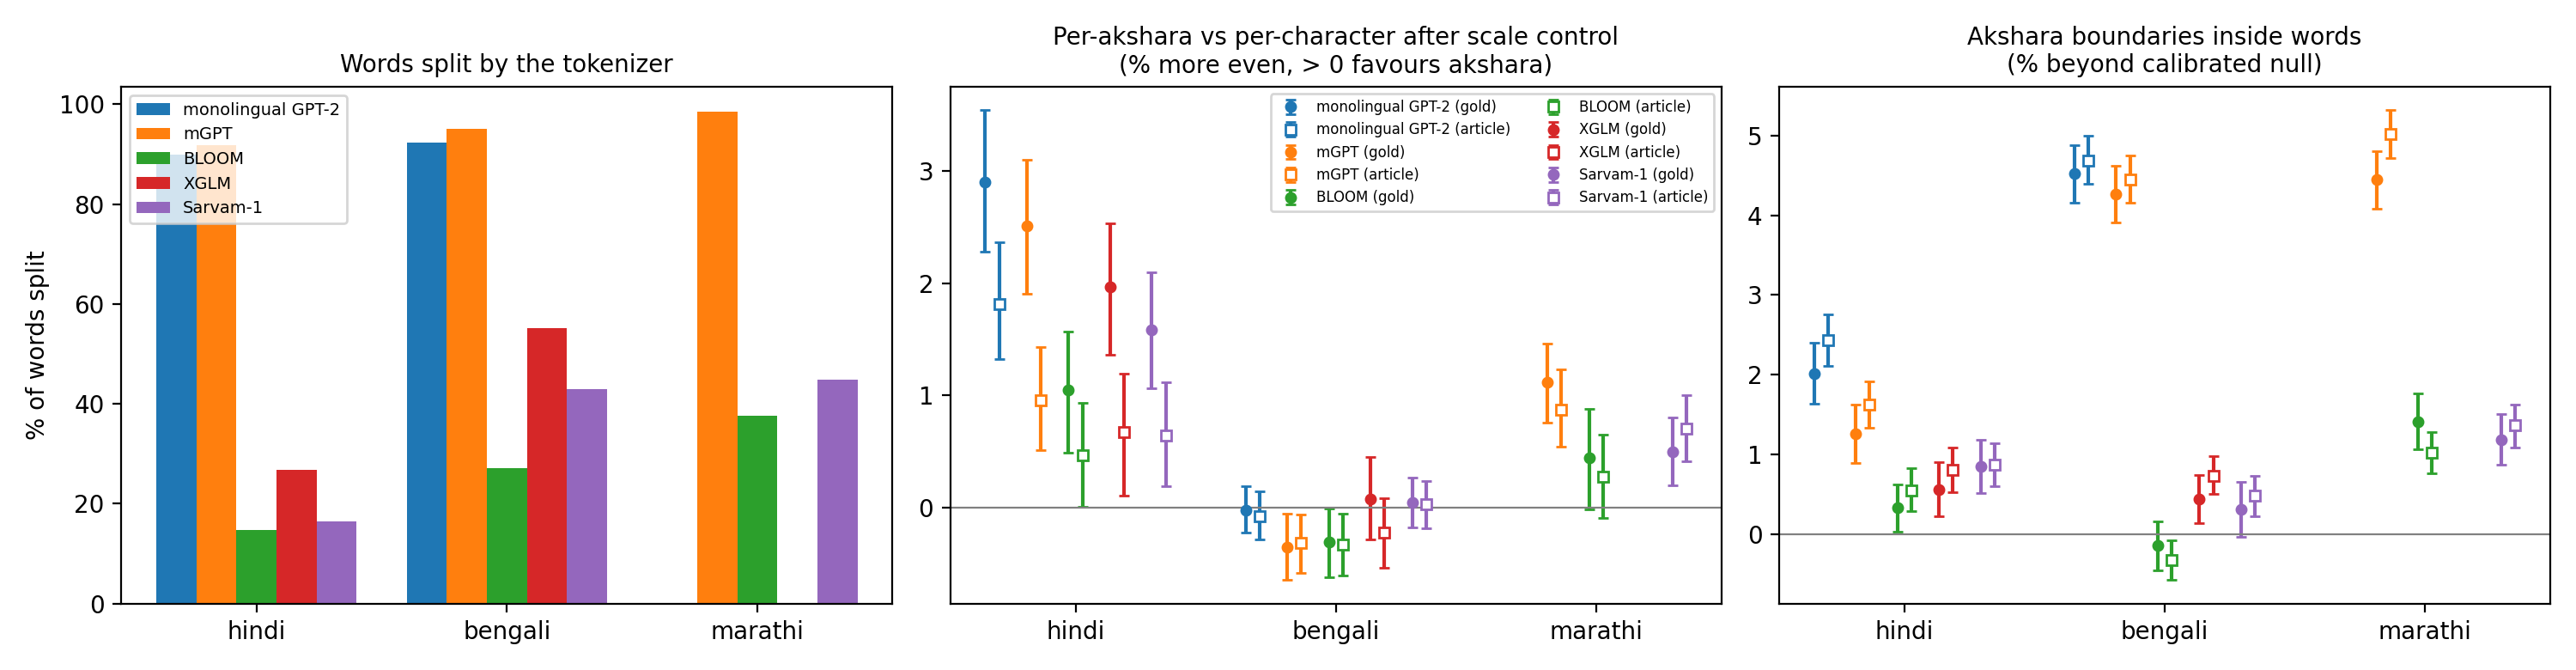

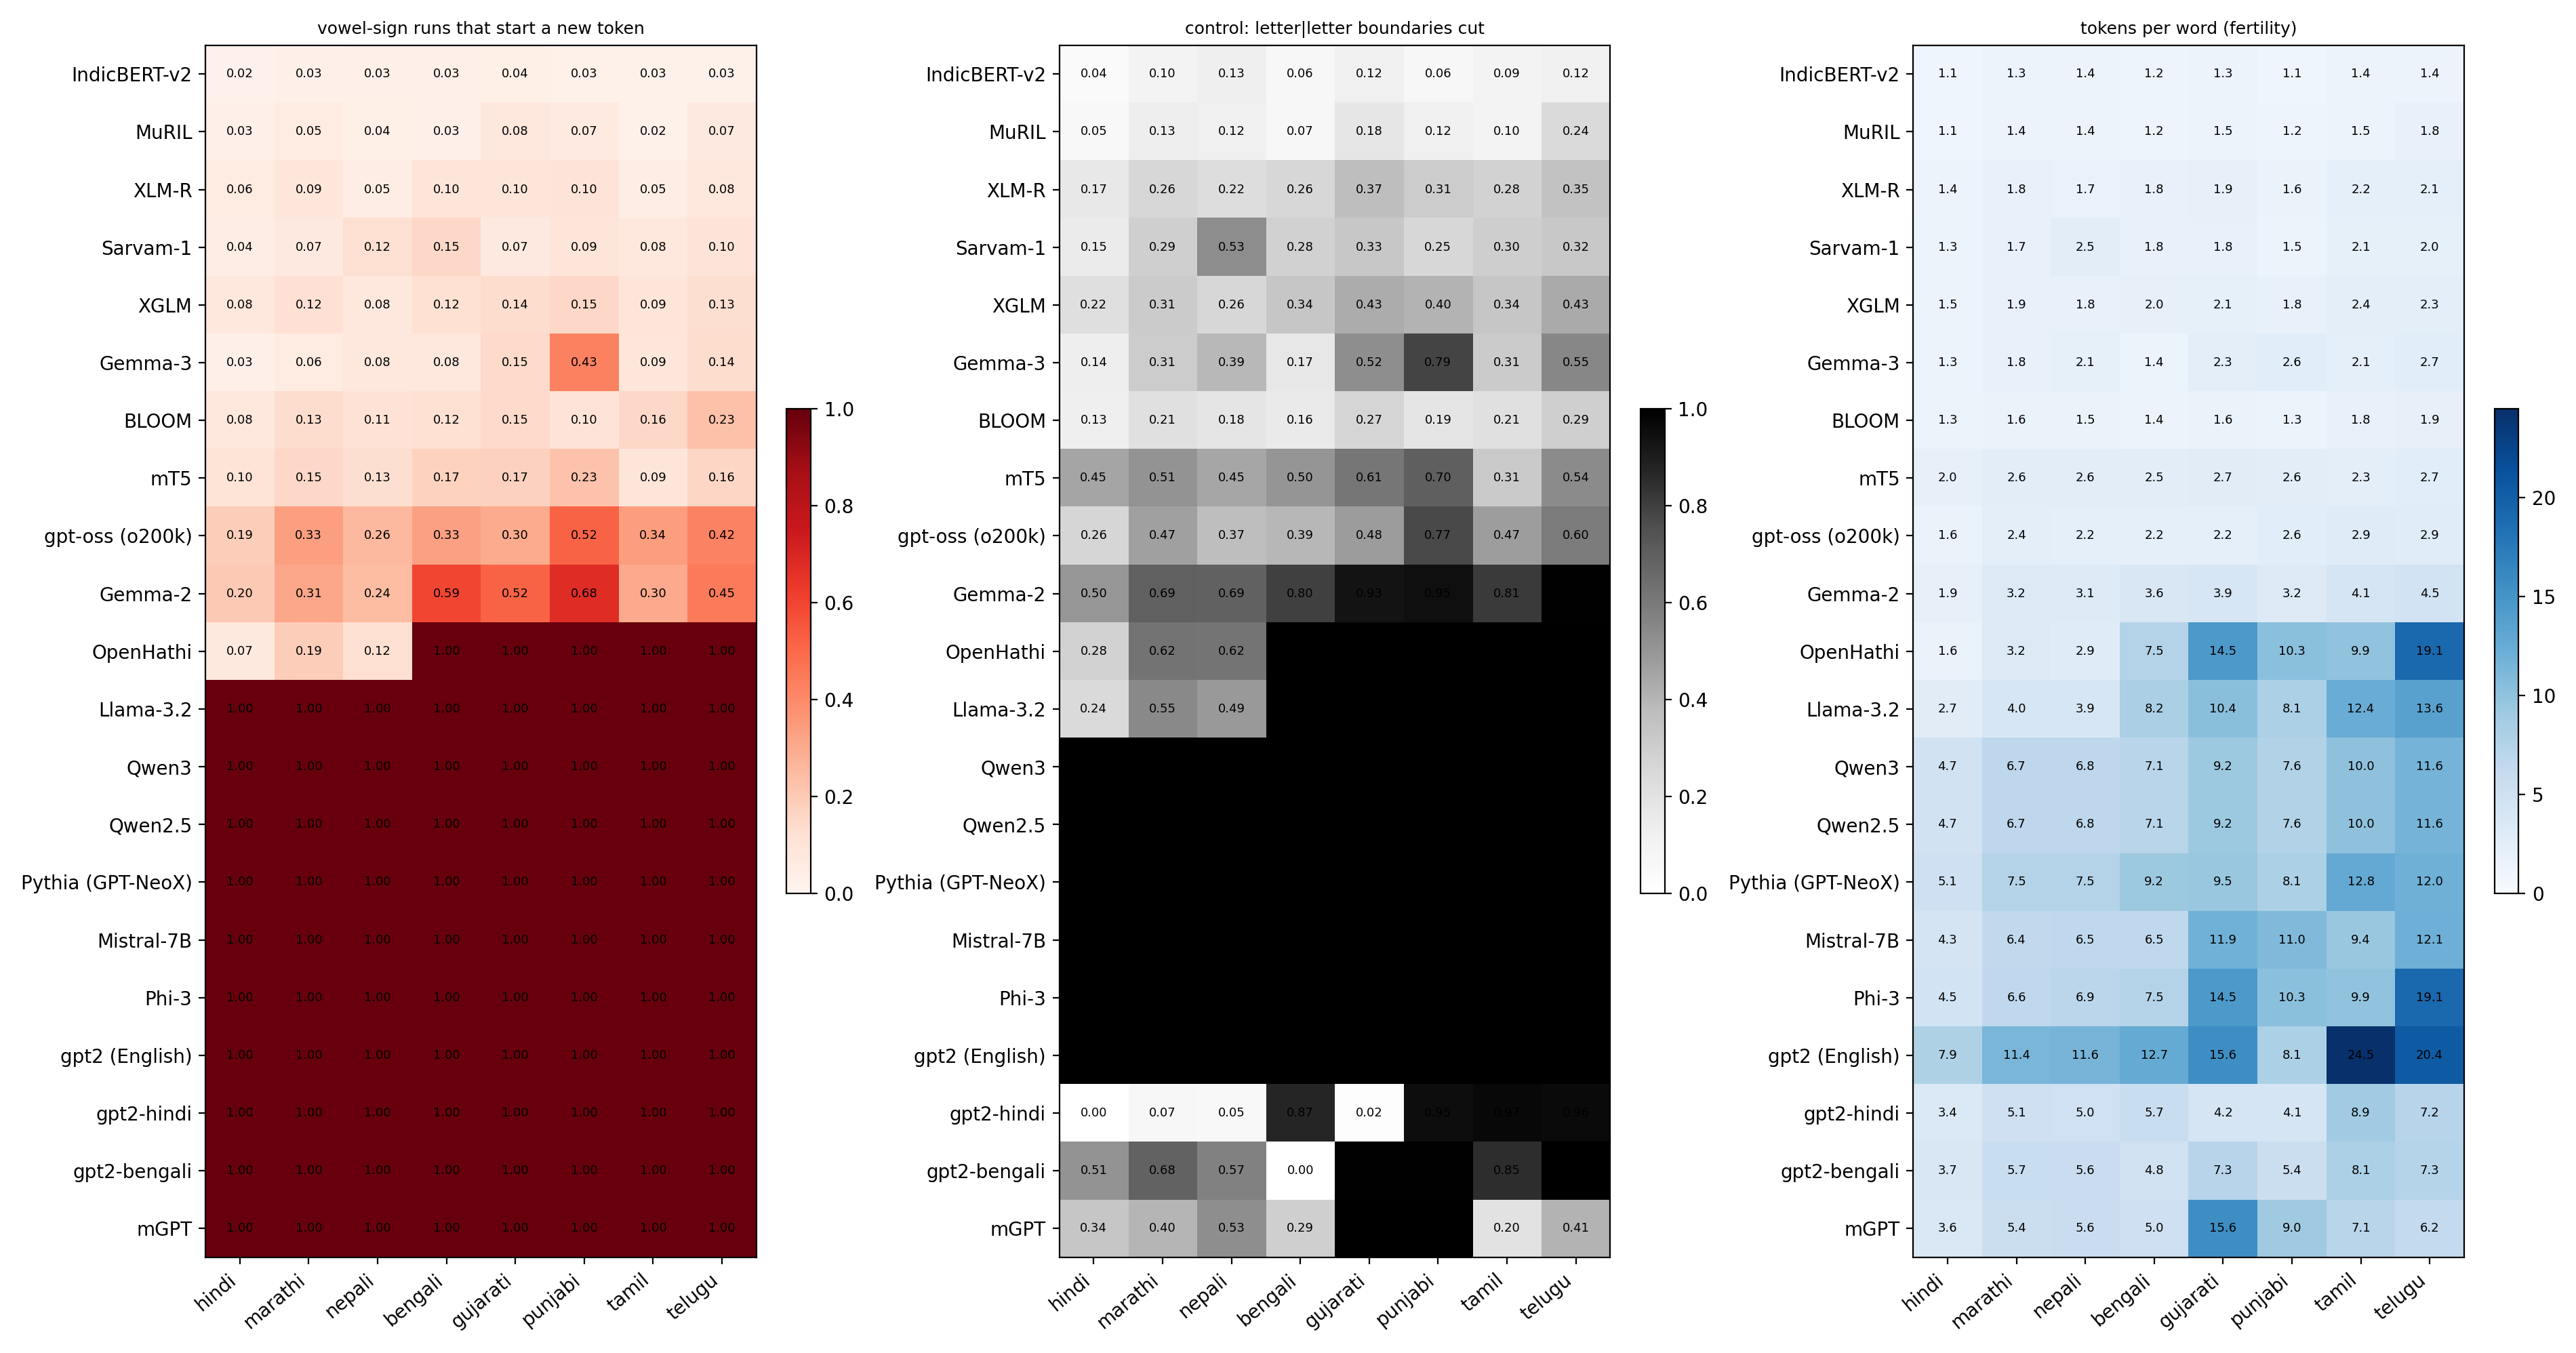


Everything (all languages, audit, FINAL/) zipped to /kaggle/working/mtp_final_results.zip


In [11]:
# ============================== STEP 4: final findings (no GPU) ==============================
import mtp_report; importlib.reload(mtp_report)
from IPython.display import Markdown, Image, display
rep = mtp_report.build_report(BASE_DIR, LANGS)
r = rep["repro"]; done = r[r.status != "not computed"]
print(f"Reproducibility: {int((done.status == 'match').sum())}/{len(done)} reference values match "
      f"({int((r.status == 'not computed').sum())} not computed)")
if (done.status == "DIFFERS").any():
    print(done[done.status == "DIFFERS"].to_string(index=False))
md = open(os.path.join(rep["out"], "FINAL_FINDINGS.md"), encoding="utf-8").read()
display(Markdown(md.split("## Tables")[0]))
display(Image(os.path.join(rep["out"], "fig_cross_language.png")))
if os.path.exists(os.path.join(rep["out"], "fig_tokenizer_audit.png")):
    display(Image(os.path.join(rep["out"], "fig_tokenizer_audit.png"), width=1100))
shutil.make_archive(os.path.join(CODE_DIR, "mtp_final_results"), "zip", BASE_DIR)
print("\nEverything (all languages, audit, FINAL/) zipped to", os.path.join(CODE_DIR, "mtp_final_results.zip"))


## Step 5: does the approach predict native readers? (MECO Hindi eye-tracking)
Native ruler check and psychological significance: word length in aksharas vs characters vs tokens, surprisal predictive power (corrected vs raw), and reading-time errors for split words (Nguyen & Arehalli 2026, Exp. 3).

  -> release 2.0
  -> version 2.1
  -> wave 2
  -> primary data
  -> eye tracking data
  files: [('00_readme-joint_data_trimmed variables.txt', 3866), ('joint_data_trimmed_wave2_version2.1.rda', 9766092), ('joint_readrate_wave2_version2.1.rda', 30456), ('joint_passage_trimmed_wave2_version2.1.rda', 120964), ('joint_sent_trimmed_wave2_version2.1.rda', 660196), ('joint_sac_trimmed_l1_wave2_version2.1.rda', 27812104), ('joint_fix_trimmed_l1_wave2_version2.1.rda', 52051800), ('00_readme-joint_fixed_trimmed variables.txt', 3867)]
  downloading joint_data_trimmed_wave2_version2.1.rda (10 MB)
  downloading joint_readrate_wave2_version2.1.rda (0 MB)
  downloading joint_sac_trimmed_l1_wave2_version2.1.rda (28 MB)

/kaggle/working/mtp_final/meco_data/joint_data_trimmed_wave2_version2.1.rda :: object 'joint.data'  rows=980,211  cols=42
   columns: ['subid', 'trialid', 'trialnum', 'itemid', 'cond', 'sentnum', 'wordnum', 'word', 'blink', 'skip', 'nrun', 'reread', 'nfix', 'refix', 'reg.in', 'reg.out

# MECO Hindi: reading-time analysis

Readers: 111 (hi_iiith, hi_iitk), passages: 12, analysed words: 2236. Main measure: gaze duration. Between-sample reliability: gaze r = 0.84, total r = 0.91, first_fix r = 0.47.

## A. Native ruler check

* Unique gain of akshara length over character length: +71.92 [+32.01, +100.69] (positive in 11/12 passages); character over akshara: +23.53 [-24.98, +57.42] (positive in 10/12). Regression: Nguyen & Arehalli's length x frequency formula. Without the interaction terms: akshara +39.45 vs character +33.16.

### All units side by side (word = whole word, no length information)

| unit | gain over a word-only model (frequency), x1000 | reading time per unit: CV vs akshara (> 0 = akshara more even) |
|---|---|---|
| word | 0 (reference) | -2.7% (p = 0.12) |
| character | +193.0 [+102.7, +262.0] (11/12) | -1.0% (p = 0.0016) |
| akshara | +241.4 [+181.0, +296.6] (11/12) | reference |
| token (gpt2-hindi) | +121.6 [+57.0, +183.9] (11/12) | +19.6% (p = 6e-20) |
| token (mGPT) | +149.7 [+94.6, +210.1] (11/12) | +16.0% (p = 6.3e-20) |
| token (bloom-560m) | +23.5 [-7.0, +54.3] (7/12) | -6.2% (p = 1.7e-07) |
| token (xglm-564M) | +29.6 [-11.8, +66.5] (8/12) | -2.8% (p = 0.00035) |
| token (sarvam-1) | +6.3 [-15.0, +27.4] (6/12) | -5.3% (p = 4.3e-06) |

### Word-level features (frequency, previous-word frequency, function word, punctuation, sentence-final, position in sentence, position in passage)

| comparison | gain x1000 [95% CI] | passages positive |
|---|---|---|
| all word-level features over intercept | +244.3 [+203.6, +278.1] | 12/12 |
| word feature: logfreq (drop-one) | +30.9 [+10.2, +48.6] | 10/12 |
| word feature: prev_logfreq (drop-one) | -1.2 [-3.5, +0.5] | 7/12 |
| word feature: func (drop-one) | +2.7 [+0.3, +5.6] | 9/12 |
| word feature: punct (drop-one) | +3.8 [-1.4, +9.0] | 8/12 |
| word feature: sent_final (drop-one) | +2.1 [-0.8, +5.2] | 8/12 |
| word feature: log_pos_sent (drop-one) | +0.2 [-3.2, +3.0] | 8/12 |
| word feature: log_pos_text (drop-one) | +13.7 [+8.2, +18.3] | 11/12 |
| character length over word-level features | +200.6 [+103.1, +272.3] | 11/12 |
| akshara length over word-level features | +254.1 [+190.8, +309.8] | 11/12 |
| visual width length over word-level features | +275.8 [+146.9, +367.9] | 11/12 |
| token (gpt2-hindi) length over word-level features | +130.5 [+65.2, +196.0] | 11/12 |
| token (mGPT) length over word-level features | +160.5 [+101.1, +228.3] | 11/12 |
| token (bloom-560m) length over word-level features | +41.9 [-0.8, +86.8] | 7/12 |
| token (xglm-564M) length over word-level features | +43.9 [-5.5, +93.7] | 8/12 |
| token (sarvam-1) length over word-level features | +16.8 [-8.9, +42.7] | 7/12 |
| akshara over word-level features + visual width | -2.3 [-7.0, +2.9] | 5/12 |
| visual width over word-level features + akshara | +19.5 [-55.5, +61.7] | 11/12 |
| akshara over word-level features + visual width + character | -1.8 [-6.9, +3.8] | 5/12 |
| akshara over word-level features + character | +75.7 [+38.2, +105.4] | 11/12 |
| character over word-level features + akshara | +22.2 [-25.1, +58.1] | 10/12 |
| word surprisal (gpt2-hindi) over word features + akshara length | +25.9 [+15.3, +39.0] | 11/12 |
| surprisal per akshara (gpt2-hindi) over word features + akshara length | +18.1 [+13.0, +24.3] | 12/12 |
| word surprisal (mGPT) over word features + akshara length | +29.1 [+14.2, +44.5] | 11/12 |
| surprisal per akshara (mGPT) over word features + akshara length | +24.1 [+17.8, +30.2] | 12/12 |
| word surprisal (bloom-560m) over word features + akshara length | +82.6 [+58.1, +117.2] | 12/12 |
| surprisal per akshara (bloom-560m) over word features + akshara length | +39.6 [+34.9, +45.1] | 12/12 |
| word surprisal (xglm-564M) over word features + akshara length | +87.8 [+55.5, +129.6] | 12/12 |
| surprisal per akshara (xglm-564M) over word features + akshara length | +45.2 [+36.5, +55.2] | 12/12 |
| word surprisal (sarvam-1) over word features + akshara length | +42.4 [+28.3, +56.7] | 11/12 |
| surprisal per akshara (sarvam-1) over word features + akshara length | +22.1 [+11.0, +30.2] | 11/12 |

### Replication within each Hindi sample (independent readers)

| sample | readers | comparison | gain x1000 [95% CI] | passages positive |
|---|---|---|---|---|
| hi_iiith | 54 | akshara over word-level features + character | +71.2 [+31.4, +102.3] | 11/12 |
| hi_iiith | 54 | character over word-level features + akshara | +30.0 [-14.7, +65.2] | 10/12 |
| hi_iiith | 54 | akshara over word-level features + visual width | -1.3 [-7.1, +4.9] | 4/12 |
| hi_iiith | 54 | word surprisal (gpt2-hindi) over word features + akshara length | +21.1 [+11.1, +32.0] | 10/12 |
| hi_iiith | 54 | word surprisal (mGPT) over word features + akshara length | +27.0 [+12.5, +40.9] | 10/12 |
| hi_iiith | 54 | word surprisal (bloom-560m) over word features + akshara length | +66.8 [+48.4, +88.7] | 12/12 |
| hi_iiith | 54 | word surprisal (xglm-564M) over word features + akshara length | +71.7 [+49.6, +97.6] | 12/12 |
| hi_iiith | 54 | word surprisal (sarvam-1) over word features + akshara length | +38.4 [+26.0, +51.8] | 11/12 |
| hi_iitk | 57 | akshara over word-level features + character | +51.6 [+28.2, +69.6] | 11/12 |
| hi_iitk | 57 | character over word-level features + akshara | +4.0 [-27.9, +25.0] | 9/12 |
| hi_iitk | 57 | akshara over word-level features + visual width | -3.2 [-12.0, +3.1] | 6/12 |
| hi_iitk | 57 | word surprisal (gpt2-hindi) over word features + akshara length | +20.8 [+12.3, +30.9] | 12/12 |
| hi_iitk | 57 | word surprisal (mGPT) over word features + akshara length | +19.0 [+8.9, +29.9] | 11/12 |
| hi_iitk | 57 | word surprisal (bloom-560m) over word features + akshara length | +71.6 [+47.3, +102.9] | 12/12 |
| hi_iitk | 57 | word surprisal (xglm-564M) over word features + akshara length | +75.3 [+43.3, +121.1] | 11/12 |
| hi_iitk | 57 | word surprisal (sarvam-1) over word features + akshara length | +32.1 [+21.1, +42.9] | 11/12 |

## B. Surprisal predictive power (held-out log-lik gain per word x1000, over length + frequency)

| model | tokenizer | raw | corrected | corrected − raw |
|---|---|---|---|---|
| gpt2-hindi | rule (cuts marks) | +19.15 [+8.03, +30.67] | +19.56 [+7.50, +32.58] | +0.41 [-0.87, +1.83] |
| mGPT | rule (cuts marks) | +18.07 [+3.07, +32.70] | +18.37 [+1.54, +33.57] | +0.30 [-1.02, +1.71] |
| bloom-560m | learned subwords | +93.51 [+67.57, +127.78] | +93.41 [+67.58, +126.15] | -0.09 [-0.86, +0.62] |
| xglm-564M | learned subwords | +97.04 [+61.37, +141.03] | +97.20 [+63.85, +142.84] | +0.16 [-2.46, +2.76] |
| sarvam-1 | learned subwords | +52.76 [+37.95, +68.34] | +53.35 [+39.68, +67.45] | +0.59 [-1.77, +2.96] |

## C. Split words (residual ms = observed − predicted)

| model | fit | unsplit | split, aligned | split, crosses akshara | note |
|---|---|---|---|---|---|
| gpt2-hindi | UNSPLIT | -0.4 [-5.0, +4.0] (n=227) | — | +22.7 [+15.7, +31.6] (n=2009) | UNSPLIT fit is trained on only 10% of words: it extrapolates, so read the FULL fit |
| gpt2-hindi | FULL | -5.0 [-9.5, +0.0] (n=227) | — | +0.4 [-5.2, +7.0] (n=2009) |  |
| mGPT | UNSPLIT | -0.3 [-5.8, +5.0] (n=187) | +34.0 [+8.5, +77.6] (n=40) | +74.0 [+58.1, +95.2] (n=2009) | UNSPLIT fit is trained on only 8% of words: it extrapolates, so read the FULL fit |
| mGPT | FULL | +0.0 [-4.1, +4.2] (n=187) | -24.5 [-41.6, -9.5] (n=40) | +0.2 [-5.3, +6.9] (n=2009) |  |
| bloom-560m | UNSPLIT | -0.0 [-4.4, +5.0] (n=1930) | +3.1 [-24.5, +39.0] (n=101) | +2.1 [-17.9, +28.6] (n=205) |  |
| bloom-560m | FULL | +0.8 [-3.3, +5.7] (n=1930) | -4.2 [-29.7, +24.5] (n=101) | -4.5 [-24.1, +19.4] (n=205) |  |
| xglm-564M | UNSPLIT | +0.1 [-3.8, +4.1] (n=1628) | -31.0 [-43.7, -13.6] (n=331) | +4.5 [-15.6, +26.7] (n=277) |  |
| xglm-564M | FULL | +0.8 [-3.2, +5.1] (n=1628) | -18.3 [-29.6, -2.8] (n=331) | +17.9 [-2.6, +42.0] (n=277) |  |
| sarvam-1 | UNSPLIT | +0.1 [-5.0, +6.2] (n=1899) | -12.3 [-33.4, +8.7] (n=172) | -15.1 [-45.5, +22.7] (n=165) |  |
| sarvam-1 | FULL | +1.2 [-3.6, +6.8] (n=1899) | -4.4 [-21.3, +12.8] (n=172) | -8.1 [-37.4, +30.9] (n=165) |  |

Log-likelihood gains are leave-one-passage-out; CIs bootstrap over passages (v9; word-level CIs are in the CSVs as ci_lo_word/ci_hi_word). With 12 passages, 'positive in k/12 passages' shows how consistent an effect is across texts.

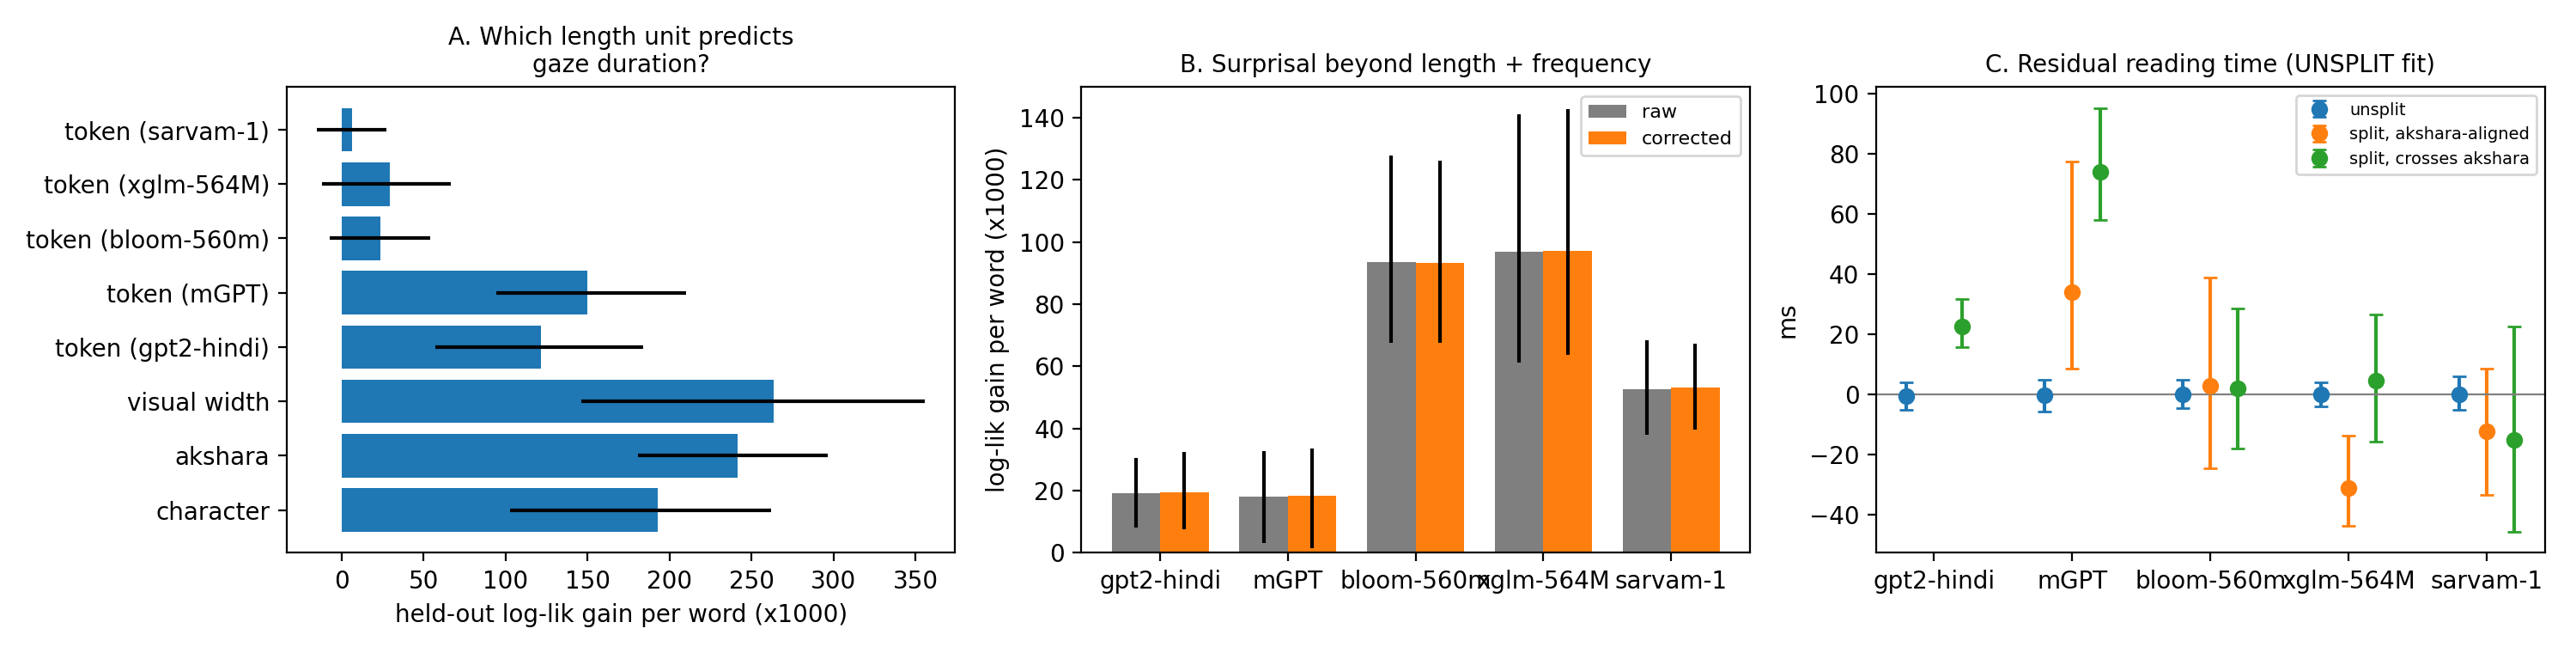

results zip updated: /kaggle/working/mtp_final_results.zip


In [12]:
# ============================== STEP 5: MECO Hindi reading times (GPU) ==============================
# Psychological significance: does my approach predict how native Hindi readers read?
# Data: MECO L1 Wave 2 (Siegelman et al., 2025), OSF https://osf.io/3527a/ (CC BY 4.0).
import requests
MECO_DIR = os.path.join(BASE_DIR, "meco_data")
MECO_SCRIPT = os.path.join(CODE_DIR, "mtp_meco.py")

def _osf_list(url):
    items = []
    while url:
        r = requests.get(url, timeout=60); r.raise_for_status(); j = r.json()
        items += j["data"]; url = j["links"].get("next")
    return items

def _osf_children(item):
    return _osf_list(item["relationships"]["files"]["links"]["related"]["href"])

def download_meco(dest):
    """Walk OSF: release 2.x / version (latest) / wave 2 / primary data / eye tracking data,
    and download the word-level report(s). Prints the folder contents so you can check."""
    os.makedirs(dest, exist_ok=True)
    items = _osf_list("https://api.osf.io/v2/nodes/3527a/files/osfstorage/")
    for step in [["release 2"], ["version"], ["wave 2"], ["primary data"], ["eye tracking", "eye-tracking"]]:
        cands = [it for it in items if it["attributes"]["kind"] == "folder"
                 and any(k in it["attributes"]["name"].lower() for k in step)]
        if not cands:
            raise RuntimeError(f"OSF folder matching {step} not found; available: "
                               f"{[it['attributes']['name'] for it in items]}")
        pick = sorted(cands, key=lambda it: it["attributes"]["name"])[-1]     # latest version
        print("  ->", pick["attributes"]["name"]); items = _osf_children(pick)
    files = []
    for it in items:                                         # files here and one level down
        if it["attributes"]["kind"] == "file": files.append(it)
        else: files += [x for x in _osf_children(it) if x["attributes"]["kind"] == "file"]
    print("  files:", [(f["attributes"]["name"], f["attributes"].get("size")) for f in files])
    want = [f for f in files if f["attributes"]["name"].lower().endswith((".rda", ".rdata", ".csv"))
            and "word" in f["attributes"]["name"].lower()]
    if not want:
        want = [f for f in files if f["attributes"]["name"].lower().endswith((".rda", ".rdata", ".csv"))
                and not any(k in f["attributes"]["name"].lower() for k in ["fix", "sent", "passage", "comp"])]
    for f in want:
        name = f["attributes"]["name"]; out = os.path.join(dest, name)
        if os.path.exists(out): print("  have", name); continue
        print("  downloading", name, f"({(f['attributes'].get('size') or 0) / 1e6:.0f} MB)")
        with requests.get(f["links"]["download"], stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(out, "wb") as fh:
                for chunk in r.iter_content(1 << 20): fh.write(chunk)
    return [os.path.join(dest, f["attributes"]["name"]) for f in want]

def run_meco(inspect=False):
    cmd = [sys.executable, "-u", MECO_SCRIPT, "--meco", MECO_DIR, "--base", BASE_DIR] + (["--inspect"] if inspect else [])
    with open(os.path.join(BASE_DIR, "meco_log.txt"), "a", encoding="utf-8") as log:
        p = subprocess.Popen(cmd, cwd=CODE_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, bufsize=1, env={**os.environ, "PYTHONPATH": CODE_DIR})
        for line in p.stdout: log.write(line); print(line, end="", flush=True)
        if p.wait() != 0: raise RuntimeError(f"MECO step failed; see {BASE_DIR}/meco_log.txt")

meco_done = os.path.exists(os.path.join(BASE_DIR, "meco", "meco_summary.json"))
if RUN_MECO and (not meco_done or "meco" in FORCE_RERUN):
    have = glob.glob(os.path.join(MECO_DIR, "**", "*.rda"), recursive=True) + \
           glob.glob(os.path.join(MECO_DIR, "**", "*.csv"), recursive=True)
    if not have:
        print("Downloading MECO Wave 2 word-level data from OSF …")
        try:
            download_meco(MECO_DIR)
        except Exception as e:
            print(f"\nAutomatic download failed ({e}).\nDownload manually: https://osf.io/3527a/ → Files → "
                  "release 2.0 → version (latest) → wave 2 → primary data → eye tracking data → the word-level "
                  f"report (.rda), and put it in {MECO_DIR}")
            raise
    run_meco(inspect=True)        # shows what was found; stop here and check if anything looks wrong
    run_meco(inspect=False)
else:
    print("MECO:", "using existing results" if meco_done else "skipped (RUN_MECO = False)")
if os.path.exists(os.path.join(BASE_DIR, "meco", "MECO_FINDINGS.md")):
    from IPython.display import Markdown, Image, display
    display(Markdown(open(os.path.join(BASE_DIR, "meco", "MECO_FINDINGS.md"), encoding="utf-8").read()))
    display(Image(os.path.join(BASE_DIR, "meco", "fig_meco.png")))
    shutil.make_archive(os.path.join(CODE_DIR, "mtp_final_results"), "zip", BASE_DIR)
    print("results zip updated:", os.path.join(CODE_DIR, "mtp_final_results.zip"))


## Reading the results
* `FINAL/FINAL_FINDINGS.md`: each finding with a **per-language** verdict (*holds* = every test in that language passes, *mixed*, *not supported*, *inconclusive (low power)*), the number of tests passed, and the tables.
* `FINAL/table_scale_control.csv`: per-akshara vs per-character evenness at exponent 1, with characters matched to aksharas' spread (`gamma`), and with each unit's best exponent (`best`, primary).
* `FINAL/reproducibility_check.csv`: every reference value next to this run's value (only meaningful for a clean run).
* `run_<language>/results/`: all per-language tables (`rq2_*.csv`), `run_meta.json` (incl. the model revisions used), `plots/` and `log.txt`.
* `meco/MECO_FINDINGS.md`: reading-time results; CIs are bootstrapped over passages.
* `audit/`: the tokenizer audit tables and heatmap.
